In [ ]:
#Base imports
import ee
import csv
import pandas as pd
from google.colab import drive

#Mount GDrive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%%capture
!pip install osmnx
!pip install rasterio geopandas contextily shapely pyproj fiona rtree h3 optuna

Abidjan

In [ ]:
# =============================================================================
# REVISED DIFFERENTIAL-SPREAD DV GENERATION
# 500m² FLOOR + SIZE-SCALED RADIUS (200m-2km) + STEEPENED DECAY (H_HALF=0.30)
# BLOCK 1 — CONFIGURATION, KMZ LOADING, SITE PREPROCESSING & KD-TREE
# =============================================================================

import os
import zipfile
import tempfile
import warnings
import fiona
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

# --- PER-CITY PARAMETERS (extend this dict as each city is added) -----------
# EPSG = city's confirmed UTM zone; BETA = city's confirmed mass exponent
# (both preserved from each city's original script — NOT part of the redesign)

CITY_PARAMS = {
    "Abidjan": {"EPSG": 32630, "BETA": 0.60},
    # "Accra":   {"EPSG": 32630, "BETA": 0.44},
    # add remaining 8 cities here as their originals are confirmed
}

# --- CONFIGURATION -------------------------------------------------------

CITY = "Abidjan"
YEAR = 2024

EPSG = CITY_PARAMS[CITY]["EPSG"]
BETA = CITY_PARAMS[CITY]["BETA"]

KMZ_FILE  = f"/content/drive/MyDrive/Paper_3/Sites/{YEAR}/{CITY}/{CITY}_{YEAR}.kmz"
GRID_CSV  = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets/{CITY.lower()}_grid30m_master_merged_withDV.csv"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"

OUT_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
os.makedirs(OUT_DIR, exist_ok=True)
OUTPUT_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_{YEAR}_revised.csv")

# --- LOCKED DESIGN PARAMETERS (same for all cities/years) -------------------

MIN_AREA_M2    = 500.0
MIN_RADIUS_M   = 200.0
MAX_RADIUS_M   = 2000.0
CAP_PERCENTILE = 99
H_HALF         = 0.30
TAU            = 1.0

# --- CITY-SPECIFIC AREA CAP (pooled 2016+2024, from site CSVs) --------------

print("=" * 70)
print(f"Computing area cap for {CITY} (pooled 2016+2024)...")
print("=" * 70)

areas_pooled = []
for y in [2016, 2024]:
    sites_csv = pd.read_csv(f"{SITES_DIR}/{y}/{CITY}/{CITY}_{y}_sites.csv")
    sites_csv = sites_csv.dropna(subset=["area"])
    sites_csv = sites_csv[sites_csv["area"] >= MIN_AREA_M2]
    areas_pooled.extend(sites_csv["area"].values)

AREA_CAP_M2 = np.percentile(areas_pooled, CAP_PERCENTILE)
print(f"{CITY}: n={len(areas_pooled):,} qualifying sites (both years), "
      f"p{CAP_PERCENTILE} area cap = {AREA_CAP_M2:,.1f} m² ({AREA_CAP_M2/10000:.2f} ha)")

# --- LOAD & PROJECT KMZ (target year's own site geometries) -----------------

print("\n" + "=" * 70)
print("Loading KMZ...")
print("=" * 70)

tmpdir = tempfile.mkdtemp()
with zipfile.ZipFile(KMZ_FILE, "r") as z:
    z.extractall(tmpdir)

kml_files = [
    os.path.join(root, f)
    for root, _, files in os.walk(tmpdir)
    for f in files if f.lower().endswith(".kml")
]
if not kml_files:
    raise RuntimeError("No KML file found inside KMZ.")

kml_file = kml_files[0]
print(f"KML found: {kml_file}")

fiona.drvsupport.supported_drivers["KML"] = "rw"
sites = gpd.read_file(kml_file, driver="KML").set_geometry("geometry")

if sites.crs is None:
    sites = sites.set_crs(4326)
sites = sites.to_crs(EPSG)
print(f"Loaded {len(sites)} geometries, projected to EPSG:{EPSG}")

# --- EXPLODE, FILTER TO POLYGONS, COMPUTE AREA -------------------------

sites = sites.explode(index_parts=False).reset_index(drop=True)
sites = sites[sites.geometry.type.isin(["Polygon", "MultiPolygon"])].copy()
print(f"Polygon features: {len(sites)}")
if len(sites) == 0:
    raise RuntimeError("No polygons found.")

sites["area_m2"] = sites.geometry.area
sites = sites[np.isfinite(sites["area_m2"]) & (sites["area_m2"] > 0)].copy()
print(f"Valid polygons: {len(sites)}")

# --- 500 m² FLOOR -------------------------------------------------------

n_before_floor = len(sites)
sites = sites[sites["area_m2"] >= MIN_AREA_M2].copy()
print(f"Sites >= {MIN_AREA_M2:.0f} m²: {len(sites)} (dropped {n_before_floor - len(sites)} smaller sites)")
if len(sites) == 0:
    raise RuntimeError(f"No sites >= {MIN_AREA_M2:.0f} m² for {CITY} {YEAR}.")

# --- CENTROIDS -----------------------------------------------------------

sites["centroid"] = sites.geometry.centroid
site_pts = sites.set_geometry("centroid").copy()

site_xy = np.column_stack((site_pts.geometry.x.values, site_pts.geometry.y.values))
areas = site_pts["area_m2"].to_numpy(dtype=float)

# --- SIZE-SCALED RADII (200m-2km, city-specific p99 cap) -------------------

print("\nComputing size-scaled radii...")

capped_area = np.minimum(areas, AREA_CAP_M2)
score = (np.log(capped_area) - np.log(MIN_AREA_M2)) / (np.log(AREA_CAP_M2) - np.log(MIN_AREA_M2))
r_j = MIN_RADIUS_M + (MAX_RADIUS_M - MIN_RADIUS_M) * score

lambda_j = np.log(2.0) / (H_HALF * r_j)
K_j = (lambda_j ** 2) / (2.0 * np.pi)
mass_j = np.power(np.maximum(areas, 1.0), BETA)

# --- KD-TREE ---------------------------------------------------------------

tree = cKDTree(site_xy)
R_QUERY = TAU * np.max(r_j)
print("\nKD Tree constructed.")

# --- LOAD GRID COORDINATES --------------------------------------------------

print("\nLoading grid coordinates...")

grid = pd.read_csv(GRID_CSV, usecols=["grid_point", "longitude", "latitude"]).dropna()
print(f"Grid points: {len(grid):,}")

grid_gdf = gpd.GeoDataFrame(
    grid,
    geometry=gpd.points_from_xy(grid.longitude, grid.latitude),
    crs=4326
).to_crs(EPSG)

points_xy = np.column_stack((grid_gdf.geometry.x.values, grid_gdf.geometry.y.values))

# --- DIAGNOSTICS -------------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)
print(f"City / year                : {CITY} {YEAR}")
print(f"EPSG / BETA (per-city)     : {EPSG} / {BETA}")
print(f"Min area / min radius      : {MIN_AREA_M2:.0f} m² / {MIN_RADIUS_M:.0f} m")
print(f"Area cap (p{CAP_PERCENTILE}) / max radius : {AREA_CAP_M2:,.1f} m² / {MAX_RADIUS_M:.0f} m")
print(f"H_HALF / TAU                : {H_HALF} / {TAU}")
print(f"Sites retained (>= floor)   : {len(site_pts):,}")
print(f"Grid points                 : {len(points_xy):,}")
print(f"Mean site area (m²)         : {areas.mean():.2f}")
print(f"Median site area (m²)       : {np.median(areas):.2f}")
print("\nSize-scaled radius summary (m)")
print(pd.Series(r_j).describe())
print(f"\nMaximum search radius: {R_QUERY:.2f} m")
print(f"\nOutput will be saved to:\n{OUTPUT_CSV}")
print("\nBlock 1 completed successfully. Proceed to Block 2.")

Computing area cap for Abidjan (pooled 2016+2024)...
Abidjan: n=155 qualifying sites (both years), p99 area cap = 33,786.6 m² (3.38 ha)

Loading KMZ...
KML found: /tmp/tmpaklvab23/doc.kml
Loaded 630 geometries, projected to EPSG:32630
Polygon features: 630
Valid polygons: 630
Sites >= 500 m²: 92 (dropped 538 smaller sites)

Computing size-scaled radii...

KD Tree constructed.

Loading grid coordinates...
Grid points: 144,026

SUMMARY
City / year                : Abidjan 2024
EPSG / BETA (per-city)     : 32630 / 0.6
Min area / min radius      : 500 m² / 200 m
Area cap (p99) / max radius : 33,786.6 m² / 2000 m
H_HALF / TAU                : 0.3 / 1.0
Sites retained (>= floor)   : 92
Grid points                 : 144,026
Mean site area (m²)         : 2671.04
Median site area (m²)       : 915.33

Size-scaled radius summary (m)
count      92.000000
mean      530.607283
std       316.846584
min       204.849176
25%       298.586627
50%       458.229270
75%       664.049137
max      2000.00000

In [ ]:
# =============================================================================
# BLOCK 2 — COMPUTE DIFFERENTIAL-SPREAD DV AT EVERY 30 m GRID POINT + SAVE
# =============================================================================

import time

print("=" * 70)
print("Computing DV at 30 m grid points...")
print("=" * 70)

t0 = time.time()

N = len(points_xy)
DV_pts = np.zeros(N, dtype=np.float64)
overlap_pts = np.zeros(N, dtype=np.int16)

BATCH_SIZE = 5000
print(f"Grid points : {N:,}")
print(f"Batch size  : {BATCH_SIZE:,}")
print(f"Total batches: {int(np.ceil(N / BATCH_SIZE))}")

for start in range(0, N, BATCH_SIZE):
    end = min(start + BATCH_SIZE, N)
    batch_points = points_xy[start:end]

    neighbour_lists = tree.query_ball_point(batch_points, r=R_QUERY)

    for i, neighbours in enumerate(neighbour_lists):
        if len(neighbours) == 0:
            continue

        pt = batch_points[i]
        cand_xy = site_xy[neighbours]

        dx = cand_xy[:, 0] - pt[0]
        dy = cand_xy[:, 1] - pt[1]
        d = np.sqrt(dx * dx + dy * dy)

        r_local = r_j[neighbours]
        keep = d <= (TAU * r_local)
        if not np.any(keep):
            continue

        d = d[keep]
        lam = lambda_j[neighbours][keep]
        K = K_j[neighbours][keep]
        mass = mass_j[neighbours][keep]

        contrib = mass * K * np.exp(-lam * d)
        DV_pts[start + i] = contrib.sum()
        overlap_pts[start + i] = keep.sum()

    processed = end
    pct = processed / N * 100
    elapsed = time.time() - t0
    rate = processed / elapsed
    remaining = (N - processed) / rate if rate > 0 else np.nan
    print(f"{processed:>8,} / {N:,} ({pct:5.1f}%)   Elapsed: {elapsed:6.1f}s   ETA: {remaining:6.1f}s")

print("\nFinished DV computation.")

DV_log = np.log1p(DV_pts)

print(f"Non-zero grid points : {(DV_pts>0).sum():,}")
print(f"Maximum overlap      : {overlap_pts.max()}")
print(f"Maximum DV           : {DV_pts.max():.6f}")
print(f"Mean DV              : {DV_pts.mean():.6f}")
print(f"Median DV            : {np.median(DV_pts):.6f}")

print("\n" + "=" * 70)
print("Saving output...")
print("=" * 70)

out_df = pd.DataFrame({
    "grid_point": grid["grid_point"].values,
    "longitude": grid["longitude"].values,
    "latitude": grid["latitude"].values,
    "DV_hex_diffspread": DV_pts,
    "DV_log1p": DV_log,
    "n_sites": overlap_pts
}).sort_values("grid_point").reset_index(drop=True)

os.makedirs(OUT_DIR, exist_ok=True)
out_df.to_csv(OUTPUT_CSV, index=False)

runtime = time.time() - t0
pct_list = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

print("\n" + "=" * 70)
print("OUTPUT SUMMARY")
print("=" * 70)
print(f"Output file:\n{OUTPUT_CSV}\n")
print(f"Rows written                : {len(out_df):,}")
print(f"Non-zero DV                 : {(out_df.DV_hex_diffspread>0).sum():,}")
print(f"Zero DV                     : {(out_df.DV_hex_diffspread==0).sum():,}")
print(f"Maximum contributing sites  : {out_df.n_sites.max()}")
print(f"Mean contributing sites     : {out_df.n_sites[out_df.n_sites>0].mean():.2f}")

print("\nDV summary")
print(out_df["DV_hex_diffspread"].describe(percentiles=pct_list))
print("\nDV_log1p summary")
print(out_df["DV_log1p"].describe(percentiles=pct_list))

print(f"\nProcessing time : {runtime:.1f} seconds")
print("\n✓ Revised DV successfully generated.")
print(f"\nSaved to:\n{OUTPUT_CSV}")

Computing DV at 30 m grid points...
Grid points : 144,026
Batch size  : 5,000
Total batches: 29
   5,000 / 144,026 (  3.5%)   Elapsed:    0.0s   ETA:    0.2s
  10,000 / 144,026 (  6.9%)   Elapsed:    0.0s   ETA:    0.4s
  15,000 / 144,026 ( 10.4%)   Elapsed:    0.1s   ETA:    1.0s
  20,000 / 144,026 ( 13.9%)   Elapsed:    0.2s   ETA:    1.5s
  25,000 / 144,026 ( 17.4%)   Elapsed:    0.4s   ETA:    1.7s
  30,000 / 144,026 ( 20.8%)   Elapsed:    0.5s   ETA:    2.0s
  35,000 / 144,026 ( 24.3%)   Elapsed:    0.7s   ETA:    2.1s
  40,000 / 144,026 ( 27.8%)   Elapsed:    0.8s   ETA:    2.0s
  45,000 / 144,026 ( 31.2%)   Elapsed:    0.8s   ETA:    1.9s
  50,000 / 144,026 ( 34.7%)   Elapsed:    0.9s   ETA:    1.8s
  55,000 / 144,026 ( 38.2%)   Elapsed:    1.0s   ETA:    1.7s
  60,000 / 144,026 ( 41.7%)   Elapsed:    1.1s   ETA:    1.6s
  65,000 / 144,026 ( 45.1%)   Elapsed:    1.2s   ETA:    1.4s
  70,000 / 144,026 ( 48.6%)   Elapsed:    1.3s   ETA:    1.3s
  75,000 / 144,026 ( 52.1%)   Elapse

Loading CSV...
Source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Abidjan/abidjan_grid30m_DV_2024_revised.csv
UTM: EPSG:32630


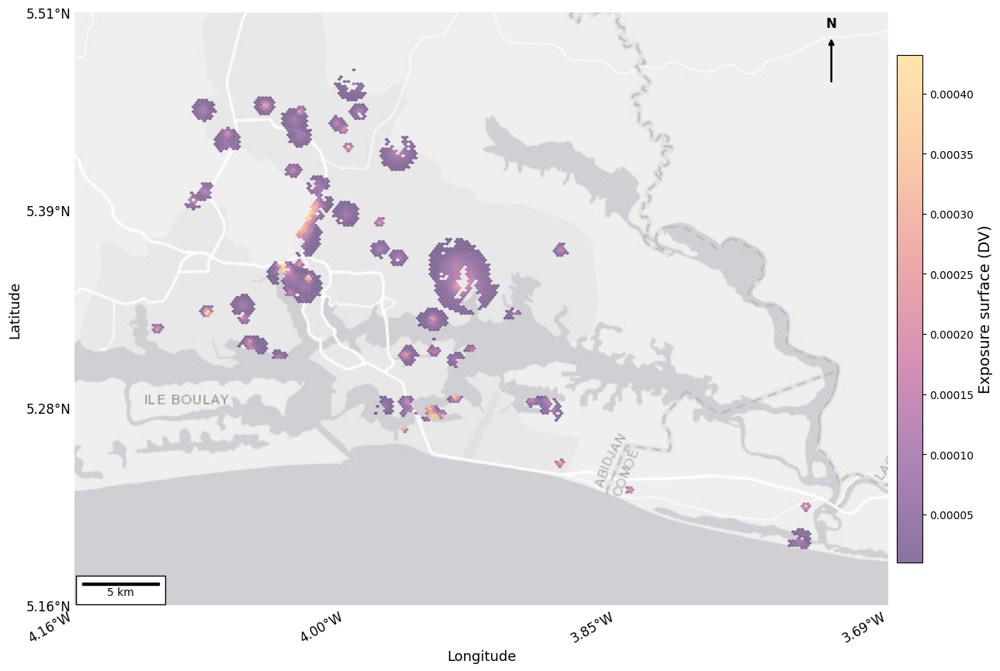


EXPOSURE SURFACE COMPLETE
City / year          : Abidjan 2024
Grid points plotted  : 16,162
99th percentile DV   : 0.000432
Output figure        :
/content/drive/MyDrive/Paper_3/Processing/DV/Revised/Abidjan/Abidjan_Exposure_Surface_2024_revised.png


In [ ]:
# =============================================================================
# EXPOSURE SURFACE VISUALIZATION (REVISED DV)
# =============================================================================

import os
import math
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.font_manager as fm
import contextily as ctx
from pyproj import CRS, Transformer
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

warnings.filterwarnings("ignore")

# =============================================================================
# CONFIG
# =============================================================================
CITY = "Abidjan"
YEAR = 2024
IN_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
CSV = os.path.join(IN_DIR, f"{CITY.lower()}_grid30m_DV_{YEAR}_revised.csv")
OUT_DIR = IN_DIR
os.makedirs(OUT_DIR, exist_ok=True)
OUT_FIG = os.path.join(OUT_DIR, f"{CITY}_Exposure_Surface_{YEAR}_revised.png")
FIGSIZE = (13, 13)
DPI = 300

# =============================================================================
# COLOURMAP
# =============================================================================
exposure_cmap = mcolors.LinearSegmentedColormap.from_list(
    "Exposure",
    ["#2b004f", "#6a1f7a", "#b63679", "#e16462", "#f4a261", "#ffd166"],
    N=256
)

# =============================================================================
# CRS HELPERS
# =============================================================================
CRS_WEB = CRS.from_epsg(3857)
CRS_WGS = CRS.from_epsg(4326)

def utm_epsg(lon, lat):
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"

# =============================================================================
# NORTH ARROW
# =============================================================================
def add_north_arrow(ax):
    ax.annotate("", xy=(0.93, 0.96), xytext=(0.93, 0.88), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"))
    ax.text(0.93, 0.97, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=12, fontweight="bold")

# =============================================================================
# SCALE BAR
# =============================================================================
def add_scalebar(ax):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(ax.transData, 5000, "5 km", "lower left", pad=0.6,
                                color="black", frameon=True, size_vertical=150,
                                fontproperties=fontprops)
    ax.add_artist(scalebar)

# =============================================================================
# LAT/LON TICKS
# =============================================================================
def format_lon(x):
    return f"{abs(x):.2f}°{'E' if x >= 0 else 'W'}"

def format_lat(y):
    return f"{abs(y):.2f}°{'N' if y >= 0 else 'S'}"

def add_latlon_ticks(ax):
    transformer = Transformer.from_crs(CRS_WEB, CRS_WGS, always_xy=True)
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    xticks = np.linspace(xmin, xmax, 4)
    yticks = np.linspace(ymin, ymax, 4)
    yc = (ymin + ymax) / 2
    xc = (xmin + xmax) / 2
    lons = [transformer.transform(x, yc)[0] for x in xticks]
    lats = [transformer.transform(xc, y)[1] for y in yticks]
    ax.set_xticks(xticks)
    ax.set_xticklabels([format_lon(i) for i in lons], fontsize=12, rotation=30, ha="right")
    ax.set_yticks(yticks)
    ax.set_yticklabels([format_lat(i) for i in lats], fontsize=12)
    ax.set_xlabel("Longitude", fontsize=13)
    ax.set_ylabel("Latitude", fontsize=13)

# =============================================================================
# LOAD
# =============================================================================
print("Loading CSV...")
print(f"Source: {CSV}")
df = pd.read_csv(CSV)
required = ["longitude", "latitude", "DV_log1p"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")
epsg = utm_epsg(df.longitude.mean(), df.latitude.mean())
print("UTM:", epsg)

# =============================================================================
# PROJECT
# =============================================================================
gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude),
                        crs="EPSG:4326").to_crs(epsg)
gdf["DV_raw"] = np.expm1(gdf["DV_log1p"])
gdf = gdf.to_crs(3857)

# =============================================================================
# PREPARE SURFACE
# =============================================================================
nz = gdf[gdf["DV_raw"] > 0].copy()
q99 = nz["DV_raw"].quantile(0.99)
nz["DV_plot"] = nz["DV_raw"].clip(upper=q99)
if len(nz) > 120000:
    nz = nz.sample(120000, random_state=42)

# =============================================================================
# MAP EXTENT
# =============================================================================
xmin, ymin, xmax, ymax = nz.total_bounds
padx = (xmax - xmin) * 0.12
pady = (ymax - ymin) * 0.12

# =============================================================================
# PLOT
# =============================================================================
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.set_xlim(xmin - padx, xmax + padx)
ax.set_ylim(ymin - pady, ymax + pady)
ax.set_aspect("equal", adjustable="box")

# Esri WorldGrayCanvas replaces CartoDB.PositronNoLabels (Carto now requires an API key)
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas, attribution=False, zorder=0)

hb = ax.hexbin(nz.geometry.x.values, nz.geometry.y.values, C=nz["DV_plot"].values,
               reduce_C_function=np.mean, gridsize=180, mincnt=1, linewidths=0,
               alpha=0.55, cmap=exposure_cmap, zorder=5)

cbar = fig.colorbar(hb, ax=ax, fraction=0.03, pad=0.01)
cbar.set_label("Exposure surface (DV)", fontsize=14)

add_north_arrow(ax)
add_scalebar(ax)
add_latlon_ticks(ax)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(axis="both", which="both", length=0)

# =============================================================================
# SAVE
# =============================================================================
plt.tight_layout()
plt.savefig(OUT_FIG, dpi=DPI, bbox_inches="tight", facecolor="white")
plt.show()

print("\n" + "=" * 70)
print("EXPOSURE SURFACE COMPLETE")
print("=" * 70)
print(f"City / year          : {CITY} {YEAR}")
print(f"Grid points plotted  : {len(nz):,}")
print(f"99th percentile DV   : {q99:.6f}")
print(f"Output figure        :\n{OUT_FIG}")

2016

In [ ]:
# =============================================================================
# REVISED DIFFERENTIAL-SPREAD DV GENERATION (Abidjan 2016)
# 500m² FLOOR + SIZE-SCALED RADIUS (200m-2km) + STEEPENED DECAY (H_HALF=0.30)
# BLOCK 1 — CONFIGURATION, KMZ LOADING, SITE PREPROCESSING & KD-TREE
# =============================================================================

import os
import zipfile
import tempfile
import warnings
import fiona
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

# --- CONFIGURATION ------------------------------------------------------

CITY = "Abidjan"
YEAR = 2016

EPSG = 32630   # confirmed, matches Abidjan 2024
BETA = 0.60    # confirmed, matches Abidjan 2024

KMZ_FILE  = f"/content/drive/MyDrive/Paper_3/Sites/{YEAR}/{CITY}/{CITY}_{YEAR}.kmz"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"

OUT_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
os.makedirs(OUT_DIR, exist_ok=True)
OUTPUT_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_{YEAR}_revised.csv")

# 2016 reuses 2024's own REVISED output as the grid source (same grid_point set)
GRID_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_2024_revised.csv")
if not os.path.exists(GRID_CSV):
    raise RuntimeError(
        f"2024 revised output not found for {CITY} — run YEAR=2024 first, "
        f"since 2016 reuses its grid for cross-year consistency."
    )

# --- LOCKED DESIGN PARAMETERS (same for all cities/years) -------------------

MIN_AREA_M2    = 500.0
MIN_RADIUS_M   = 200.0
MAX_RADIUS_M   = 2000.0
CAP_PERCENTILE = 99
H_HALF         = 0.30
TAU            = 1.0

# --- CITY-SPECIFIC AREA CAP (pooled 2016+2024, from site CSVs) --------------

print("=" * 70)
print(f"Computing area cap for {CITY} (pooled 2016+2024)...")
print("=" * 70)

areas_pooled = []
for y in [2016, 2024]:
    sites_csv = pd.read_csv(f"{SITES_DIR}/{y}/{CITY}/{CITY}_{y}_sites.csv")
    sites_csv = sites_csv.dropna(subset=["area"])
    sites_csv = sites_csv[sites_csv["area"] >= MIN_AREA_M2]
    areas_pooled.extend(sites_csv["area"].values)

AREA_CAP_M2 = np.percentile(areas_pooled, CAP_PERCENTILE)
print(f"{CITY}: n={len(areas_pooled):,} qualifying sites (both years), "
      f"p{CAP_PERCENTILE} area cap = {AREA_CAP_M2:,.1f} m² ({AREA_CAP_M2/10000:.2f} ha)")

# --- LOAD & PROJECT KMZ (target year's own site geometries) -----------------

print("\n" + "=" * 70)
print("Loading KMZ...")
print("=" * 70)

tmpdir = tempfile.mkdtemp()
with zipfile.ZipFile(KMZ_FILE, "r") as z:
    z.extractall(tmpdir)

kml_files = [
    os.path.join(root, f)
    for root, _, files in os.walk(tmpdir)
    for f in files if f.lower().endswith(".kml")
]
if not kml_files:
    raise RuntimeError("No KML file found inside KMZ.")

kml_file = kml_files[0]
print(f"KML found: {kml_file}")

fiona.drvsupport.supported_drivers["KML"] = "rw"
sites = gpd.read_file(kml_file, driver="KML").set_geometry("geometry")

if sites.crs is None:
    sites = sites.set_crs(4326)
sites = sites.to_crs(EPSG)
print(f"Loaded {len(sites)} geometries, projected to EPSG:{EPSG}")

# --- EXPLODE, FILTER TO POLYGONS, COMPUTE AREA -------------------------

sites = sites.explode(index_parts=False).reset_index(drop=True)
sites = sites[sites.geometry.type.isin(["Polygon", "MultiPolygon"])].copy()
print(f"Polygon features: {len(sites)}")
if len(sites) == 0:
    raise RuntimeError("No polygons found.")

sites["area_m2"] = sites.geometry.area
sites = sites[np.isfinite(sites["area_m2"]) & (sites["area_m2"] > 0)].copy()
print(f"Valid polygons: {len(sites)}")

# --- 500 m² FLOOR -------------------------------------------------------

n_before_floor = len(sites)
sites = sites[sites["area_m2"] >= MIN_AREA_M2].copy()
print(f"Sites >= {MIN_AREA_M2:.0f} m²: {len(sites)} (dropped {n_before_floor - len(sites)} smaller sites)")
if len(sites) == 0:
    raise RuntimeError(f"No sites >= {MIN_AREA_M2:.0f} m² for {CITY} {YEAR}.")

# --- CENTROIDS -----------------------------------------------------------

sites["centroid"] = sites.geometry.centroid
site_pts = sites.set_geometry("centroid").copy()

site_xy = np.column_stack((site_pts.geometry.x.values, site_pts.geometry.y.values))
areas = site_pts["area_m2"].to_numpy(dtype=float)

# --- SIZE-SCALED RADII (200m-2km, city-specific p99 cap) -------------------

print("\nComputing size-scaled radii...")

capped_area = np.minimum(areas, AREA_CAP_M2)
score = (np.log(capped_area) - np.log(MIN_AREA_M2)) / (np.log(AREA_CAP_M2) - np.log(MIN_AREA_M2))
r_j = MIN_RADIUS_M + (MAX_RADIUS_M - MIN_RADIUS_M) * score

lambda_j = np.log(2.0) / (H_HALF * r_j)
K_j = (lambda_j ** 2) / (2.0 * np.pi)
mass_j = np.power(np.maximum(areas, 1.0), BETA)

# --- KD-TREE ---------------------------------------------------------------

tree = cKDTree(site_xy)
R_QUERY = TAU * np.max(r_j)
print("\nKD Tree constructed.")

# --- LOAD GRID COORDINATES --------------------------------------------------

print("\nLoading grid coordinates...")
print(f"Grid source: {GRID_CSV}")

grid = pd.read_csv(GRID_CSV, usecols=["grid_point", "longitude", "latitude"]).dropna()
print(f"Grid points: {len(grid):,}")

grid_gdf = gpd.GeoDataFrame(
    grid,
    geometry=gpd.points_from_xy(grid.longitude, grid.latitude),
    crs=4326
).to_crs(EPSG)

points_xy = np.column_stack((grid_gdf.geometry.x.values, grid_gdf.geometry.y.values))

# --- DIAGNOSTICS -------------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)
print(f"City / year                : {CITY} {YEAR}")
print(f"EPSG / BETA (per-city)     : {EPSG} / {BETA}")
print(f"Min area / min radius      : {MIN_AREA_M2:.0f} m² / {MIN_RADIUS_M:.0f} m")
print(f"Area cap (p{CAP_PERCENTILE}) / max radius : {AREA_CAP_M2:,.1f} m² / {MAX_RADIUS_M:.0f} m")
print(f"H_HALF / TAU                : {H_HALF} / {TAU}")
print(f"Sites retained (>= floor)   : {len(site_pts):,}")
print(f"Grid points                 : {len(points_xy):,}")
print(f"Mean site area (m²)         : {areas.mean():.2f}")
print(f"Median site area (m²)       : {np.median(areas):.2f}")
print("\nSize-scaled radius summary (m)")
print(pd.Series(r_j).describe())
print(f"\nMaximum search radius: {R_QUERY:.2f} m")
print(f"\nOutput will be saved to:\n{OUTPUT_CSV}")
print("\nBlock 1 completed successfully. Proceed to Block 2.")

Computing area cap for Abidjan (pooled 2016+2024)...
Abidjan: n=155 qualifying sites (both years), p99 area cap = 33,786.6 m² (3.38 ha)

Loading KMZ...
KML found: /tmp/tmprzm4vpfg/doc.kml
Loaded 484 geometries, projected to EPSG:32630
Polygon features: 484
Valid polygons: 484
Sites >= 500 m²: 63 (dropped 421 smaller sites)

Computing size-scaled radii...

KD Tree constructed.

Loading grid coordinates...
Grid source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Abidjan/abidjan_grid30m_DV_2024_revised.csv
Grid points: 144,026

SUMMARY
City / year                : Abidjan 2016
EPSG / BETA (per-city)     : 32630 / 0.6
Min area / min radius      : 500 m² / 200 m
Area cap (p99) / max radius : 33,786.6 m² / 2000 m
H_HALF / TAU                : 0.3 / 1.0
Sites retained (>= floor)   : 63
Grid points                 : 144,026
Mean site area (m²)         : 2959.92
Median site area (m²)       : 1095.22

Size-scaled radius summary (m)
count      63.000000
mean      629.618689
std       417

In [ ]:
# =============================================================================
# BLOCK 2 — COMPUTE DIFFERENTIAL-SPREAD DV AT EVERY 30 m GRID POINT + SAVE
# =============================================================================

import time

print("=" * 70)
print("Computing DV at 30 m grid points...")
print("=" * 70)

t0 = time.time()

N = len(points_xy)
DV_pts = np.zeros(N, dtype=np.float64)
overlap_pts = np.zeros(N, dtype=np.int16)

BATCH_SIZE = 5000
print(f"Grid points : {N:,}")
print(f"Batch size  : {BATCH_SIZE:,}")
print(f"Total batches: {int(np.ceil(N / BATCH_SIZE))}")

for start in range(0, N, BATCH_SIZE):
    end = min(start + BATCH_SIZE, N)
    batch_points = points_xy[start:end]

    neighbour_lists = tree.query_ball_point(batch_points, r=R_QUERY)

    for i, neighbours in enumerate(neighbour_lists):
        if len(neighbours) == 0:
            continue

        pt = batch_points[i]
        cand_xy = site_xy[neighbours]

        dx = cand_xy[:, 0] - pt[0]
        dy = cand_xy[:, 1] - pt[1]
        d = np.sqrt(dx * dx + dy * dy)

        r_local = r_j[neighbours]
        keep = d <= (TAU * r_local)
        if not np.any(keep):
            continue

        d = d[keep]
        lam = lambda_j[neighbours][keep]
        K = K_j[neighbours][keep]
        mass = mass_j[neighbours][keep]

        contrib = mass * K * np.exp(-lam * d)
        DV_pts[start + i] = contrib.sum()
        overlap_pts[start + i] = keep.sum()

    processed = end
    pct = processed / N * 100
    elapsed = time.time() - t0
    rate = processed / elapsed
    remaining = (N - processed) / rate if rate > 0 else np.nan
    print(f"{processed:>8,} / {N:,} ({pct:5.1f}%)   Elapsed: {elapsed:6.1f}s   ETA: {remaining:6.1f}s")

print("\nFinished DV computation.")

DV_log = np.log1p(DV_pts)

print(f"Non-zero grid points : {(DV_pts>0).sum():,}")
print(f"Maximum overlap      : {overlap_pts.max()}")
print(f"Maximum DV           : {DV_pts.max():.6f}")
print(f"Mean DV              : {DV_pts.mean():.6f}")
print(f"Median DV            : {np.median(DV_pts):.6f}")

print("\n" + "=" * 70)
print("Saving output...")
print("=" * 70)

out_df = pd.DataFrame({
    "grid_point": grid["grid_point"].values,
    "longitude": grid["longitude"].values,
    "latitude": grid["latitude"].values,
    "DV_hex_diffspread": DV_pts,
    "DV_log1p": DV_log,
    "n_sites": overlap_pts
}).sort_values("grid_point").reset_index(drop=True)

os.makedirs(OUT_DIR, exist_ok=True)
out_df.to_csv(OUTPUT_CSV, index=False)

runtime = time.time() - t0
pct_list = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

print("\n" + "=" * 70)
print("OUTPUT SUMMARY")
print("=" * 70)
print(f"Output file:\n{OUTPUT_CSV}\n")
print(f"Rows written                : {len(out_df):,}")
print(f"Non-zero DV                 : {(out_df.DV_hex_diffspread>0).sum():,}")
print(f"Zero DV                     : {(out_df.DV_hex_diffspread==0).sum():,}")
print(f"Maximum contributing sites  : {out_df.n_sites.max()}")
print(f"Mean contributing sites     : {out_df.n_sites[out_df.n_sites>0].mean():.2f}")

print("\nDV summary")
print(out_df["DV_hex_diffspread"].describe(percentiles=pct_list))

print("\nDV_log1p summary")
print(out_df["DV_log1p"].describe(percentiles=pct_list))

print(f"\nProcessing time : {runtime:.1f} seconds")
print("\n✓ Revised DV successfully generated.")
print(f"\nSaved to:\n{OUTPUT_CSV}")

Computing DV at 30 m grid points...
Grid points : 144,026
Batch size  : 5,000
Total batches: 29
   5,000 / 144,026 (  3.5%)   Elapsed:    0.0s   ETA:    0.2s
  10,000 / 144,026 (  6.9%)   Elapsed:    0.0s   ETA:    0.1s
  15,000 / 144,026 ( 10.4%)   Elapsed:    0.0s   ETA:    0.2s
  20,000 / 144,026 ( 13.9%)   Elapsed:    0.1s   ETA:    0.6s
  25,000 / 144,026 ( 17.4%)   Elapsed:    0.2s   ETA:    0.9s
  30,000 / 144,026 ( 20.8%)   Elapsed:    0.4s   ETA:    1.4s
  35,000 / 144,026 ( 24.3%)   Elapsed:    0.5s   ETA:    1.4s
  40,000 / 144,026 ( 27.8%)   Elapsed:    0.5s   ETA:    1.3s
  45,000 / 144,026 ( 31.2%)   Elapsed:    0.5s   ETA:    1.2s
  50,000 / 144,026 ( 34.7%)   Elapsed:    0.6s   ETA:    1.1s
  55,000 / 144,026 ( 38.2%)   Elapsed:    0.7s   ETA:    1.1s
  60,000 / 144,026 ( 41.7%)   Elapsed:    0.7s   ETA:    1.0s
  65,000 / 144,026 ( 45.1%)   Elapsed:    0.8s   ETA:    1.0s
  70,000 / 144,026 ( 48.6%)   Elapsed:    1.0s   ETA:    1.0s
  75,000 / 144,026 ( 52.1%)   Elapse

Loading CSV...
Source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Abidjan/abidjan_grid30m_DV_2016_revised.csv
UTM: EPSG:32630


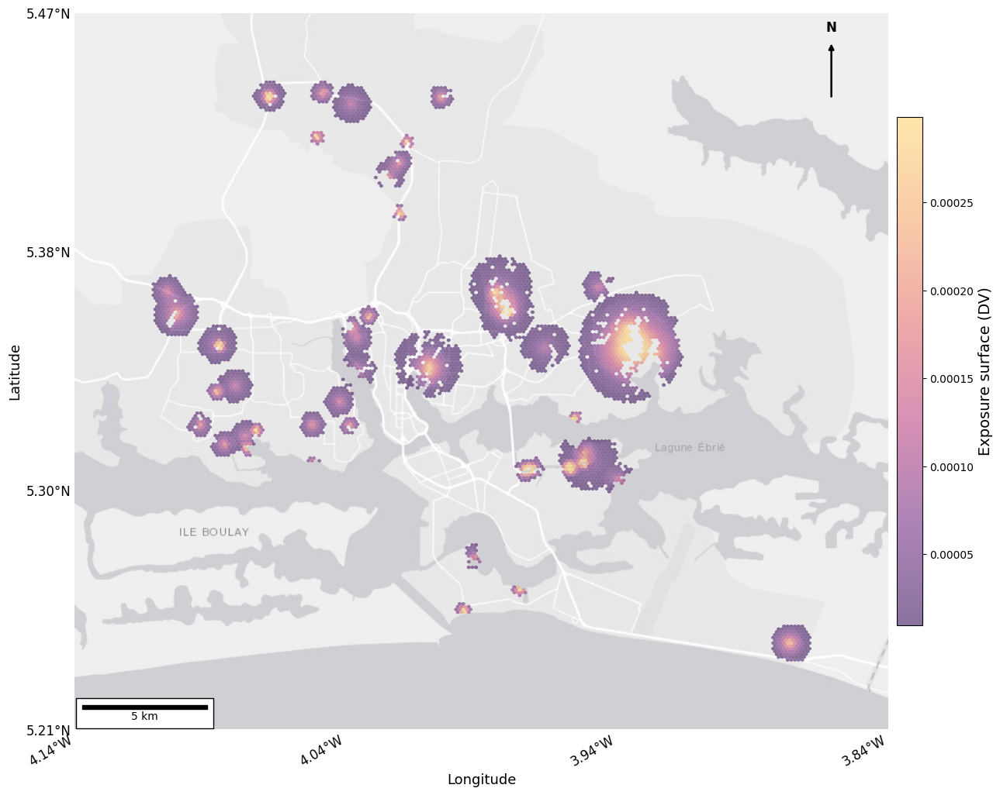


EXPOSURE SURFACE COMPLETE
City / year          : Abidjan 2016
Grid points plotted  : 15,365
99th percentile DV   : 0.000299
Output figure        :
/content/drive/MyDrive/Paper_3/Processing/DV/Revised/Abidjan/Abidjan_Exposure_Surface_2016_revised.png


In [ ]:
# =============================================================================
# EXPOSURE SURFACE VISUALIZATION (REVISED DV) — Abidjan 2016
# =============================================================================

import os
import math
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.font_manager as fm
import contextily as ctx
from pyproj import CRS, Transformer
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

warnings.filterwarnings("ignore")

# =============================================================================
# CONFIG
# =============================================================================
CITY = "Abidjan"
YEAR = 2016
IN_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
CSV = os.path.join(IN_DIR, f"{CITY.lower()}_grid30m_DV_{YEAR}_revised.csv")
OUT_DIR = IN_DIR
os.makedirs(OUT_DIR, exist_ok=True)
OUT_FIG = os.path.join(OUT_DIR, f"{CITY}_Exposure_Surface_{YEAR}_revised.png")
FIGSIZE = (13, 13)
DPI = 300

# =============================================================================
# COLOURMAP
# =============================================================================
exposure_cmap = mcolors.LinearSegmentedColormap.from_list(
    "Exposure",
    ["#2b004f", "#6a1f7a", "#b63679", "#e16462", "#f4a261", "#ffd166"],
    N=256
)

# =============================================================================
# CRS HELPERS
# =============================================================================
CRS_WEB = CRS.from_epsg(3857)
CRS_WGS = CRS.from_epsg(4326)

def utm_epsg(lon, lat):
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"

# =============================================================================
# NORTH ARROW
# =============================================================================
def add_north_arrow(ax):
    ax.annotate("", xy=(0.93, 0.96), xytext=(0.93, 0.88), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"))
    ax.text(0.93, 0.97, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=12, fontweight="bold")

# =============================================================================
# SCALE BAR
# =============================================================================
def add_scalebar(ax):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(ax.transData, 5000, "5 km", "lower left", pad=0.6,
                                color="black", frameon=True, size_vertical=150,
                                fontproperties=fontprops)
    ax.add_artist(scalebar)

# =============================================================================
# LAT/LON TICKS
# =============================================================================
def format_lon(x):
    return f"{abs(x):.2f}°{'E' if x >= 0 else 'W'}"

def format_lat(y):
    return f"{abs(y):.2f}°{'N' if y >= 0 else 'S'}"

def add_latlon_ticks(ax):
    transformer = Transformer.from_crs(CRS_WEB, CRS_WGS, always_xy=True)
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    xticks = np.linspace(xmin, xmax, 4)
    yticks = np.linspace(ymin, ymax, 4)
    yc = (ymin + ymax) / 2
    xc = (xmin + xmax) / 2
    lons = [transformer.transform(x, yc)[0] for x in xticks]
    lats = [transformer.transform(xc, y)[1] for y in yticks]
    ax.set_xticks(xticks)
    ax.set_xticklabels([format_lon(i) for i in lons], fontsize=12, rotation=30, ha="right")
    ax.set_yticks(yticks)
    ax.set_yticklabels([format_lat(i) for i in lats], fontsize=12)
    ax.set_xlabel("Longitude", fontsize=13)
    ax.set_ylabel("Latitude", fontsize=13)

# =============================================================================
# LOAD
# =============================================================================
print("Loading CSV...")
print(f"Source: {CSV}")
df = pd.read_csv(CSV)
required = ["longitude", "latitude", "DV_log1p"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")
epsg = utm_epsg(df.longitude.mean(), df.latitude.mean())
print("UTM:", epsg)

# =============================================================================
# PROJECT
# =============================================================================
gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude),
                        crs="EPSG:4326").to_crs(epsg)
gdf["DV_raw"] = np.expm1(gdf["DV_log1p"])
gdf = gdf.to_crs(3857)

# =============================================================================
# PREPARE SURFACE
# =============================================================================
nz = gdf[gdf["DV_raw"] > 0].copy()
q99 = nz["DV_raw"].quantile(0.99)
nz["DV_plot"] = nz["DV_raw"].clip(upper=q99)
if len(nz) > 120000:
    nz = nz.sample(120000, random_state=42)

# =============================================================================
# MAP EXTENT
# =============================================================================
xmin, ymin, xmax, ymax = nz.total_bounds
padx = (xmax - xmin) * 0.12
pady = (ymax - ymin) * 0.12

# =============================================================================
# PLOT
# =============================================================================
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.set_xlim(xmin - padx, xmax + padx)
ax.set_ylim(ymin - pady, ymax + pady)
ax.set_aspect("equal", adjustable="box")

# Esri WorldGrayCanvas replaces CartoDB.PositronNoLabels (Carto now requires an API key)
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas, attribution=False, zorder=0)

hb = ax.hexbin(nz.geometry.x.values, nz.geometry.y.values, C=nz["DV_plot"].values,
               reduce_C_function=np.mean, gridsize=180, mincnt=1, linewidths=0,
               alpha=0.55, cmap=exposure_cmap, zorder=5)

cbar = fig.colorbar(hb, ax=ax, fraction=0.03, pad=0.01)
cbar.set_label("Exposure surface (DV)", fontsize=14)

add_north_arrow(ax)
add_scalebar(ax)
add_latlon_ticks(ax)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(axis="both", which="both", length=0)

# =============================================================================
# SAVE
# =============================================================================
plt.tight_layout()
plt.savefig(OUT_FIG, dpi=DPI, bbox_inches="tight", facecolor="white")
plt.show()

print("\n" + "=" * 70)
print("EXPOSURE SURFACE COMPLETE")
print("=" * 70)
print(f"City / year          : {CITY} {YEAR}")
print(f"Grid points plotted  : {len(nz):,}")
print(f"99th percentile DV   : {q99:.6f}")
print(f"Output figure        :\n{OUT_FIG}")

Abidjan 2024
Source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Abidjan/abidjan_grid30m_DV_2024_revised.csv
UTM: EPSG:32630


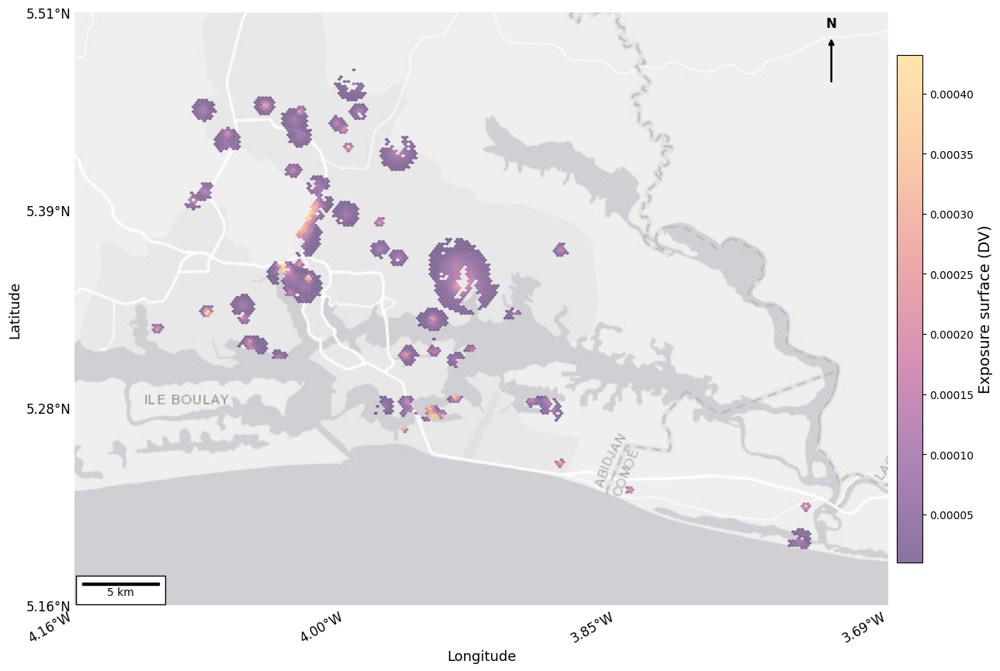

Grid points plotted  : 16,162
99th percentile DV   : 0.000432
Output figure        :
/content/drive/MyDrive/Paper_3/Processing/DV/Revised/Abidjan/Abidjan_Exposure_Surface_2024_revised.png

Abidjan 2016
Source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Abidjan/abidjan_grid30m_DV_2016_revised.csv
UTM: EPSG:32630


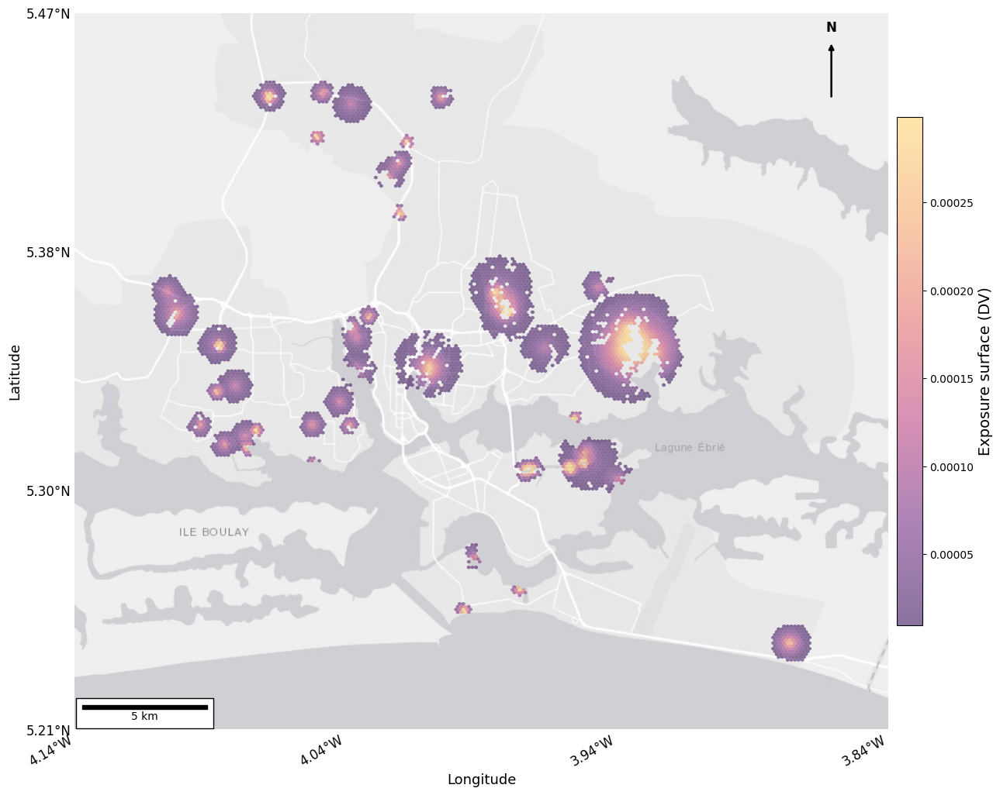

Grid points plotted  : 15,365
99th percentile DV   : 0.000299
Output figure        :
/content/drive/MyDrive/Paper_3/Processing/DV/Revised/Abidjan/Abidjan_Exposure_Surface_2016_revised.png

BOTH SURFACES COMPLETE
2024: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Abidjan/Abidjan_Exposure_Surface_2024_revised.png
2016: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Abidjan/Abidjan_Exposure_Surface_2016_revised.png


In [ ]:
# =============================================================================
# EXPOSURE SURFACE VISUALIZATION (REVISED DV) — BOTH YEARS
# Independent per-year colour scaling (each year clipped at its own q99)
# =============================================================================

import os
import math
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.font_manager as fm
import contextily as ctx
from pyproj import CRS, Transformer
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

warnings.filterwarnings("ignore")

# =============================================================================
# CONFIG
# =============================================================================
CITY = "Abidjan"
YEARS = [2024, 2016]

IN_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
OUT_DIR = IN_DIR
os.makedirs(OUT_DIR, exist_ok=True)

FIGSIZE = (13, 13)
DPI = 300

# =============================================================================
# COLOURMAP
# =============================================================================
exposure_cmap = mcolors.LinearSegmentedColormap.from_list(
    "Exposure",
    ["#2b004f", "#6a1f7a", "#b63679", "#e16462", "#f4a261", "#ffd166"],
    N=256
)

# =============================================================================
# CRS HELPERS
# =============================================================================
CRS_WEB = CRS.from_epsg(3857)
CRS_WGS = CRS.from_epsg(4326)

def utm_epsg(lon, lat):
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"

# =============================================================================
# NORTH ARROW
# =============================================================================
def add_north_arrow(ax):
    ax.annotate("", xy=(0.93, 0.96), xytext=(0.93, 0.88), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"))
    ax.text(0.93, 0.97, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=12, fontweight="bold")

# =============================================================================
# SCALE BAR
# =============================================================================
def add_scalebar(ax):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(ax.transData, 5000, "5 km", "lower left", pad=0.6,
                                color="black", frameon=True, size_vertical=150,
                                fontproperties=fontprops)
    ax.add_artist(scalebar)

# =============================================================================
# LAT/LON TICKS
# =============================================================================
def format_lon(x):
    return f"{abs(x):.2f}°{'E' if x >= 0 else 'W'}"

def format_lat(y):
    return f"{abs(y):.2f}°{'N' if y >= 0 else 'S'}"

def add_latlon_ticks(ax):
    transformer = Transformer.from_crs(CRS_WEB, CRS_WGS, always_xy=True)
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    xticks = np.linspace(xmin, xmax, 4)
    yticks = np.linspace(ymin, ymax, 4)
    yc = (ymin + ymax) / 2
    xc = (xmin + xmax) / 2
    lons = [transformer.transform(x, yc)[0] for x in xticks]
    lats = [transformer.transform(xc, y)[1] for y in yticks]
    ax.set_xticks(xticks)
    ax.set_xticklabels([format_lon(i) for i in lons], fontsize=12, rotation=30, ha="right")
    ax.set_yticks(yticks)
    ax.set_yticklabels([format_lat(i) for i in lats], fontsize=12)
    ax.set_xlabel("Longitude", fontsize=13)
    ax.set_ylabel("Latitude", fontsize=13)

# =============================================================================
# PLOT ONE YEAR
# =============================================================================
def plot_year(city, year, in_dir, out_dir):
    csv = os.path.join(in_dir, f"{city.lower()}_grid30m_DV_{year}_revised.csv")
    out_fig = os.path.join(out_dir, f"{city}_Exposure_Surface_{year}_revised.png")

    print("=" * 70)
    print(f"{city} {year}")
    print("=" * 70)
    print(f"Source: {csv}")

    df = pd.read_csv(csv)
    required = ["longitude", "latitude", "DV_log1p"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")

    epsg = utm_epsg(df.longitude.mean(), df.latitude.mean())
    print("UTM:", epsg)

    gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude),
                            crs="EPSG:4326").to_crs(epsg)
    gdf["DV_raw"] = np.expm1(gdf["DV_log1p"])
    gdf = gdf.to_crs(3857)

    nz = gdf[gdf["DV_raw"] > 0].copy()
    q99 = nz["DV_raw"].quantile(0.99)   # independent per-year scale
    nz["DV_plot"] = nz["DV_raw"].clip(upper=q99)
    if len(nz) > 120000:
        nz = nz.sample(120000, random_state=42)

    xmin, ymin, xmax, ymax = nz.total_bounds
    padx = (xmax - xmin) * 0.12
    pady = (ymax - ymin) * 0.12

    fig, ax = plt.subplots(figsize=FIGSIZE)
    ax.set_xlim(xmin - padx, xmax + padx)
    ax.set_ylim(ymin - pady, ymax + pady)
    ax.set_aspect("equal", adjustable="box")

    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas, attribution=False, zorder=0)

    hb = ax.hexbin(nz.geometry.x.values, nz.geometry.y.values, C=nz["DV_plot"].values,
                    reduce_C_function=np.mean, gridsize=180, mincnt=1, linewidths=0,
                    alpha=0.55, cmap=exposure_cmap, zorder=5)

    cbar = fig.colorbar(hb, ax=ax, fraction=0.03, pad=0.01)
    cbar.set_label("Exposure surface (DV)", fontsize=14)

    add_north_arrow(ax)
    add_scalebar(ax)
    add_latlon_ticks(ax)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="both", length=0)

    plt.tight_layout()
    plt.savefig(out_fig, dpi=DPI, bbox_inches="tight", facecolor="white")
    plt.show()

    print(f"Grid points plotted  : {len(nz):,}")
    print(f"99th percentile DV   : {q99:.6f}")
    print(f"Output figure        :\n{out_fig}\n")

    return out_fig

# =============================================================================
# RUN BOTH YEARS
# =============================================================================
outputs = {}
for year in YEARS:
    outputs[year] = plot_year(CITY, year, IN_DIR, OUT_DIR)

print("=" * 70)
print("BOTH SURFACES COMPLETE")
print("=" * 70)
for year, path in outputs.items():
    print(f"{year}: {path}")

Accra

In [ ]:
# =============================================================================
# REVISED DIFFERENTIAL-SPREAD DV GENERATION (Accra 2024)
# 500m² FLOOR + SIZE-SCALED RADIUS (200m-2km) + STEEPENED DECAY (H_HALF=0.30)
# BLOCK 1 — CONFIGURATION, KMZ LOADING, SITE PREPROCESSING & KD-TREE
# =============================================================================

import os
import zipfile
import tempfile
import warnings
import fiona
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

# --- CONFIGURATION ------------------------------------------------------

CITY = "Accra"
YEAR = 2024

EPSG = 32630   # confirmed
BETA = 0.44    # confirmed

KMZ_FILE  = f"/content/drive/MyDrive/Paper_3/Sites/{YEAR}/{CITY}/{CITY}_{YEAR}.kmz"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"

OUT_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
os.makedirs(OUT_DIR, exist_ok=True)
OUTPUT_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_{YEAR}_revised.csv")

# 2024 reads the original master grid
GRID_CSV = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets/{CITY.lower()}_grid30m_master_merged_withDV.csv"

# --- LOCKED DESIGN PARAMETERS (same for all cities/years) -------------------

MIN_AREA_M2    = 500.0
MIN_RADIUS_M   = 200.0
MAX_RADIUS_M   = 2000.0
CAP_PERCENTILE = 99
H_HALF         = 0.30
TAU            = 1.0

# --- CITY-SPECIFIC AREA CAP (pooled 2016+2024, from site CSVs) --------------

print("=" * 70)
print(f"Computing area cap for {CITY} (pooled 2016+2024)...")
print("=" * 70)

areas_pooled = []
for y in [2016, 2024]:
    sites_csv = pd.read_csv(f"{SITES_DIR}/{y}/{CITY}/{CITY}_{y}_sites.csv")
    sites_csv = sites_csv.dropna(subset=["area"])
    sites_csv = sites_csv[sites_csv["area"] >= MIN_AREA_M2]
    areas_pooled.extend(sites_csv["area"].values)

AREA_CAP_M2 = np.percentile(areas_pooled, CAP_PERCENTILE)
print(f"{CITY}: n={len(areas_pooled):,} qualifying sites (both years), "
      f"p{CAP_PERCENTILE} area cap = {AREA_CAP_M2:,.1f} m² ({AREA_CAP_M2/10000:.2f} ha)")

# --- LOAD & PROJECT KMZ (target year's own site geometries) -----------------

print("\n" + "=" * 70)
print("Loading KMZ...")
print("=" * 70)

tmpdir = tempfile.mkdtemp()
with zipfile.ZipFile(KMZ_FILE, "r") as z:
    z.extractall(tmpdir)

kml_files = [
    os.path.join(root, f)
    for root, _, files in os.walk(tmpdir)
    for f in files if f.lower().endswith(".kml")
]
if not kml_files:
    raise RuntimeError("No KML file found inside KMZ.")

kml_file = kml_files[0]
print(f"KML found: {kml_file}")

fiona.drvsupport.supported_drivers["KML"] = "rw"
sites = gpd.read_file(kml_file, driver="KML").set_geometry("geometry")

if sites.crs is None:
    sites = sites.set_crs(4326)
sites = sites.to_crs(EPSG)
print(f"Loaded {len(sites)} geometries, projected to EPSG:{EPSG}")

# --- EXPLODE, FILTER TO POLYGONS, COMPUTE AREA -------------------------

sites = sites.explode(index_parts=False).reset_index(drop=True)
sites = sites[sites.geometry.type.isin(["Polygon", "MultiPolygon"])].copy()
print(f"Polygon features: {len(sites)}")
if len(sites) == 0:
    raise RuntimeError("No polygons found.")

sites["area_m2"] = sites.geometry.area
sites = sites[np.isfinite(sites["area_m2"]) & (sites["area_m2"] > 0)].copy()
print(f"Valid polygons: {len(sites)}")

# --- 500 m² FLOOR -------------------------------------------------------

n_before_floor = len(sites)
sites = sites[sites["area_m2"] >= MIN_AREA_M2].copy()
print(f"Sites >= {MIN_AREA_M2:.0f} m²: {len(sites)} (dropped {n_before_floor - len(sites)} smaller sites)")
if len(sites) == 0:
    raise RuntimeError(f"No sites >= {MIN_AREA_M2:.0f} m² for {CITY} {YEAR}.")

# --- CENTROIDS -----------------------------------------------------------

sites["centroid"] = sites.geometry.centroid
site_pts = sites.set_geometry("centroid").copy()

site_xy = np.column_stack((site_pts.geometry.x.values, site_pts.geometry.y.values))
areas = site_pts["area_m2"].to_numpy(dtype=float)

# --- SIZE-SCALED RADII (200m-2km, city-specific p99 cap) -------------------

print("\nComputing size-scaled radii...")

capped_area = np.minimum(areas, AREA_CAP_M2)
score = (np.log(capped_area) - np.log(MIN_AREA_M2)) / (np.log(AREA_CAP_M2) - np.log(MIN_AREA_M2))
r_j = MIN_RADIUS_M + (MAX_RADIUS_M - MIN_RADIUS_M) * score

lambda_j = np.log(2.0) / (H_HALF * r_j)
K_j = (lambda_j ** 2) / (2.0 * np.pi)
mass_j = np.power(np.maximum(areas, 1.0), BETA)

# --- KD-TREE ---------------------------------------------------------------

tree = cKDTree(site_xy)
R_QUERY = TAU * np.max(r_j)
print("\nKD Tree constructed.")

# --- LOAD GRID COORDINATES --------------------------------------------------

print("\nLoading grid coordinates...")
print(f"Grid source: {GRID_CSV}")

grid = pd.read_csv(GRID_CSV, usecols=["grid_point", "longitude", "latitude"]).dropna()
print(f"Grid points: {len(grid):,}")

grid_gdf = gpd.GeoDataFrame(
    grid,
    geometry=gpd.points_from_xy(grid.longitude, grid.latitude),
    crs=4326
).to_crs(EPSG)

points_xy = np.column_stack((grid_gdf.geometry.x.values, grid_gdf.geometry.y.values))

# --- DIAGNOSTICS -------------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)
print(f"City / year                : {CITY} {YEAR}")
print(f"EPSG / BETA (per-city)     : {EPSG} / {BETA}")
print(f"Min area / min radius      : {MIN_AREA_M2:.0f} m² / {MIN_RADIUS_M:.0f} m")
print(f"Area cap (p{CAP_PERCENTILE}) / max radius : {AREA_CAP_M2:,.1f} m² / {MAX_RADIUS_M:.0f} m")
print(f"H_HALF / TAU                : {H_HALF} / {TAU}")
print(f"Sites retained (>= floor)   : {len(site_pts):,}")
print(f"Grid points                 : {len(points_xy):,}")
print(f"Mean site area (m²)         : {areas.mean():.2f}")
print(f"Median site area (m²)       : {np.median(areas):.2f}")
print("\nSize-scaled radius summary (m)")
print(pd.Series(r_j).describe())
print(f"\nMaximum search radius: {R_QUERY:.2f} m")
print(f"\nOutput will be saved to:\n{OUTPUT_CSV}")
print("\nBlock 1 completed successfully. Proceed to Block 2.")

Computing area cap for Accra (pooled 2016+2024)...
Accra: n=348 qualifying sites (both years), p99 area cap = 68,549.0 m² (6.85 ha)

Loading KMZ...
KML found: /tmp/tmpwzw_jdt0/doc.kml
Loaded 552 geometries, projected to EPSG:32630
Polygon features: 552
Valid polygons: 552
Sites >= 500 m²: 209 (dropped 343 smaller sites)

Computing size-scaled radii...

KD Tree constructed.

Loading grid coordinates...
Grid source: /content/drive/MyDrive/Results_2/Data_2024/Processed/Accra/Final_datasets/accra_grid30m_master_merged_withDV.csv
Grid points: 614,158

SUMMARY
City / year                : Accra 2024
EPSG / BETA (per-city)     : 32630 / 0.44
Min area / min radius      : 500 m² / 200 m
Area cap (p99) / max radius : 68,549.0 m² / 2000 m
H_HALF / TAU                : 0.3 / 1.0
Sites retained (>= floor)   : 209
Grid points                 : 614,158
Mean site area (m²)         : 5280.27
Median site area (m²)       : 1291.84

Size-scaled radius summary (m)
count     209.000000
mean      679.563512


In [ ]:
# =============================================================================
# BLOCK 2 — COMPUTE DIFFERENTIAL-SPREAD DV AT EVERY 30 m GRID POINT + SAVE
# =============================================================================

import time

print("=" * 70)
print("Computing DV at 30 m grid points...")
print("=" * 70)

t0 = time.time()

N = len(points_xy)
DV_pts = np.zeros(N, dtype=np.float64)
overlap_pts = np.zeros(N, dtype=np.int16)

BATCH_SIZE = 5000
print(f"Grid points : {N:,}")
print(f"Batch size  : {BATCH_SIZE:,}")
print(f"Total batches: {int(np.ceil(N / BATCH_SIZE))}")

for start in range(0, N, BATCH_SIZE):
    end = min(start + BATCH_SIZE, N)
    batch_points = points_xy[start:end]

    neighbour_lists = tree.query_ball_point(batch_points, r=R_QUERY)

    for i, neighbours in enumerate(neighbour_lists):
        if len(neighbours) == 0:
            continue

        pt = batch_points[i]
        cand_xy = site_xy[neighbours]

        dx = cand_xy[:, 0] - pt[0]
        dy = cand_xy[:, 1] - pt[1]
        d = np.sqrt(dx * dx + dy * dy)

        r_local = r_j[neighbours]
        keep = d <= (TAU * r_local)
        if not np.any(keep):
            continue

        d = d[keep]
        lam = lambda_j[neighbours][keep]
        K = K_j[neighbours][keep]
        mass = mass_j[neighbours][keep]

        contrib = mass * K * np.exp(-lam * d)
        DV_pts[start + i] = contrib.sum()
        overlap_pts[start + i] = keep.sum()

    processed = end
    pct = processed / N * 100
    elapsed = time.time() - t0
    rate = processed / elapsed
    remaining = (N - processed) / rate if rate > 0 else np.nan
    print(f"{processed:>8,} / {N:,} ({pct:5.1f}%)   Elapsed: {elapsed:6.1f}s   ETA: {remaining:6.1f}s")

print("\nFinished DV computation.")

DV_log = np.log1p(DV_pts)

print(f"Non-zero grid points : {(DV_pts>0).sum():,}")
print(f"Maximum overlap      : {overlap_pts.max()}")
print(f"Maximum DV           : {DV_pts.max():.6f}")
print(f"Mean DV              : {DV_pts.mean():.6f}")
print(f"Median DV            : {np.median(DV_pts):.6f}")

print("\n" + "=" * 70)
print("Saving output...")
print("=" * 70)

out_df = pd.DataFrame({
    "grid_point": grid["grid_point"].values,
    "longitude": grid["longitude"].values,
    "latitude": grid["latitude"].values,
    "DV_hex_diffspread": DV_pts,
    "DV_log1p": DV_log,
    "n_sites": overlap_pts
}).sort_values("grid_point").reset_index(drop=True)

os.makedirs(OUT_DIR, exist_ok=True)
out_df.to_csv(OUTPUT_CSV, index=False)

runtime = time.time() - t0
pct_list = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

print("\n" + "=" * 70)
print("OUTPUT SUMMARY")
print("=" * 70)
print(f"Output file:\n{OUTPUT_CSV}\n")
print(f"Rows written                : {len(out_df):,}")
print(f"Non-zero DV                 : {(out_df.DV_hex_diffspread>0).sum():,}")
print(f"Zero DV                     : {(out_df.DV_hex_diffspread==0).sum():,}")
print(f"Maximum contributing sites  : {out_df.n_sites.max()}")
print(f"Mean contributing sites     : {out_df.n_sites[out_df.n_sites>0].mean():.2f}")

print("\nDV summary")
print(out_df["DV_hex_diffspread"].describe(percentiles=pct_list))

print("\nDV_log1p summary")
print(out_df["DV_log1p"].describe(percentiles=pct_list))

print(f"\nProcessing time : {runtime:.1f} seconds")
print("\n✓ Revised DV successfully generated.")
print(f"\nSaved to:\n{OUTPUT_CSV}")

Computing DV at 30 m grid points...
Grid points : 614,158
Batch size  : 5,000
Total batches: 123
   5,000 / 614,158 (  0.8%)   Elapsed:    0.1s   ETA:   10.3s
  10,000 / 614,158 (  1.6%)   Elapsed:    0.2s   ETA:   13.6s
  15,000 / 614,158 (  2.4%)   Elapsed:    0.3s   ETA:   12.7s
  20,000 / 614,158 (  3.3%)   Elapsed:    0.4s   ETA:   10.9s
  25,000 / 614,158 (  4.1%)   Elapsed:    0.4s   ETA:    9.6s
  30,000 / 614,158 (  4.9%)   Elapsed:    0.4s   ETA:    8.7s
  35,000 / 614,158 (  5.7%)   Elapsed:    0.5s   ETA:    8.1s
  40,000 / 614,158 (  6.5%)   Elapsed:    0.5s   ETA:    7.8s
  45,000 / 614,158 (  7.3%)   Elapsed:    0.6s   ETA:    7.6s
  50,000 / 614,158 (  8.1%)   Elapsed:    0.6s   ETA:    7.3s
  55,000 / 614,158 (  9.0%)   Elapsed:    0.7s   ETA:    7.0s
  60,000 / 614,158 (  9.8%)   Elapsed:    0.7s   ETA:    6.8s
  65,000 / 614,158 ( 10.6%)   Elapsed:    0.8s   ETA:    6.7s
  70,000 / 614,158 ( 11.4%)   Elapsed:    0.8s   ETA:    6.4s
  75,000 / 614,158 ( 12.2%)   Elaps

2016

In [ ]:
# =============================================================================
# REVISED DIFFERENTIAL-SPREAD DV GENERATION (Accra 2016)
# 500m² FLOOR + SIZE-SCALED RADIUS (200m-2km) + STEEPENED DECAY (H_HALF=0.30)
# BLOCK 1 — CONFIGURATION, KMZ LOADING, SITE PREPROCESSING & KD-TREE
# =============================================================================

import os
import zipfile
import tempfile
import warnings
import fiona
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

# --- CONFIGURATION ------------------------------------------------------

CITY = "Accra"
YEAR = 2016

EPSG = 32630   # confirmed, matches Accra 2024
BETA = 0.44    # confirmed, matches Accra 2024

KMZ_FILE  = f"/content/drive/MyDrive/Paper_3/Sites/{YEAR}/{CITY}/{CITY}_{YEAR}.kmz"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"

OUT_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
os.makedirs(OUT_DIR, exist_ok=True)
OUTPUT_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_{YEAR}_revised.csv")

# 2016 reuses 2024's own REVISED output as the grid source (same grid_point set)
GRID_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_2024_revised.csv")
if not os.path.exists(GRID_CSV):
    raise RuntimeError(
        f"2024 revised output not found for {CITY} — run YEAR=2024 first, "
        f"since 2016 reuses its grid for cross-year consistency."
    )

# --- LOCKED DESIGN PARAMETERS (same for all cities/years) -------------------

MIN_AREA_M2    = 500.0
MIN_RADIUS_M   = 200.0
MAX_RADIUS_M   = 2000.0
CAP_PERCENTILE = 99
H_HALF         = 0.30
TAU            = 1.0

# --- CITY-SPECIFIC AREA CAP (pooled 2016+2024, from site CSVs) --------------

print("=" * 70)
print(f"Computing area cap for {CITY} (pooled 2016+2024)...")
print("=" * 70)

areas_pooled = []
for y in [2016, 2024]:
    sites_csv = pd.read_csv(f"{SITES_DIR}/{y}/{CITY}/{CITY}_{y}_sites.csv")
    sites_csv = sites_csv.dropna(subset=["area"])
    sites_csv = sites_csv[sites_csv["area"] >= MIN_AREA_M2]
    areas_pooled.extend(sites_csv["area"].values)

AREA_CAP_M2 = np.percentile(areas_pooled, CAP_PERCENTILE)
print(f"{CITY}: n={len(areas_pooled):,} qualifying sites (both years), "
      f"p{CAP_PERCENTILE} area cap = {AREA_CAP_M2:,.1f} m² ({AREA_CAP_M2/10000:.2f} ha)")

# --- LOAD & PROJECT KMZ (target year's own site geometries) -----------------

print("\n" + "=" * 70)
print("Loading KMZ...")
print("=" * 70)

tmpdir = tempfile.mkdtemp()
with zipfile.ZipFile(KMZ_FILE, "r") as z:
    z.extractall(tmpdir)

kml_files = [
    os.path.join(root, f)
    for root, _, files in os.walk(tmpdir)
    for f in files if f.lower().endswith(".kml")
]
if not kml_files:
    raise RuntimeError("No KML file found inside KMZ.")

kml_file = kml_files[0]
print(f"KML found: {kml_file}")

fiona.drvsupport.supported_drivers["KML"] = "rw"
sites = gpd.read_file(kml_file, driver="KML").set_geometry("geometry")

if sites.crs is None:
    sites = sites.set_crs(4326)
sites = sites.to_crs(EPSG)
print(f"Loaded {len(sites)} geometries, projected to EPSG:{EPSG}")

# --- EXPLODE, FILTER TO POLYGONS, COMPUTE AREA -------------------------

sites = sites.explode(index_parts=False).reset_index(drop=True)
sites = sites[sites.geometry.type.isin(["Polygon", "MultiPolygon"])].copy()
print(f"Polygon features: {len(sites)}")
if len(sites) == 0:
    raise RuntimeError("No polygons found.")

sites["area_m2"] = sites.geometry.area
sites = sites[np.isfinite(sites["area_m2"]) & (sites["area_m2"] > 0)].copy()
print(f"Valid polygons: {len(sites)}")

# --- 500 m² FLOOR -------------------------------------------------------

n_before_floor = len(sites)
sites = sites[sites["area_m2"] >= MIN_AREA_M2].copy()
print(f"Sites >= {MIN_AREA_M2:.0f} m²: {len(sites)} (dropped {n_before_floor - len(sites)} smaller sites)")
if len(sites) == 0:
    raise RuntimeError(f"No sites >= {MIN_AREA_M2:.0f} m² for {CITY} {YEAR}.")

# --- CENTROIDS -----------------------------------------------------------

sites["centroid"] = sites.geometry.centroid
site_pts = sites.set_geometry("centroid").copy()

site_xy = np.column_stack((site_pts.geometry.x.values, site_pts.geometry.y.values))
areas = site_pts["area_m2"].to_numpy(dtype=float)

# --- SIZE-SCALED RADII (200m-2km, city-specific p99 cap) -------------------

print("\nComputing size-scaled radii...")

capped_area = np.minimum(areas, AREA_CAP_M2)
score = (np.log(capped_area) - np.log(MIN_AREA_M2)) / (np.log(AREA_CAP_M2) - np.log(MIN_AREA_M2))
r_j = MIN_RADIUS_M + (MAX_RADIUS_M - MIN_RADIUS_M) * score

lambda_j = np.log(2.0) / (H_HALF * r_j)
K_j = (lambda_j ** 2) / (2.0 * np.pi)
mass_j = np.power(np.maximum(areas, 1.0), BETA)

# --- KD-TREE ---------------------------------------------------------------

tree = cKDTree(site_xy)
R_QUERY = TAU * np.max(r_j)
print("\nKD Tree constructed.")

# --- LOAD GRID COORDINATES --------------------------------------------------

print("\nLoading grid coordinates...")
print(f"Grid source: {GRID_CSV}")

grid = pd.read_csv(GRID_CSV, usecols=["grid_point", "longitude", "latitude"]).dropna()
print(f"Grid points: {len(grid):,}")

grid_gdf = gpd.GeoDataFrame(
    grid,
    geometry=gpd.points_from_xy(grid.longitude, grid.latitude),
    crs=4326
).to_crs(EPSG)

points_xy = np.column_stack((grid_gdf.geometry.x.values, grid_gdf.geometry.y.values))

# --- DIAGNOSTICS -------------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)
print(f"City / year                : {CITY} {YEAR}")
print(f"EPSG / BETA (per-city)     : {EPSG} / {BETA}")
print(f"Min area / min radius      : {MIN_AREA_M2:.0f} m² / {MIN_RADIUS_M:.0f} m")
print(f"Area cap (p{CAP_PERCENTILE}) / max radius : {AREA_CAP_M2:,.1f} m² / {MAX_RADIUS_M:.0f} m")
print(f"H_HALF / TAU                : {H_HALF} / {TAU}")
print(f"Sites retained (>= floor)   : {len(site_pts):,}")
print(f"Grid points                 : {len(points_xy):,}")
print(f"Mean site area (m²)         : {areas.mean():.2f}")
print(f"Median site area (m²)       : {np.median(areas):.2f}")
print("\nSize-scaled radius summary (m)")
print(pd.Series(r_j).describe())
print(f"\nMaximum search radius: {R_QUERY:.2f} m")
print(f"\nOutput will be saved to:\n{OUTPUT_CSV}")
print("\nBlock 1 completed successfully. Proceed to Block 2.")

Computing area cap for Accra (pooled 2016+2024)...
Accra: n=348 qualifying sites (both years), p99 area cap = 68,549.0 m² (6.85 ha)

Loading KMZ...
KML found: /tmp/tmpz1e3c5b6/doc.kml
Loaded 795 geometries, projected to EPSG:32630
Polygon features: 795
Valid polygons: 793
Sites >= 500 m²: 139 (dropped 654 smaller sites)

Computing size-scaled radii...

KD Tree constructed.

Loading grid coordinates...
Grid source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Accra/accra_grid30m_DV_2024_revised.csv
Grid points: 614,158

SUMMARY
City / year                : Accra 2016
EPSG / BETA (per-city)     : 32630 / 0.44
Min area / min radius      : 500 m² / 200 m
Area cap (p99) / max radius : 68,549.0 m² / 2000 m
H_HALF / TAU                : 0.3 / 1.0
Sites retained (>= floor)   : 139
Grid points                 : 614,158
Mean site area (m²)         : 4114.92
Median site area (m²)       : 1020.90

Size-scaled radius summary (m)
count     139.000000
mean      592.413529
std       387.559289

In [ ]:
# =============================================================================
# BLOCK 2 — COMPUTE DIFFERENTIAL-SPREAD DV AT EVERY 30 m GRID POINT + SAVE
# =============================================================================

import time

print("=" * 70)
print("Computing DV at 30 m grid points...")
print("=" * 70)

t0 = time.time()

N = len(points_xy)
DV_pts = np.zeros(N, dtype=np.float64)
overlap_pts = np.zeros(N, dtype=np.int16)

BATCH_SIZE = 5000
print(f"Grid points : {N:,}")
print(f"Batch size  : {BATCH_SIZE:,}")
print(f"Total batches: {int(np.ceil(N / BATCH_SIZE))}")

for start in range(0, N, BATCH_SIZE):
    end = min(start + BATCH_SIZE, N)
    batch_points = points_xy[start:end]

    neighbour_lists = tree.query_ball_point(batch_points, r=R_QUERY)

    for i, neighbours in enumerate(neighbour_lists):
        if len(neighbours) == 0:
            continue

        pt = batch_points[i]
        cand_xy = site_xy[neighbours]

        dx = cand_xy[:, 0] - pt[0]
        dy = cand_xy[:, 1] - pt[1]
        d = np.sqrt(dx * dx + dy * dy)

        r_local = r_j[neighbours]
        keep = d <= (TAU * r_local)
        if not np.any(keep):
            continue

        d = d[keep]
        lam = lambda_j[neighbours][keep]
        K = K_j[neighbours][keep]
        mass = mass_j[neighbours][keep]

        contrib = mass * K * np.exp(-lam * d)
        DV_pts[start + i] = contrib.sum()
        overlap_pts[start + i] = keep.sum()

    processed = end
    pct = processed / N * 100
    elapsed = time.time() - t0
    rate = processed / elapsed
    remaining = (N - processed) / rate if rate > 0 else np.nan
    print(f"{processed:>8,} / {N:,} ({pct:5.1f}%)   Elapsed: {elapsed:6.1f}s   ETA: {remaining:6.1f}s")

print("\nFinished DV computation.")

DV_log = np.log1p(DV_pts)

print(f"Non-zero grid points : {(DV_pts>0).sum():,}")
print(f"Maximum overlap      : {overlap_pts.max()}")
print(f"Maximum DV           : {DV_pts.max():.6f}")
print(f"Mean DV              : {DV_pts.mean():.6f}")
print(f"Median DV            : {np.median(DV_pts):.6f}")

print("\n" + "=" * 70)
print("Saving output...")
print("=" * 70)

out_df = pd.DataFrame({
    "grid_point": grid["grid_point"].values,
    "longitude": grid["longitude"].values,
    "latitude": grid["latitude"].values,
    "DV_hex_diffspread": DV_pts,
    "DV_log1p": DV_log,
    "n_sites": overlap_pts
}).sort_values("grid_point").reset_index(drop=True)

os.makedirs(OUT_DIR, exist_ok=True)
out_df.to_csv(OUTPUT_CSV, index=False)

runtime = time.time() - t0
pct_list = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

print("\n" + "=" * 70)
print("OUTPUT SUMMARY")
print("=" * 70)
print(f"Output file:\n{OUTPUT_CSV}\n")
print(f"Rows written                : {len(out_df):,}")
print(f"Non-zero DV                 : {(out_df.DV_hex_diffspread>0).sum():,}")
print(f"Zero DV                     : {(out_df.DV_hex_diffspread==0).sum():,}")
print(f"Maximum contributing sites  : {out_df.n_sites.max()}")
print(f"Mean contributing sites     : {out_df.n_sites[out_df.n_sites>0].mean():.2f}")

print("\nDV summary")
print(out_df["DV_hex_diffspread"].describe(percentiles=pct_list))

print("\nDV_log1p summary")
print(out_df["DV_log1p"].describe(percentiles=pct_list))

print(f"\nProcessing time : {runtime:.1f} seconds")
print("\n✓ Revised DV successfully generated.")
print(f"\nSaved to:\n{OUTPUT_CSV}")

Computing DV at 30 m grid points...
Grid points : 614,158
Batch size  : 5,000
Total batches: 123
   5,000 / 614,158 (  0.8%)   Elapsed:    0.0s   ETA:    1.1s
  10,000 / 614,158 (  1.6%)   Elapsed:    0.0s   ETA:    0.8s
  15,000 / 614,158 (  2.4%)   Elapsed:    0.0s   ETA:    0.7s
  20,000 / 614,158 (  3.3%)   Elapsed:    0.0s   ETA:    0.8s
  25,000 / 614,158 (  4.1%)   Elapsed:    0.1s   ETA:    1.7s
  30,000 / 614,158 (  4.9%)   Elapsed:    0.2s   ETA:    3.2s
  35,000 / 614,158 (  5.7%)   Elapsed:    0.2s   ETA:    3.6s
  40,000 / 614,158 (  6.5%)   Elapsed:    0.3s   ETA:    3.9s
  45,000 / 614,158 (  7.3%)   Elapsed:    0.3s   ETA:    4.0s
  50,000 / 614,158 (  8.1%)   Elapsed:    0.4s   ETA:    4.0s
  55,000 / 614,158 (  9.0%)   Elapsed:    0.4s   ETA:    4.0s
  60,000 / 614,158 (  9.8%)   Elapsed:    0.4s   ETA:    3.9s
  65,000 / 614,158 ( 10.6%)   Elapsed:    0.4s   ETA:    3.7s
  70,000 / 614,158 ( 11.4%)   Elapsed:    0.5s   ETA:    3.5s
  75,000 / 614,158 ( 12.2%)   Elaps

Accra 2024
Source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Accra/accra_grid30m_DV_2024_revised.csv
UTM: EPSG:32630


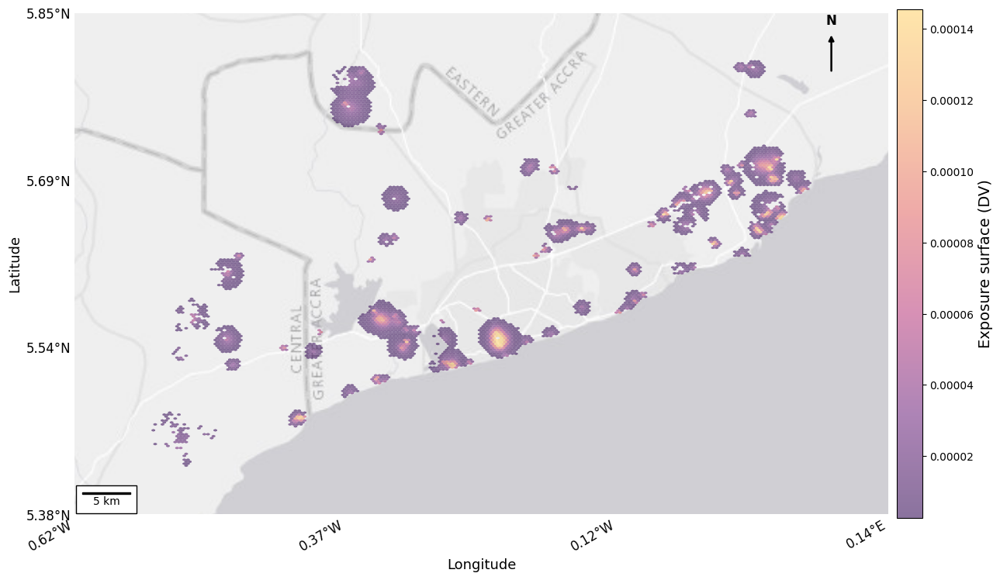

Grid points plotted  : 72,037
99th percentile DV   : 0.000145
Output figure        :
/content/drive/MyDrive/Paper_3/Processing/DV/Revised/Accra/Accra_Exposure_Surface_2024_revised.png

Accra 2016
Source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Accra/accra_grid30m_DV_2016_revised.csv
UTM: EPSG:32630


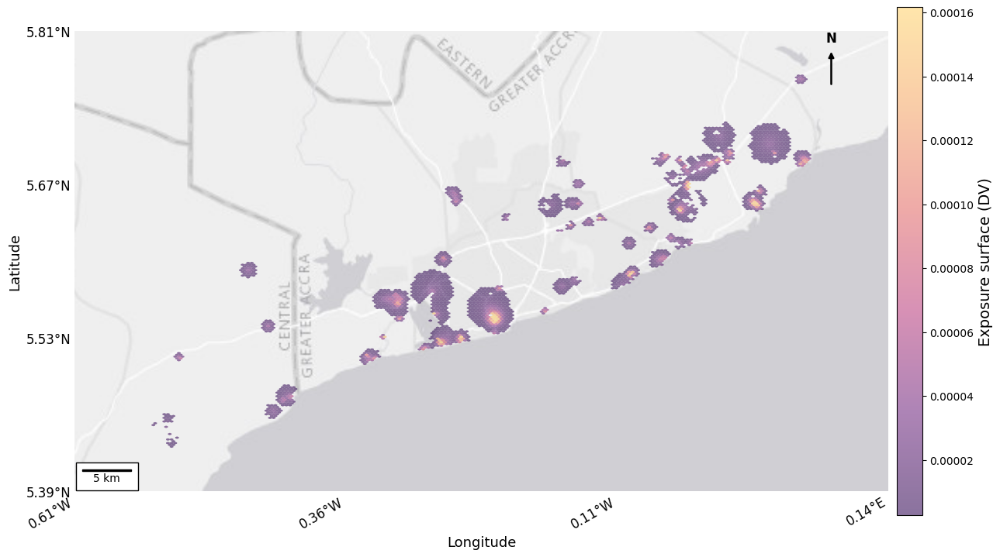

Grid points plotted  : 55,288
99th percentile DV   : 0.000162
Output figure        :
/content/drive/MyDrive/Paper_3/Processing/DV/Revised/Accra/Accra_Exposure_Surface_2016_revised.png

BOTH SURFACES COMPLETE
2024: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Accra/Accra_Exposure_Surface_2024_revised.png
2016: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Accra/Accra_Exposure_Surface_2016_revised.png


In [ ]:
# =============================================================================
# EXPOSURE SURFACE VISUALIZATION (REVISED DV) — BOTH YEARS
# Independent per-year colour scaling (each year clipped at its own q99)
# =============================================================================

import os
import math
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.font_manager as fm
import contextily as ctx
from pyproj import CRS, Transformer
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

warnings.filterwarnings("ignore")

# =============================================================================
# CONFIG
# =============================================================================
CITY = "Accra"
YEARS = [2024, 2016]

IN_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
OUT_DIR = IN_DIR
os.makedirs(OUT_DIR, exist_ok=True)

FIGSIZE = (13, 13)
DPI = 300

# =============================================================================
# COLOURMAP
# =============================================================================
exposure_cmap = mcolors.LinearSegmentedColormap.from_list(
    "Exposure",
    ["#2b004f", "#6a1f7a", "#b63679", "#e16462", "#f4a261", "#ffd166"],
    N=256
)

# =============================================================================
# CRS HELPERS
# =============================================================================
CRS_WEB = CRS.from_epsg(3857)
CRS_WGS = CRS.from_epsg(4326)

def utm_epsg(lon, lat):
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"

# =============================================================================
# NORTH ARROW
# =============================================================================
def add_north_arrow(ax):
    ax.annotate("", xy=(0.93, 0.96), xytext=(0.93, 0.88), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"))
    ax.text(0.93, 0.97, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=12, fontweight="bold")

# =============================================================================
# SCALE BAR
# =============================================================================
def add_scalebar(ax):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(ax.transData, 5000, "5 km", "lower left", pad=0.6,
                                color="black", frameon=True, size_vertical=150,
                                fontproperties=fontprops)
    ax.add_artist(scalebar)

# =============================================================================
# LAT/LON TICKS
# =============================================================================
def format_lon(x):
    return f"{abs(x):.2f}°{'E' if x >= 0 else 'W'}"

def format_lat(y):
    return f"{abs(y):.2f}°{'N' if y >= 0 else 'S'}"

def add_latlon_ticks(ax):
    transformer = Transformer.from_crs(CRS_WEB, CRS_WGS, always_xy=True)
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    xticks = np.linspace(xmin, xmax, 4)
    yticks = np.linspace(ymin, ymax, 4)
    yc = (ymin + ymax) / 2
    xc = (xmin + xmax) / 2
    lons = [transformer.transform(x, yc)[0] for x in xticks]
    lats = [transformer.transform(xc, y)[1] for y in yticks]
    ax.set_xticks(xticks)
    ax.set_xticklabels([format_lon(i) for i in lons], fontsize=12, rotation=30, ha="right")
    ax.set_yticks(yticks)
    ax.set_yticklabels([format_lat(i) for i in lats], fontsize=12)
    ax.set_xlabel("Longitude", fontsize=13)
    ax.set_ylabel("Latitude", fontsize=13)

# =============================================================================
# PLOT ONE YEAR
# =============================================================================
def plot_year(city, year, in_dir, out_dir):
    csv = os.path.join(in_dir, f"{city.lower()}_grid30m_DV_{year}_revised.csv")
    out_fig = os.path.join(out_dir, f"{city}_Exposure_Surface_{year}_revised.png")

    print("=" * 70)
    print(f"{city} {year}")
    print("=" * 70)
    print(f"Source: {csv}")

    df = pd.read_csv(csv)
    required = ["longitude", "latitude", "DV_log1p"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")

    epsg = utm_epsg(df.longitude.mean(), df.latitude.mean())
    print("UTM:", epsg)

    gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude),
                            crs="EPSG:4326").to_crs(epsg)
    gdf["DV_raw"] = np.expm1(gdf["DV_log1p"])
    gdf = gdf.to_crs(3857)

    nz = gdf[gdf["DV_raw"] > 0].copy()
    q99 = nz["DV_raw"].quantile(0.99)   # independent per-year scale
    nz["DV_plot"] = nz["DV_raw"].clip(upper=q99)
    if len(nz) > 120000:
        nz = nz.sample(120000, random_state=42)

    xmin, ymin, xmax, ymax = nz.total_bounds
    padx = (xmax - xmin) * 0.12
    pady = (ymax - ymin) * 0.12

    fig, ax = plt.subplots(figsize=FIGSIZE)
    ax.set_xlim(xmin - padx, xmax + padx)
    ax.set_ylim(ymin - pady, ymax + pady)
    ax.set_aspect("equal", adjustable="box")

    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas, attribution=False, zorder=0)

    hb = ax.hexbin(nz.geometry.x.values, nz.geometry.y.values, C=nz["DV_plot"].values,
                    reduce_C_function=np.mean, gridsize=180, mincnt=1, linewidths=0,
                    alpha=0.55, cmap=exposure_cmap, zorder=5)

    cbar = fig.colorbar(hb, ax=ax, fraction=0.03, pad=0.01)
    cbar.set_label("Exposure surface (DV)", fontsize=14)

    add_north_arrow(ax)
    add_scalebar(ax)
    add_latlon_ticks(ax)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="both", length=0)

    plt.tight_layout()
    plt.savefig(out_fig, dpi=DPI, bbox_inches="tight", facecolor="white")
    plt.show()

    print(f"Grid points plotted  : {len(nz):,}")
    print(f"99th percentile DV   : {q99:.6f}")
    print(f"Output figure        :\n{out_fig}\n")

    return out_fig

# =============================================================================
# RUN BOTH YEARS
# =============================================================================
outputs = {}
for year in YEARS:
    outputs[year] = plot_year(CITY, year, IN_DIR, OUT_DIR)

print("=" * 70)
print("BOTH SURFACES COMPLETE")
print("=" * 70)
for year, path in outputs.items():
    print(f"{year}: {path}")

Dakar

In [ ]:
# =============================================================================
# REVISED DIFFERENTIAL-SPREAD DV GENERATION (Dakar 2024)
# 500m² FLOOR + SIZE-SCALED RADIUS (200m-2km) + STEEPENED DECAY (H_HALF=0.30)
# BLOCK 1 — CONFIGURATION, KMZ LOADING, SITE PREPROCESSING & KD-TREE
# =============================================================================

import os
import zipfile
import tempfile
import warnings
import fiona
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

# --- CONFIGURATION ------------------------------------------------------

CITY = "Dakar"
YEAR = 2024

EPSG = 32628   # confirmed, Dakar-specific (differs from Abidjan/Accra's 32630)
BETA = 0.48    # confirmed

KMZ_FILE  = f"/content/drive/MyDrive/Paper_3/Sites/{YEAR}/{CITY}/{CITY}_{YEAR}.kmz"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"

OUT_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
os.makedirs(OUT_DIR, exist_ok=True)
OUTPUT_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_{YEAR}_revised.csv")

# 2024 reads the original master grid
GRID_CSV = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets/{CITY.lower()}_grid30m_master_merged_withDV.csv"

# --- LOCKED DESIGN PARAMETERS (same for all cities/years) -------------------

MIN_AREA_M2    = 500.0
MIN_RADIUS_M   = 200.0
MAX_RADIUS_M   = 2000.0
CAP_PERCENTILE = 99
H_HALF         = 0.30
TAU            = 1.0

# --- CITY-SPECIFIC AREA CAP (pooled 2016+2024, from site CSVs) --------------

print("=" * 70)
print(f"Computing area cap for {CITY} (pooled 2016+2024)...")
print("=" * 70)

areas_pooled = []
for y in [2016, 2024]:
    sites_csv = pd.read_csv(f"{SITES_DIR}/{y}/{CITY}/{CITY}_{y}_sites.csv")
    sites_csv = sites_csv.dropna(subset=["area"])
    sites_csv = sites_csv[sites_csv["area"] >= MIN_AREA_M2]
    areas_pooled.extend(sites_csv["area"].values)

AREA_CAP_M2 = np.percentile(areas_pooled, CAP_PERCENTILE)
print(f"{CITY}: n={len(areas_pooled):,} qualifying sites (both years), "
      f"p{CAP_PERCENTILE} area cap = {AREA_CAP_M2:,.1f} m² ({AREA_CAP_M2/10000:.2f} ha)")

# --- LOAD & PROJECT KMZ (target year's own site geometries) -----------------

print("\n" + "=" * 70)
print("Loading KMZ...")
print("=" * 70)

tmpdir = tempfile.mkdtemp()
with zipfile.ZipFile(KMZ_FILE, "r") as z:
    z.extractall(tmpdir)

kml_files = [
    os.path.join(root, f)
    for root, _, files in os.walk(tmpdir)
    for f in files if f.lower().endswith(".kml")
]
if not kml_files:
    raise RuntimeError("No KML file found inside KMZ.")

kml_file = kml_files[0]
print(f"KML found: {kml_file}")

fiona.drvsupport.supported_drivers["KML"] = "rw"
sites = gpd.read_file(kml_file, driver="KML").set_geometry("geometry")

if sites.crs is None:
    sites = sites.set_crs(4326)
sites = sites.to_crs(EPSG)
print(f"Loaded {len(sites)} geometries, projected to EPSG:{EPSG}")

# --- EXPLODE, FILTER TO POLYGONS, COMPUTE AREA -------------------------

sites = sites.explode(index_parts=False).reset_index(drop=True)
sites = sites[sites.geometry.type.isin(["Polygon", "MultiPolygon"])].copy()
print(f"Polygon features: {len(sites)}")
if len(sites) == 0:
    raise RuntimeError("No polygons found.")

sites["area_m2"] = sites.geometry.area
sites = sites[np.isfinite(sites["area_m2"]) & (sites["area_m2"] > 0)].copy()
print(f"Valid polygons: {len(sites)}")

# --- 500 m² FLOOR -------------------------------------------------------

n_before_floor = len(sites)
sites = sites[sites["area_m2"] >= MIN_AREA_M2].copy()
print(f"Sites >= {MIN_AREA_M2:.0f} m²: {len(sites)} (dropped {n_before_floor - len(sites)} smaller sites)")
if len(sites) == 0:
    raise RuntimeError(f"No sites >= {MIN_AREA_M2:.0f} m² for {CITY} {YEAR}.")

# --- CENTROIDS -----------------------------------------------------------

sites["centroid"] = sites.geometry.centroid
site_pts = sites.set_geometry("centroid").copy()

site_xy = np.column_stack((site_pts.geometry.x.values, site_pts.geometry.y.values))
areas = site_pts["area_m2"].to_numpy(dtype=float)

# --- SIZE-SCALED RADII (200m-2km, city-specific p99 cap) -------------------

print("\nComputing size-scaled radii...")

capped_area = np.minimum(areas, AREA_CAP_M2)
score = (np.log(capped_area) - np.log(MIN_AREA_M2)) / (np.log(AREA_CAP_M2) - np.log(MIN_AREA_M2))
r_j = MIN_RADIUS_M + (MAX_RADIUS_M - MIN_RADIUS_M) * score

lambda_j = np.log(2.0) / (H_HALF * r_j)
K_j = (lambda_j ** 2) / (2.0 * np.pi)
mass_j = np.power(np.maximum(areas, 1.0), BETA)

# --- KD-TREE ---------------------------------------------------------------

tree = cKDTree(site_xy)
R_QUERY = TAU * np.max(r_j)
print("\nKD Tree constructed.")

# --- LOAD GRID COORDINATES --------------------------------------------------

print("\nLoading grid coordinates...")
print(f"Grid source: {GRID_CSV}")

grid = pd.read_csv(GRID_CSV, usecols=["grid_point", "longitude", "latitude"]).dropna()
print(f"Grid points: {len(grid):,}")

grid_gdf = gpd.GeoDataFrame(
    grid,
    geometry=gpd.points_from_xy(grid.longitude, grid.latitude),
    crs=4326
).to_crs(EPSG)

points_xy = np.column_stack((grid_gdf.geometry.x.values, grid_gdf.geometry.y.values))

# --- DIAGNOSTICS -------------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)
print(f"City / year                : {CITY} {YEAR}")
print(f"EPSG / BETA (per-city)     : {EPSG} / {BETA}")
print(f"Min area / min radius      : {MIN_AREA_M2:.0f} m² / {MIN_RADIUS_M:.0f} m")
print(f"Area cap (p{CAP_PERCENTILE}) / max radius : {AREA_CAP_M2:,.1f} m² / {MAX_RADIUS_M:.0f} m")
print(f"H_HALF / TAU                : {H_HALF} / {TAU}")
print(f"Sites retained (>= floor)   : {len(site_pts):,}")
print(f"Grid points                 : {len(points_xy):,}")
print(f"Mean site area (m²)         : {areas.mean():.2f}")
print(f"Median site area (m²)       : {np.median(areas):.2f}")
print("\nSize-scaled radius summary (m)")
print(pd.Series(r_j).describe())
print(f"\nMaximum search radius: {R_QUERY:.2f} m")
print(f"\nOutput will be saved to:\n{OUTPUT_CSV}")
print("\nBlock 1 completed successfully. Proceed to Block 2.")

Computing area cap for Dakar (pooled 2016+2024)...
Dakar: n=75 qualifying sites (both years), p99 area cap = 71,046.5 m² (7.10 ha)

Loading KMZ...
KML found: /tmp/tmpmfi4w1s6/doc.kml
Loaded 281 geometries, projected to EPSG:32628
Polygon features: 281
Valid polygons: 281
Sites >= 500 m²: 39 (dropped 242 smaller sites)

Computing size-scaled radii...

KD Tree constructed.

Loading grid coordinates...
Grid source: /content/drive/MyDrive/Results_2/Data_2024/Processed/Dakar/Final_datasets/dakar_grid30m_master_merged_withDV.csv
Grid points: 207,848

SUMMARY
City / year                : Dakar 2024
EPSG / BETA (per-city)     : 32628 / 0.48
Min area / min radius      : 500 m² / 200 m
Area cap (p99) / max radius : 71,046.5 m² / 2000 m
H_HALF / TAU                : 0.3 / 1.0
Sites retained (>= floor)   : 39
Grid points                 : 207,848
Mean site area (m²)         : 5034.55
Median site area (m²)       : 848.84

Size-scaled radius summary (m)
count      39.000000
mean      592.385845
std 

In [ ]:
# =============================================================================
# BLOCK 2 — COMPUTE DIFFERENTIAL-SPREAD DV AT EVERY 30 m GRID POINT + SAVE
# =============================================================================

import time

print("=" * 70)
print("Computing DV at 30 m grid points...")
print("=" * 70)

t0 = time.time()

N = len(points_xy)
DV_pts = np.zeros(N, dtype=np.float64)
overlap_pts = np.zeros(N, dtype=np.int16)

BATCH_SIZE = 5000
print(f"Grid points : {N:,}")
print(f"Batch size  : {BATCH_SIZE:,}")
print(f"Total batches: {int(np.ceil(N / BATCH_SIZE))}")

for start in range(0, N, BATCH_SIZE):
    end = min(start + BATCH_SIZE, N)
    batch_points = points_xy[start:end]

    neighbour_lists = tree.query_ball_point(batch_points, r=R_QUERY)

    for i, neighbours in enumerate(neighbour_lists):
        if len(neighbours) == 0:
            continue

        pt = batch_points[i]
        cand_xy = site_xy[neighbours]

        dx = cand_xy[:, 0] - pt[0]
        dy = cand_xy[:, 1] - pt[1]
        d = np.sqrt(dx * dx + dy * dy)

        r_local = r_j[neighbours]
        keep = d <= (TAU * r_local)
        if not np.any(keep):
            continue

        d = d[keep]
        lam = lambda_j[neighbours][keep]
        K = K_j[neighbours][keep]
        mass = mass_j[neighbours][keep]

        contrib = mass * K * np.exp(-lam * d)
        DV_pts[start + i] = contrib.sum()
        overlap_pts[start + i] = keep.sum()

    processed = end
    pct = processed / N * 100
    elapsed = time.time() - t0
    rate = processed / elapsed
    remaining = (N - processed) / rate if rate > 0 else np.nan
    print(f"{processed:>8,} / {N:,} ({pct:5.1f}%)   Elapsed: {elapsed:6.1f}s   ETA: {remaining:6.1f}s")

print("\nFinished DV computation.")

DV_log = np.log1p(DV_pts)

print(f"Non-zero grid points : {(DV_pts>0).sum():,}")
print(f"Maximum overlap      : {overlap_pts.max()}")
print(f"Maximum DV           : {DV_pts.max():.6f}")
print(f"Mean DV              : {DV_pts.mean():.6f}")
print(f"Median DV            : {np.median(DV_pts):.6f}")

print("\n" + "=" * 70)
print("Saving output...")
print("=" * 70)

out_df = pd.DataFrame({
    "grid_point": grid["grid_point"].values,
    "longitude": grid["longitude"].values,
    "latitude": grid["latitude"].values,
    "DV_hex_diffspread": DV_pts,
    "DV_log1p": DV_log,
    "n_sites": overlap_pts
}).sort_values("grid_point").reset_index(drop=True)

os.makedirs(OUT_DIR, exist_ok=True)
out_df.to_csv(OUTPUT_CSV, index=False)

runtime = time.time() - t0
pct_list = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

print("\n" + "=" * 70)
print("OUTPUT SUMMARY")
print("=" * 70)
print(f"Output file:\n{OUTPUT_CSV}\n")
print(f"Rows written                : {len(out_df):,}")
print(f"Non-zero DV                 : {(out_df.DV_hex_diffspread>0).sum():,}")
print(f"Zero DV                     : {(out_df.DV_hex_diffspread==0).sum():,}")
print(f"Maximum contributing sites  : {out_df.n_sites.max()}")
print(f"Mean contributing sites     : {out_df.n_sites[out_df.n_sites>0].mean():.2f}")

print("\nDV summary")
print(out_df["DV_hex_diffspread"].describe(percentiles=pct_list))

print("\nDV_log1p summary")
print(out_df["DV_log1p"].describe(percentiles=pct_list))

print(f"\nProcessing time : {runtime:.1f} seconds")
print("\n✓ Revised DV successfully generated.")
print(f"\nSaved to:\n{OUTPUT_CSV}")

Computing DV at 30 m grid points...
Grid points : 207,848
Batch size  : 5,000
Total batches: 42
   5,000 / 207,848 (  2.4%)   Elapsed:    0.0s   ETA:    1.7s
  10,000 / 207,848 (  4.8%)   Elapsed:    0.1s   ETA:    2.4s
  15,000 / 207,848 (  7.2%)   Elapsed:    0.3s   ETA:    3.4s
  20,000 / 207,848 (  9.6%)   Elapsed:    0.4s   ETA:    3.9s
  25,000 / 207,848 ( 12.0%)   Elapsed:    0.6s   ETA:    4.3s
  30,000 / 207,848 ( 14.4%)   Elapsed:    0.7s   ETA:    4.0s
  35,000 / 207,848 ( 16.8%)   Elapsed:    0.8s   ETA:    3.8s
  40,000 / 207,848 ( 19.2%)   Elapsed:    0.9s   ETA:    3.9s
  45,000 / 207,848 ( 21.7%)   Elapsed:    1.0s   ETA:    3.7s
  50,000 / 207,848 ( 24.1%)   Elapsed:    1.1s   ETA:    3.5s
  55,000 / 207,848 ( 26.5%)   Elapsed:    1.3s   ETA:    3.6s
  60,000 / 207,848 ( 28.9%)   Elapsed:    1.4s   ETA:    3.4s
  65,000 / 207,848 ( 31.3%)   Elapsed:    1.5s   ETA:    3.3s
  70,000 / 207,848 ( 33.7%)   Elapsed:    1.6s   ETA:    3.2s
  75,000 / 207,848 ( 36.1%)   Elapse

2016

In [ ]:
# =============================================================================
# REVISED DIFFERENTIAL-SPREAD DV GENERATION (Dakar 2016)
# 500m² FLOOR + SIZE-SCALED RADIUS (200m-2km) + STEEPENED DECAY (H_HALF=0.30)
# BLOCK 1 — CONFIGURATION, KMZ LOADING, SITE PREPROCESSING & KD-TREE
# =============================================================================

import os
import zipfile
import tempfile
import warnings
import fiona
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

# --- CONFIGURATION ------------------------------------------------------

CITY = "Dakar"
YEAR = 2016

EPSG = 32628   # confirmed, matches Dakar 2024
BETA = 0.48    # confirmed, matches Dakar 2024

KMZ_FILE  = f"/content/drive/MyDrive/Paper_3/Sites/{YEAR}/{CITY}/{CITY}_{YEAR}.kmz"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"

OUT_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
os.makedirs(OUT_DIR, exist_ok=True)
OUTPUT_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_{YEAR}_revised.csv")

# 2016 reuses 2024's own REVISED output as the grid source (same grid_point set),
# per the workflow rule already applied to Abidjan/Accra — NOTE: Dakar's original
# 2016 script pointed at the master grid CSV directly instead; using the revised
# 2024 output here for consistency with the rest of the pipeline.
GRID_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_2024_revised.csv")
if not os.path.exists(GRID_CSV):
    raise RuntimeError(
        f"2024 revised output not found for {CITY} — run YEAR=2024 first, "
        f"since 2016 reuses its grid for cross-year consistency."
    )

# --- LOCKED DESIGN PARAMETERS (same for all cities/years) -------------------

MIN_AREA_M2    = 500.0
MIN_RADIUS_M   = 200.0
MAX_RADIUS_M   = 2000.0
CAP_PERCENTILE = 99
H_HALF         = 0.30
TAU            = 1.0

# --- CITY-SPECIFIC AREA CAP (pooled 2016+2024, from site CSVs) --------------

print("=" * 70)
print(f"Computing area cap for {CITY} (pooled 2016+2024)...")
print("=" * 70)

areas_pooled = []
for y in [2016, 2024]:
    sites_csv = pd.read_csv(f"{SITES_DIR}/{y}/{CITY}/{CITY}_{y}_sites.csv")
    sites_csv = sites_csv.dropna(subset=["area"])
    sites_csv = sites_csv[sites_csv["area"] >= MIN_AREA_M2]
    areas_pooled.extend(sites_csv["area"].values)

AREA_CAP_M2 = np.percentile(areas_pooled, CAP_PERCENTILE)
print(f"{CITY}: n={len(areas_pooled):,} qualifying sites (both years), "
      f"p{CAP_PERCENTILE} area cap = {AREA_CAP_M2:,.1f} m² ({AREA_CAP_M2/10000:.2f} ha)")

# --- LOAD & PROJECT KMZ (target year's own site geometries) -----------------

print("\n" + "=" * 70)
print("Loading KMZ...")
print("=" * 70)

tmpdir = tempfile.mkdtemp()
with zipfile.ZipFile(KMZ_FILE, "r") as z:
    z.extractall(tmpdir)

kml_files = [
    os.path.join(root, f)
    for root, _, files in os.walk(tmpdir)
    for f in files if f.lower().endswith(".kml")
]
if not kml_files:
    raise RuntimeError("No KML file found inside KMZ.")

kml_file = kml_files[0]
print(f"KML found: {kml_file}")

fiona.drvsupport.supported_drivers["KML"] = "rw"
sites = gpd.read_file(kml_file, driver="KML").set_geometry("geometry")

if sites.crs is None:
    sites = sites.set_crs(4326)
sites = sites.to_crs(EPSG)
print(f"Loaded {len(sites)} geometries, projected to EPSG:{EPSG}")

# --- EXPLODE, FILTER TO POLYGONS, COMPUTE AREA -------------------------

sites = sites.explode(index_parts=False).reset_index(drop=True)
sites = sites[sites.geometry.type.isin(["Polygon", "MultiPolygon"])].copy()
print(f"Polygon features: {len(sites)}")
if len(sites) == 0:
    raise RuntimeError("No polygons found.")

sites["area_m2"] = sites.geometry.area
sites = sites[np.isfinite(sites["area_m2"]) & (sites["area_m2"] > 0)].copy()
print(f"Valid polygons: {len(sites)}")

# --- 500 m² FLOOR -------------------------------------------------------

n_before_floor = len(sites)
sites = sites[sites["area_m2"] >= MIN_AREA_M2].copy()
print(f"Sites >= {MIN_AREA_M2:.0f} m²: {len(sites)} (dropped {n_before_floor - len(sites)} smaller sites)")
if len(sites) == 0:
    raise RuntimeError(f"No sites >= {MIN_AREA_M2:.0f} m² for {CITY} {YEAR}.")

# --- CENTROIDS -----------------------------------------------------------

sites["centroid"] = sites.geometry.centroid
site_pts = sites.set_geometry("centroid").copy()

site_xy = np.column_stack((site_pts.geometry.x.values, site_pts.geometry.y.values))
areas = site_pts["area_m2"].to_numpy(dtype=float)

# --- SIZE-SCALED RADII (200m-2km, city-specific p99 cap) -------------------

print("\nComputing size-scaled radii...")

capped_area = np.minimum(areas, AREA_CAP_M2)
score = (np.log(capped_area) - np.log(MIN_AREA_M2)) / (np.log(AREA_CAP_M2) - np.log(MIN_AREA_M2))
r_j = MIN_RADIUS_M + (MAX_RADIUS_M - MIN_RADIUS_M) * score

lambda_j = np.log(2.0) / (H_HALF * r_j)
K_j = (lambda_j ** 2) / (2.0 * np.pi)
mass_j = np.power(np.maximum(areas, 1.0), BETA)

# --- KD-TREE ---------------------------------------------------------------

tree = cKDTree(site_xy)
R_QUERY = TAU * np.max(r_j)
print("\nKD Tree constructed.")

# --- LOAD GRID COORDINATES --------------------------------------------------

print("\nLoading grid coordinates...")
print(f"Grid source: {GRID_CSV}")

grid = pd.read_csv(GRID_CSV, usecols=["grid_point", "longitude", "latitude"]).dropna()
print(f"Grid points: {len(grid):,}")

grid_gdf = gpd.GeoDataFrame(
    grid,
    geometry=gpd.points_from_xy(grid.longitude, grid.latitude),
    crs=4326
).to_crs(EPSG)

points_xy = np.column_stack((grid_gdf.geometry.x.values, grid_gdf.geometry.y.values))

# --- DIAGNOSTICS -------------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)
print(f"City / year                : {CITY} {YEAR}")
print(f"EPSG / BETA (per-city)     : {EPSG} / {BETA}")
print(f"Min area / min radius      : {MIN_AREA_M2:.0f} m² / {MIN_RADIUS_M:.0f} m")
print(f"Area cap (p{CAP_PERCENTILE}) / max radius : {AREA_CAP_M2:,.1f} m² / {MAX_RADIUS_M:.0f} m")
print(f"H_HALF / TAU                : {H_HALF} / {TAU}")
print(f"Sites retained (>= floor)   : {len(site_pts):,}")
print(f"Grid points                 : {len(points_xy):,}")
print(f"Mean site area (m²)         : {areas.mean():.2f}")
print(f"Median site area (m²)       : {np.median(areas):.2f}")
print("\nSize-scaled radius summary (m)")
print(pd.Series(r_j).describe())
print(f"\nMaximum search radius: {R_QUERY:.2f} m")
print(f"\nOutput will be saved to:\n{OUTPUT_CSV}")
print("\nBlock 1 completed successfully. Proceed to Block 2.")

Computing area cap for Dakar (pooled 2016+2024)...
Dakar: n=75 qualifying sites (both years), p99 area cap = 71,046.5 m² (7.10 ha)

Loading KMZ...
KML found: /tmp/tmp3a66lf46/doc.kml
Loaded 146 geometries, projected to EPSG:32628
Polygon features: 146
Valid polygons: 146
Sites >= 500 m²: 36 (dropped 110 smaller sites)

Computing size-scaled radii...

KD Tree constructed.

Loading grid coordinates...
Grid source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Dakar/dakar_grid30m_DV_2024_revised.csv
Grid points: 207,848

SUMMARY
City / year                : Dakar 2016
EPSG / BETA (per-city)     : 32628 / 0.48
Min area / min radius      : 500 m² / 200 m
Area cap (p99) / max radius : 71,046.5 m² / 2000 m
H_HALF / TAU                : 0.3 / 1.0
Sites retained (>= floor)   : 36
Grid points                 : 207,848
Mean site area (m²)         : 5057.10
Median site area (m²)       : 946.83

Size-scaled radius summary (m)
count      36.000000
mean      572.360187
std       408.086825
min

In [ ]:
# =============================================================================
# BLOCK 2 — COMPUTE DIFFERENTIAL-SPREAD DV AT EVERY 30 m GRID POINT + SAVE
# =============================================================================

import time

print("=" * 70)
print("Computing DV at 30 m grid points...")
print("=" * 70)

t0 = time.time()

N = len(points_xy)
DV_pts = np.zeros(N, dtype=np.float64)
overlap_pts = np.zeros(N, dtype=np.int16)

BATCH_SIZE = 5000
print(f"Grid points : {N:,}")
print(f"Batch size  : {BATCH_SIZE:,}")
print(f"Total batches: {int(np.ceil(N / BATCH_SIZE))}")

for start in range(0, N, BATCH_SIZE):
    end = min(start + BATCH_SIZE, N)
    batch_points = points_xy[start:end]

    neighbour_lists = tree.query_ball_point(batch_points, r=R_QUERY)

    for i, neighbours in enumerate(neighbour_lists):
        if len(neighbours) == 0:
            continue

        pt = batch_points[i]
        cand_xy = site_xy[neighbours]

        dx = cand_xy[:, 0] - pt[0]
        dy = cand_xy[:, 1] - pt[1]
        d = np.sqrt(dx * dx + dy * dy)

        r_local = r_j[neighbours]
        keep = d <= (TAU * r_local)
        if not np.any(keep):
            continue

        d = d[keep]
        lam = lambda_j[neighbours][keep]
        K = K_j[neighbours][keep]
        mass = mass_j[neighbours][keep]

        contrib = mass * K * np.exp(-lam * d)
        DV_pts[start + i] = contrib.sum()
        overlap_pts[start + i] = keep.sum()

    processed = end
    pct = processed / N * 100
    elapsed = time.time() - t0
    rate = processed / elapsed
    remaining = (N - processed) / rate if rate > 0 else np.nan
    print(f"{processed:>8,} / {N:,} ({pct:5.1f}%)   Elapsed: {elapsed:6.1f}s   ETA: {remaining:6.1f}s")

print("\nFinished DV computation.")

DV_log = np.log1p(DV_pts)

print(f"Non-zero grid points : {(DV_pts>0).sum():,}")
print(f"Maximum overlap      : {overlap_pts.max()}")
print(f"Maximum DV           : {DV_pts.max():.6f}")
print(f"Mean DV              : {DV_pts.mean():.6f}")
print(f"Median DV            : {np.median(DV_pts):.6f}")

print("\n" + "=" * 70)
print("Saving output...")
print("=" * 70)

out_df = pd.DataFrame({
    "grid_point": grid["grid_point"].values,
    "longitude": grid["longitude"].values,
    "latitude": grid["latitude"].values,
    "DV_hex_diffspread": DV_pts,
    "DV_log1p": DV_log,
    "n_sites": overlap_pts
}).sort_values("grid_point").reset_index(drop=True)

os.makedirs(OUT_DIR, exist_ok=True)
out_df.to_csv(OUTPUT_CSV, index=False)

runtime = time.time() - t0
pct_list = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

print("\n" + "=" * 70)
print("OUTPUT SUMMARY")
print("=" * 70)
print(f"Output file:\n{OUTPUT_CSV}\n")
print(f"Rows written                : {len(out_df):,}")
print(f"Non-zero DV                 : {(out_df.DV_hex_diffspread>0).sum():,}")
print(f"Zero DV                     : {(out_df.DV_hex_diffspread==0).sum():,}")
print(f"Maximum contributing sites  : {out_df.n_sites.max()}")
print(f"Mean contributing sites     : {out_df.n_sites[out_df.n_sites>0].mean():.2f}")

print("\nDV summary")
print(out_df["DV_hex_diffspread"].describe(percentiles=pct_list))

print("\nDV_log1p summary")
print(out_df["DV_log1p"].describe(percentiles=pct_list))

print(f"\nProcessing time : {runtime:.1f} seconds")
print("\n✓ Revised DV successfully generated.")
print(f"\nSaved to:\n{OUTPUT_CSV}")

Computing DV at 30 m grid points...
Grid points : 207,848
Batch size  : 5,000
Total batches: 42
   5,000 / 207,848 (  2.4%)   Elapsed:    0.0s   ETA:    0.5s
  10,000 / 207,848 (  4.8%)   Elapsed:    0.1s   ETA:    1.6s
  15,000 / 207,848 (  7.2%)   Elapsed:    0.3s   ETA:    3.5s
  20,000 / 207,848 (  9.6%)   Elapsed:    0.5s   ETA:    4.4s
  25,000 / 207,848 ( 12.0%)   Elapsed:    0.6s   ETA:    4.2s
  30,000 / 207,848 ( 14.4%)   Elapsed:    0.7s   ETA:    3.9s
  35,000 / 207,848 ( 16.8%)   Elapsed:    0.7s   ETA:    3.7s
  40,000 / 207,848 ( 19.2%)   Elapsed:    0.8s   ETA:    3.5s
  45,000 / 207,848 ( 21.7%)   Elapsed:    0.9s   ETA:    3.3s
  50,000 / 207,848 ( 24.1%)   Elapsed:    1.0s   ETA:    3.3s
  55,000 / 207,848 ( 26.5%)   Elapsed:    1.2s   ETA:    3.3s
  60,000 / 207,848 ( 28.9%)   Elapsed:    1.3s   ETA:    3.2s
  65,000 / 207,848 ( 31.3%)   Elapsed:    1.4s   ETA:    3.1s
  70,000 / 207,848 ( 33.7%)   Elapsed:    1.5s   ETA:    3.0s
  75,000 / 207,848 ( 36.1%)   Elapse

Dakar 2024
Source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Dakar/dakar_grid30m_DV_2024_revised.csv
UTM: EPSG:32628


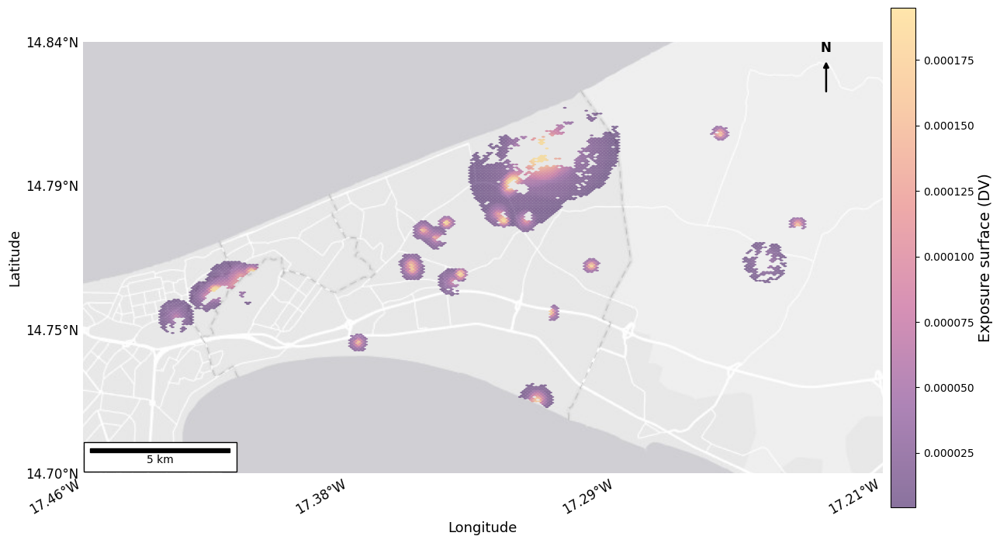

Grid points plotted  : 13,041
99th percentile DV   : 0.000195
Output figure        :
/content/drive/MyDrive/Paper_3/Processing/DV/Revised/Dakar/Dakar_Exposure_Surface_2024_revised.png

Dakar 2016
Source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Dakar/dakar_grid30m_DV_2016_revised.csv
UTM: EPSG:32628


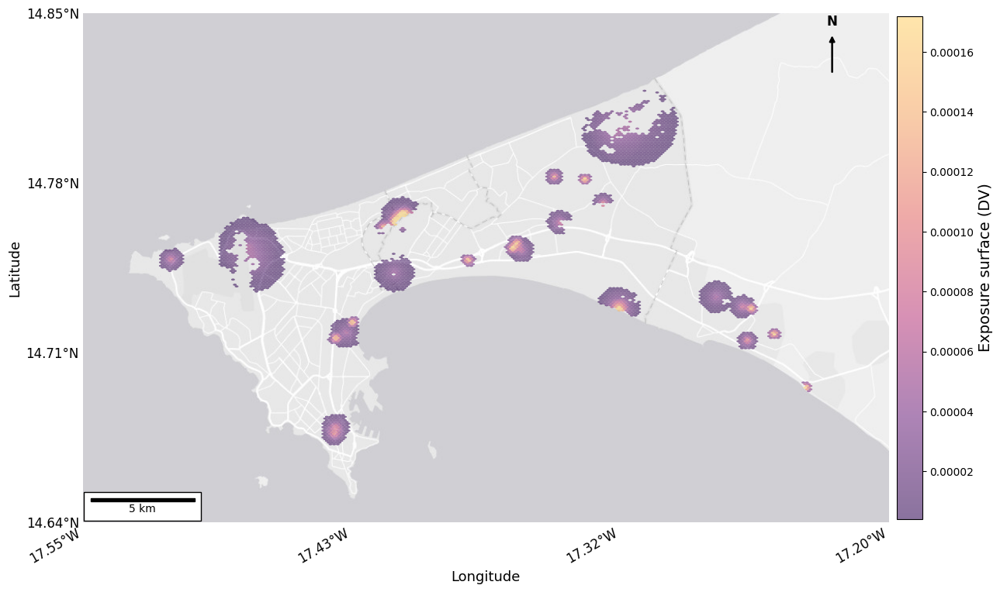

Grid points plotted  : 22,614
99th percentile DV   : 0.000172
Output figure        :
/content/drive/MyDrive/Paper_3/Processing/DV/Revised/Dakar/Dakar_Exposure_Surface_2016_revised.png

BOTH SURFACES COMPLETE
2024: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Dakar/Dakar_Exposure_Surface_2024_revised.png
2016: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Dakar/Dakar_Exposure_Surface_2016_revised.png


In [ ]:
# =============================================================================
# EXPOSURE SURFACE VISUALIZATION (REVISED DV) — BOTH YEARS
# Independent per-year colour scaling (each year clipped at its own q99)
# =============================================================================

import os
import math
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.font_manager as fm
import contextily as ctx
from pyproj import CRS, Transformer
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

warnings.filterwarnings("ignore")

# =============================================================================
# CONFIG
# =============================================================================
CITY = "Dakar"
YEARS = [2024, 2016]

# Per-city extent padding overrides (default 0.12/0.12 if not listed here).
# Dakar: deliberately elongated vertical pad (0.22) for its peninsula geography.
PAD_OVERRIDES = {
    "Dakar": {"padx_factor": 0.12, "pady_factor": 0.22},
}
padx_factor, pady_factor = PAD_OVERRIDES.get(CITY, {"padx_factor": 0.12, "pady_factor": 0.12}).values()

IN_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
OUT_DIR = IN_DIR
os.makedirs(OUT_DIR, exist_ok=True)

FIGSIZE = (13, 13)
DPI = 300

# =============================================================================
# COLOURMAP
# =============================================================================
exposure_cmap = mcolors.LinearSegmentedColormap.from_list(
    "Exposure",
    ["#2b004f", "#6a1f7a", "#b63679", "#e16462", "#f4a261", "#ffd166"],
    N=256
)

# =============================================================================
# CRS HELPERS
# =============================================================================
CRS_WEB = CRS.from_epsg(3857)
CRS_WGS = CRS.from_epsg(4326)

def utm_epsg(lon, lat):
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"

# =============================================================================
# NORTH ARROW
# =============================================================================
def add_north_arrow(ax):
    ax.annotate("", xy=(0.93, 0.96), xytext=(0.93, 0.88), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"))
    ax.text(0.93, 0.97, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=12, fontweight="bold")

# =============================================================================
# SCALE BAR
# =============================================================================
def add_scalebar(ax):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(ax.transData, 5000, "5 km", "lower left", pad=0.6,
                                color="black", frameon=True, size_vertical=150,
                                fontproperties=fontprops)
    ax.add_artist(scalebar)

# =============================================================================
# LAT/LON TICKS
# =============================================================================
def format_lon(x):
    return f"{abs(x):.2f}°{'E' if x >= 0 else 'W'}"

def format_lat(y):
    return f"{abs(y):.2f}°{'N' if y >= 0 else 'S'}"

def add_latlon_ticks(ax):
    transformer = Transformer.from_crs(CRS_WEB, CRS_WGS, always_xy=True)
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    xticks = np.linspace(xmin, xmax, 4)
    yticks = np.linspace(ymin, ymax, 4)
    yc = (ymin + ymax) / 2
    xc = (xmin + xmax) / 2
    lons = [transformer.transform(x, yc)[0] for x in xticks]
    lats = [transformer.transform(xc, y)[1] for y in yticks]
    ax.set_xticks(xticks)
    ax.set_xticklabels([format_lon(i) for i in lons], fontsize=12, rotation=30, ha="right")
    ax.set_yticks(yticks)
    ax.set_yticklabels([format_lat(i) for i in lats], fontsize=12)
    ax.set_xlabel("Longitude", fontsize=13)
    ax.set_ylabel("Latitude", fontsize=13)

# =============================================================================
# PLOT ONE YEAR
# =============================================================================
def plot_year(city, year, in_dir, out_dir, padx_f, pady_f):
    csv = os.path.join(in_dir, f"{city.lower()}_grid30m_DV_{year}_revised.csv")
    out_fig = os.path.join(out_dir, f"{city}_Exposure_Surface_{year}_revised.png")

    print("=" * 70)
    print(f"{city} {year}")
    print("=" * 70)
    print(f"Source: {csv}")

    df = pd.read_csv(csv)
    required = ["longitude", "latitude", "DV_log1p"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")

    epsg = utm_epsg(df.longitude.mean(), df.latitude.mean())
    print("UTM:", epsg)

    gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude),
                            crs="EPSG:4326").to_crs(epsg)
    gdf["DV_raw"] = np.expm1(gdf["DV_log1p"])
    gdf = gdf.to_crs(3857)

    nz = gdf[gdf["DV_raw"] > 0].copy()
    q99 = nz["DV_raw"].quantile(0.99)   # independent per-year scale
    nz["DV_plot"] = nz["DV_raw"].clip(upper=q99)
    if len(nz) > 120000:
        nz = nz.sample(120000, random_state=42)

    xmin, ymin, xmax, ymax = nz.total_bounds
    padx = (xmax - xmin) * padx_f
    pady = (ymax - ymin) * pady_f

    fig, ax = plt.subplots(figsize=FIGSIZE)
    ax.set_xlim(xmin - padx, xmax + padx)
    ax.set_ylim(ymin - pady, ymax + pady)
    ax.set_aspect("equal", adjustable="box")

    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas, attribution=False, zorder=0)

    hb = ax.hexbin(nz.geometry.x.values, nz.geometry.y.values, C=nz["DV_plot"].values,
                    reduce_C_function=np.mean, gridsize=180, mincnt=1, linewidths=0,
                    alpha=0.55, cmap=exposure_cmap, zorder=5)

    cbar = fig.colorbar(hb, ax=ax, fraction=0.03, pad=0.01)
    cbar.set_label("Exposure surface (DV)", fontsize=14)

    add_north_arrow(ax)
    add_scalebar(ax)
    add_latlon_ticks(ax)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="both", length=0)

    plt.tight_layout()
    plt.savefig(out_fig, dpi=DPI, bbox_inches="tight", facecolor="white")
    plt.show()

    print(f"Grid points plotted  : {len(nz):,}")
    print(f"99th percentile DV   : {q99:.6f}")
    print(f"Output figure        :\n{out_fig}\n")

    return out_fig

# =============================================================================
# RUN BOTH YEARS
# =============================================================================
outputs = {}
for year in YEARS:
    outputs[year] = plot_year(CITY, year, IN_DIR, OUT_DIR, padx_factor, pady_factor)

print("=" * 70)
print("BOTH SURFACES COMPLETE")
print("=" * 70)
for year, path in outputs.items():
    print(f"{year}: {path}")

Freetown

In [ ]:
# =============================================================================
# REVISED DIFFERENTIAL-SPREAD DV GENERATION (Freetown 2024)
# 500m² FLOOR + SIZE-SCALED RADIUS (200m-2km) + STEEPENED DECAY (H_HALF=0.30)
# BLOCK 1 — CONFIGURATION, KMZ LOADING, SITE PREPROCESSING & KD-TREE
# =============================================================================

import os
import zipfile
import tempfile
import warnings
import fiona
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

# --- CONFIGURATION ------------------------------------------------------

CITY = "Freetown"
YEAR = 2024

EPSG = 32628   # confirmed
BETA = 0.57    # confirmed

KMZ_FILE  = f"/content/drive/MyDrive/Paper_3/Sites/{YEAR}/{CITY}/{CITY}_{YEAR}.kmz"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"

OUT_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
os.makedirs(OUT_DIR, exist_ok=True)
OUTPUT_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_{YEAR}_revised.csv")

# 2024 reads the original master grid
GRID_CSV = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets/{CITY.lower()}_grid30m_master_merged_withDV.csv"

# --- LOCKED DESIGN PARAMETERS (same for all cities/years) -------------------

MIN_AREA_M2    = 500.0
MIN_RADIUS_M   = 200.0
MAX_RADIUS_M   = 2000.0
CAP_PERCENTILE = 99
H_HALF         = 0.30
TAU            = 1.0

# --- CITY-SPECIFIC AREA CAP (pooled 2016+2024, from site CSVs) --------------

print("=" * 70)
print(f"Computing area cap for {CITY} (pooled 2016+2024)...")
print("=" * 70)

areas_pooled = []
for y in [2016, 2024]:
    sites_csv = pd.read_csv(f"{SITES_DIR}/{y}/{CITY}/{CITY}_{y}_sites.csv")
    sites_csv = sites_csv.dropna(subset=["area"])
    sites_csv = sites_csv[sites_csv["area"] >= MIN_AREA_M2]
    areas_pooled.extend(sites_csv["area"].values)

AREA_CAP_M2 = np.percentile(areas_pooled, CAP_PERCENTILE)
print(f"{CITY}: n={len(areas_pooled):,} qualifying sites (both years), "
      f"p{CAP_PERCENTILE} area cap = {AREA_CAP_M2:,.1f} m² ({AREA_CAP_M2/10000:.2f} ha)")

# --- LOAD & PROJECT KMZ (target year's own site geometries) -----------------

print("\n" + "=" * 70)
print("Loading KMZ...")
print("=" * 70)

tmpdir = tempfile.mkdtemp()
with zipfile.ZipFile(KMZ_FILE, "r") as z:
    z.extractall(tmpdir)

kml_files = [
    os.path.join(root, f)
    for root, _, files in os.walk(tmpdir)
    for f in files if f.lower().endswith(".kml")
]
if not kml_files:
    raise RuntimeError("No KML file found inside KMZ.")

kml_file = kml_files[0]
print(f"KML found: {kml_file}")

fiona.drvsupport.supported_drivers["KML"] = "rw"
sites = gpd.read_file(kml_file, driver="KML").set_geometry("geometry")

if sites.crs is None:
    sites = sites.set_crs(4326)
sites = sites.to_crs(EPSG)
print(f"Loaded {len(sites)} geometries, projected to EPSG:{EPSG}")

# --- EXPLODE, FILTER TO POLYGONS, COMPUTE AREA -------------------------

sites = sites.explode(index_parts=False).reset_index(drop=True)
sites = sites[sites.geometry.type.isin(["Polygon", "MultiPolygon"])].copy()
print(f"Polygon features: {len(sites)}")
if len(sites) == 0:
    raise RuntimeError("No polygons found.")

sites["area_m2"] = sites.geometry.area
sites = sites[np.isfinite(sites["area_m2"]) & (sites["area_m2"] > 0)].copy()
print(f"Valid polygons: {len(sites)}")

# --- 500 m² FLOOR -------------------------------------------------------

n_before_floor = len(sites)
sites = sites[sites["area_m2"] >= MIN_AREA_M2].copy()
print(f"Sites >= {MIN_AREA_M2:.0f} m²: {len(sites)} (dropped {n_before_floor - len(sites)} smaller sites)")
if len(sites) == 0:
    raise RuntimeError(f"No sites >= {MIN_AREA_M2:.0f} m² for {CITY} {YEAR}.")

# --- CENTROIDS -----------------------------------------------------------

sites["centroid"] = sites.geometry.centroid
site_pts = sites.set_geometry("centroid").copy()

site_xy = np.column_stack((site_pts.geometry.x.values, site_pts.geometry.y.values))
areas = site_pts["area_m2"].to_numpy(dtype=float)

# --- SIZE-SCALED RADII (200m-2km, city-specific p99 cap) -------------------

print("\nComputing size-scaled radii...")

capped_area = np.minimum(areas, AREA_CAP_M2)
score = (np.log(capped_area) - np.log(MIN_AREA_M2)) / (np.log(AREA_CAP_M2) - np.log(MIN_AREA_M2))
r_j = MIN_RADIUS_M + (MAX_RADIUS_M - MIN_RADIUS_M) * score

lambda_j = np.log(2.0) / (H_HALF * r_j)
K_j = (lambda_j ** 2) / (2.0 * np.pi)
mass_j = np.power(np.maximum(areas, 1.0), BETA)

# --- KD-TREE ---------------------------------------------------------------

tree = cKDTree(site_xy)
R_QUERY = TAU * np.max(r_j)
print("\nKD Tree constructed.")

# --- LOAD GRID COORDINATES --------------------------------------------------

print("\nLoading grid coordinates...")
print(f"Grid source: {GRID_CSV}")

grid = pd.read_csv(GRID_CSV, usecols=["grid_point", "longitude", "latitude"]).dropna()
print(f"Grid points: {len(grid):,}")

grid_gdf = gpd.GeoDataFrame(
    grid,
    geometry=gpd.points_from_xy(grid.longitude, grid.latitude),
    crs=4326
).to_crs(EPSG)

points_xy = np.column_stack((grid_gdf.geometry.x.values, grid_gdf.geometry.y.values))

# --- DIAGNOSTICS -------------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)
print(f"City / year                : {CITY} {YEAR}")
print(f"EPSG / BETA (per-city)     : {EPSG} / {BETA}")
print(f"Min area / min radius      : {MIN_AREA_M2:.0f} m² / {MIN_RADIUS_M:.0f} m")
print(f"Area cap (p{CAP_PERCENTILE}) / max radius : {AREA_CAP_M2:,.1f} m² / {MAX_RADIUS_M:.0f} m")
print(f"H_HALF / TAU                : {H_HALF} / {TAU}")
print(f"Sites retained (>= floor)   : {len(site_pts):,}")
print(f"Grid points                 : {len(points_xy):,}")
print(f"Mean site area (m²)         : {areas.mean():.2f}")
print(f"Median site area (m²)       : {np.median(areas):.2f}")
print("\nSize-scaled radius summary (m)")
print(pd.Series(r_j).describe())
print(f"\nMaximum search radius: {R_QUERY:.2f} m")
print(f"\nOutput will be saved to:\n{OUTPUT_CSV}")
print("\nBlock 1 completed successfully. Proceed to Block 2.")

Computing area cap for Freetown (pooled 2016+2024)...
Freetown: n=80 qualifying sites (both years), p99 area cap = 24,997.7 m² (2.50 ha)

Loading KMZ...
KML found: /tmp/tmpdikqaqzy/doc.kml
Loaded 487 geometries, projected to EPSG:32628
Polygon features: 487
Valid polygons: 487
Sites >= 500 m²: 47 (dropped 440 smaller sites)

Computing size-scaled radii...

KD Tree constructed.

Loading grid coordinates...
Grid source: /content/drive/MyDrive/Results_2/Data_2024/Processed/Freetown/Final_datasets/freetown_grid30m_master_merged_withDV.csv
Grid points: 134,087

SUMMARY
City / year                : Freetown 2024
EPSG / BETA (per-city)     : 32628 / 0.57
Min area / min radius      : 500 m² / 200 m
Area cap (p99) / max radius : 24,997.7 m² / 2000 m
H_HALF / TAU                : 0.3 / 1.0
Sites retained (>= floor)   : 47
Grid points                 : 134,087
Mean site area (m²)         : 2468.05
Median site area (m²)       : 798.64

Size-scaled radius summary (m)
count      47.000000
mean      

In [ ]:
# =============================================================================
# BLOCK 2 — COMPUTE DIFFERENTIAL-SPREAD DV AT EVERY 30 m GRID POINT + SAVE
# =============================================================================

import time

print("=" * 70)
print("Computing DV at 30 m grid points...")
print("=" * 70)

t0 = time.time()

N = len(points_xy)
DV_pts = np.zeros(N, dtype=np.float64)
overlap_pts = np.zeros(N, dtype=np.int16)

BATCH_SIZE = 5000
print(f"Grid points : {N:,}")
print(f"Batch size  : {BATCH_SIZE:,}")
print(f"Total batches: {int(np.ceil(N / BATCH_SIZE))}")

for start in range(0, N, BATCH_SIZE):
    end = min(start + BATCH_SIZE, N)
    batch_points = points_xy[start:end]

    neighbour_lists = tree.query_ball_point(batch_points, r=R_QUERY)

    for i, neighbours in enumerate(neighbour_lists):
        if len(neighbours) == 0:
            continue

        pt = batch_points[i]
        cand_xy = site_xy[neighbours]

        dx = cand_xy[:, 0] - pt[0]
        dy = cand_xy[:, 1] - pt[1]
        d = np.sqrt(dx * dx + dy * dy)

        r_local = r_j[neighbours]
        keep = d <= (TAU * r_local)
        if not np.any(keep):
            continue

        d = d[keep]
        lam = lambda_j[neighbours][keep]
        K = K_j[neighbours][keep]
        mass = mass_j[neighbours][keep]

        contrib = mass * K * np.exp(-lam * d)
        DV_pts[start + i] = contrib.sum()
        overlap_pts[start + i] = keep.sum()

    processed = end
    pct = processed / N * 100
    elapsed = time.time() - t0
    rate = processed / elapsed
    remaining = (N - processed) / rate if rate > 0 else np.nan
    print(f"{processed:>8,} / {N:,} ({pct:5.1f}%)   Elapsed: {elapsed:6.1f}s   ETA: {remaining:6.1f}s")

print("\nFinished DV computation.")

DV_log = np.log1p(DV_pts)

print(f"Non-zero grid points : {(DV_pts>0).sum():,}")
print(f"Maximum overlap      : {overlap_pts.max()}")
print(f"Maximum DV           : {DV_pts.max():.6f}")
print(f"Mean DV              : {DV_pts.mean():.6f}")
print(f"Median DV            : {np.median(DV_pts):.6f}")

print("\n" + "=" * 70)
print("Saving output...")
print("=" * 70)

out_df = pd.DataFrame({
    "grid_point": grid["grid_point"].values,
    "longitude": grid["longitude"].values,
    "latitude": grid["latitude"].values,
    "DV_hex_diffspread": DV_pts,
    "DV_log1p": DV_log,
    "n_sites": overlap_pts
}).sort_values("grid_point").reset_index(drop=True)

os.makedirs(OUT_DIR, exist_ok=True)
out_df.to_csv(OUTPUT_CSV, index=False)

runtime = time.time() - t0
pct_list = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

print("\n" + "=" * 70)
print("OUTPUT SUMMARY")
print("=" * 70)
print(f"Output file:\n{OUTPUT_CSV}\n")
print(f"Rows written                : {len(out_df):,}")
print(f"Non-zero DV                 : {(out_df.DV_hex_diffspread>0).sum():,}")
print(f"Zero DV                     : {(out_df.DV_hex_diffspread==0).sum():,}")
print(f"Maximum contributing sites  : {out_df.n_sites.max()}")
print(f"Mean contributing sites     : {out_df.n_sites[out_df.n_sites>0].mean():.2f}")

print("\nDV summary")
print(out_df["DV_hex_diffspread"].describe(percentiles=pct_list))

print("\nDV_log1p summary")
print(out_df["DV_log1p"].describe(percentiles=pct_list))

print(f"\nProcessing time : {runtime:.1f} seconds")
print("\n✓ Revised DV successfully generated.")
print(f"\nSaved to:\n{OUTPUT_CSV}")

Computing DV at 30 m grid points...
Grid points : 134,087
Batch size  : 5,000
Total batches: 27
   5,000 / 134,087 (  3.7%)   Elapsed:    0.3s   ETA:    6.6s
  10,000 / 134,087 (  7.5%)   Elapsed:    0.5s   ETA:    6.0s
  15,000 / 134,087 ( 11.2%)   Elapsed:    0.7s   ETA:    5.4s
  20,000 / 134,087 ( 14.9%)   Elapsed:    0.9s   ETA:    4.9s
  25,000 / 134,087 ( 18.6%)   Elapsed:    1.0s   ETA:    4.3s
  30,000 / 134,087 ( 22.4%)   Elapsed:    1.1s   ETA:    4.0s
  35,000 / 134,087 ( 26.1%)   Elapsed:    1.2s   ETA:    3.5s
  40,000 / 134,087 ( 29.8%)   Elapsed:    1.3s   ETA:    3.1s
  45,000 / 134,087 ( 33.6%)   Elapsed:    1.4s   ETA:    2.8s
  50,000 / 134,087 ( 37.3%)   Elapsed:    1.5s   ETA:    2.5s
  55,000 / 134,087 ( 41.0%)   Elapsed:    1.6s   ETA:    2.3s
  60,000 / 134,087 ( 44.7%)   Elapsed:    1.7s   ETA:    2.1s
  65,000 / 134,087 ( 48.5%)   Elapsed:    1.8s   ETA:    1.9s
  70,000 / 134,087 ( 52.2%)   Elapsed:    1.9s   ETA:    1.7s
  75,000 / 134,087 ( 55.9%)   Elapse

2016

In [ ]:
# =============================================================================
# REVISED DIFFERENTIAL-SPREAD DV GENERATION (Freetown 2016)
# 500m² FLOOR + SIZE-SCALED RADIUS (200m-2km) + STEEPENED DECAY (H_HALF=0.30)
# COMBINED — CONFIG, KMZ LOADING, KD-TREE, DV COMPUTATION & SAVE
# =============================================================================

import os
import zipfile
import tempfile
import warnings
import time
import fiona
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

# --- CONFIGURATION ------------------------------------------------------

CITY = "Freetown"
YEAR = 2016

EPSG = 32628   # confirmed, matches Freetown 2024
BETA = 0.57    # confirmed, matches Freetown 2024

KMZ_FILE  = f"/content/drive/MyDrive/Paper_3/Sites/{YEAR}/{CITY}/{CITY}_{YEAR}.kmz"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"

OUT_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
os.makedirs(OUT_DIR, exist_ok=True)
OUTPUT_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_{YEAR}_revised.csv")

# 2016 reuses 2024's own REVISED output as the grid source (same grid_point set)
GRID_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_2024_revised.csv")
if not os.path.exists(GRID_CSV):
    raise RuntimeError(
        f"2024 revised output not found for {CITY} — run YEAR=2024 first, "
        f"since 2016 reuses its grid for cross-year consistency."
    )

# --- LOCKED DESIGN PARAMETERS (same for all cities/years) -------------------

MIN_AREA_M2    = 500.0
MIN_RADIUS_M   = 200.0
MAX_RADIUS_M   = 2000.0
CAP_PERCENTILE = 99
H_HALF         = 0.30
TAU            = 1.0

# --- CITY-SPECIFIC AREA CAP (pooled 2016+2024, from site CSVs) --------------

print("=" * 70)
print(f"Computing area cap for {CITY} (pooled 2016+2024)...")
print("=" * 70)

areas_pooled = []
for y in [2016, 2024]:
    sites_csv = pd.read_csv(f"{SITES_DIR}/{y}/{CITY}/{CITY}_{y}_sites.csv")
    sites_csv = sites_csv.dropna(subset=["area"])
    sites_csv = sites_csv[sites_csv["area"] >= MIN_AREA_M2]
    areas_pooled.extend(sites_csv["area"].values)

AREA_CAP_M2 = np.percentile(areas_pooled, CAP_PERCENTILE)
print(f"{CITY}: n={len(areas_pooled):,} qualifying sites (both years), "
      f"p{CAP_PERCENTILE} area cap = {AREA_CAP_M2:,.1f} m² ({AREA_CAP_M2/10000:.2f} ha)")

# --- LOAD & PROJECT KMZ (target year's own site geometries) -----------------

print("\n" + "=" * 70)
print("Loading KMZ...")
print("=" * 70)

tmpdir = tempfile.mkdtemp()
with zipfile.ZipFile(KMZ_FILE, "r") as z:
    z.extractall(tmpdir)

kml_files = [
    os.path.join(root, f)
    for root, _, files in os.walk(tmpdir)
    for f in files if f.lower().endswith(".kml")
]
if not kml_files:
    raise RuntimeError("No KML file found inside KMZ.")

kml_file = kml_files[0]
print(f"KML found: {kml_file}")

fiona.drvsupport.supported_drivers["KML"] = "rw"
sites = gpd.read_file(kml_file, driver="KML").set_geometry("geometry")

if sites.crs is None:
    sites = sites.set_crs(4326)
sites = sites.to_crs(EPSG)
print(f"Loaded {len(sites)} geometries, projected to EPSG:{EPSG}")

# --- EXPLODE, FILTER TO POLYGONS, COMPUTE AREA -------------------------

sites = sites.explode(index_parts=False).reset_index(drop=True)
sites = sites[sites.geometry.type.isin(["Polygon", "MultiPolygon"])].copy()
print(f"Polygon features: {len(sites)}")
if len(sites) == 0:
    raise RuntimeError("No polygons found.")

sites["area_m2"] = sites.geometry.area
sites = sites[np.isfinite(sites["area_m2"]) & (sites["area_m2"] > 0)].copy()
print(f"Valid polygons: {len(sites)}")

# --- 500 m² FLOOR -------------------------------------------------------

n_before_floor = len(sites)
sites = sites[sites["area_m2"] >= MIN_AREA_M2].copy()
print(f"Sites >= {MIN_AREA_M2:.0f} m²: {len(sites)} (dropped {n_before_floor - len(sites)} smaller sites)")
if len(sites) == 0:
    raise RuntimeError(f"No sites >= {MIN_AREA_M2:.0f} m² for {CITY} {YEAR}.")

# --- CENTROIDS -----------------------------------------------------------

sites["centroid"] = sites.geometry.centroid
site_pts = sites.set_geometry("centroid").copy()

site_xy = np.column_stack((site_pts.geometry.x.values, site_pts.geometry.y.values))
areas = site_pts["area_m2"].to_numpy(dtype=float)

# --- SIZE-SCALED RADII (200m-2km, city-specific p99 cap) -------------------

print("\nComputing size-scaled radii...")

capped_area = np.minimum(areas, AREA_CAP_M2)
score = (np.log(capped_area) - np.log(MIN_AREA_M2)) / (np.log(AREA_CAP_M2) - np.log(MIN_AREA_M2))
r_j = MIN_RADIUS_M + (MAX_RADIUS_M - MIN_RADIUS_M) * score

lambda_j = np.log(2.0) / (H_HALF * r_j)
K_j = (lambda_j ** 2) / (2.0 * np.pi)
mass_j = np.power(np.maximum(areas, 1.0), BETA)

# --- KD-TREE ---------------------------------------------------------------

tree = cKDTree(site_xy)
R_QUERY = TAU * np.max(r_j)
print("\nKD Tree constructed.")

# --- LOAD GRID COORDINATES --------------------------------------------------

print("\nLoading grid coordinates...")
print(f"Grid source: {GRID_CSV}")

grid = pd.read_csv(GRID_CSV, usecols=["grid_point", "longitude", "latitude"]).dropna()
print(f"Grid points: {len(grid):,}")

grid_gdf = gpd.GeoDataFrame(
    grid,
    geometry=gpd.points_from_xy(grid.longitude, grid.latitude),
    crs=4326
).to_crs(EPSG)

points_xy = np.column_stack((grid_gdf.geometry.x.values, grid_gdf.geometry.y.values))

# --- BLOCK 1 DIAGNOSTICS -----------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY (site/grid setup)")
print("=" * 70)
print(f"City / year                : {CITY} {YEAR}")
print(f"EPSG / BETA (per-city)     : {EPSG} / {BETA}")
print(f"Min area / min radius      : {MIN_AREA_M2:.0f} m² / {MIN_RADIUS_M:.0f} m")
print(f"Area cap (p{CAP_PERCENTILE}) / max radius : {AREA_CAP_M2:,.1f} m² / {MAX_RADIUS_M:.0f} m")
print(f"H_HALF / TAU                : {H_HALF} / {TAU}")
print(f"Sites retained (>= floor)   : {len(site_pts):,}")
print(f"Grid points                 : {len(points_xy):,}")
print(f"Mean site area (m²)         : {areas.mean():.2f}")
print(f"Median site area (m²)       : {np.median(areas):.2f}")
print("\nSize-scaled radius summary (m)")
print(pd.Series(r_j).describe())
print(f"\nMaximum search radius: {R_QUERY:.2f} m")

# =============================================================================
# DV COMPUTATION — every 30 m grid point + save
# =============================================================================

print("\n" + "=" * 70)
print("Computing DV at 30 m grid points...")
print("=" * 70)

t0 = time.time()

N = len(points_xy)
DV_pts = np.zeros(N, dtype=np.float64)
overlap_pts = np.zeros(N, dtype=np.int16)

BATCH_SIZE = 5000
print(f"Grid points : {N:,}")
print(f"Batch size  : {BATCH_SIZE:,}")
print(f"Total batches: {int(np.ceil(N / BATCH_SIZE))}")

for start in range(0, N, BATCH_SIZE):
    end = min(start + BATCH_SIZE, N)
    batch_points = points_xy[start:end]

    neighbour_lists = tree.query_ball_point(batch_points, r=R_QUERY)

    for i, neighbours in enumerate(neighbour_lists):
        if len(neighbours) == 0:
            continue

        pt = batch_points[i]
        cand_xy = site_xy[neighbours]

        dx = cand_xy[:, 0] - pt[0]
        dy = cand_xy[:, 1] - pt[1]
        d = np.sqrt(dx * dx + dy * dy)

        r_local = r_j[neighbours]
        keep = d <= (TAU * r_local)
        if not np.any(keep):
            continue

        d = d[keep]
        lam = lambda_j[neighbours][keep]
        K = K_j[neighbours][keep]
        mass = mass_j[neighbours][keep]

        contrib = mass * K * np.exp(-lam * d)
        DV_pts[start + i] = contrib.sum()
        overlap_pts[start + i] = keep.sum()

    processed = end
    pct = processed / N * 100
    elapsed = time.time() - t0
    rate = processed / elapsed
    remaining = (N - processed) / rate if rate > 0 else np.nan
    print(f"{processed:>8,} / {N:,} ({pct:5.1f}%)   Elapsed: {elapsed:6.1f}s   ETA: {remaining:6.1f}s")

print("\nFinished DV computation.")

DV_log = np.log1p(DV_pts)

print(f"Non-zero grid points : {(DV_pts>0).sum():,}")
print(f"Maximum overlap      : {overlap_pts.max()}")
print(f"Maximum DV           : {DV_pts.max():.6f}")
print(f"Mean DV              : {DV_pts.mean():.6f}")
print(f"Median DV            : {np.median(DV_pts):.6f}")

# --- BUILD & SAVE OUTPUT ------------------------------------------------------

print("\n" + "=" * 70)
print("Saving output...")
print("=" * 70)

out_df = pd.DataFrame({
    "grid_point": grid["grid_point"].values,
    "longitude": grid["longitude"].values,
    "latitude": grid["latitude"].values,
    "DV_hex_diffspread": DV_pts,
    "DV_log1p": DV_log,
    "n_sites": overlap_pts
}).sort_values("grid_point").reset_index(drop=True)

os.makedirs(OUT_DIR, exist_ok=True)
out_df.to_csv(OUTPUT_CSV, index=False)

runtime = time.time() - t0
pct_list = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

print("\n" + "=" * 70)
print("OUTPUT SUMMARY")
print("=" * 70)
print(f"Output file:\n{OUTPUT_CSV}\n")
print(f"Rows written                : {len(out_df):,}")
print(f"Non-zero DV                 : {(out_df.DV_hex_diffspread>0).sum():,}")
print(f"Zero DV                     : {(out_df.DV_hex_diffspread==0).sum():,}")
print(f"Maximum contributing sites  : {out_df.n_sites.max()}")
print(f"Mean contributing sites     : {out_df.n_sites[out_df.n_sites>0].mean():.2f}")

print("\nDV summary")
print(out_df["DV_hex_diffspread"].describe(percentiles=pct_list))

print("\nDV_log1p summary")
print(out_df["DV_log1p"].describe(percentiles=pct_list))

print(f"\nProcessing time : {runtime:.1f} seconds")
print("\n✓ Revised DV successfully generated.")
print(f"\nSaved to:\n{OUTPUT_CSV}")

Computing area cap for Freetown (pooled 2016+2024)...
Freetown: n=80 qualifying sites (both years), p99 area cap = 24,997.7 m² (2.50 ha)

Loading KMZ...
KML found: /tmp/tmpgbfvyuij/doc.kml
Loaded 312 geometries, projected to EPSG:32628
Polygon features: 312
Valid polygons: 312
Sites >= 500 m²: 33 (dropped 279 smaller sites)

Computing size-scaled radii...

KD Tree constructed.

Loading grid coordinates...
Grid source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Freetown/freetown_grid30m_DV_2024_revised.csv
Grid points: 134,087

SUMMARY (site/grid setup)
City / year                : Freetown 2016
EPSG / BETA (per-city)     : 32628 / 0.57
Min area / min radius      : 500 m² / 200 m
Area cap (p99) / max radius : 24,997.7 m² / 2000 m
H_HALF / TAU                : 0.3 / 1.0
Sites retained (>= floor)   : 33
Grid points                 : 134,087
Mean site area (m²)         : 1259.67
Median site area (m²)       : 737.07

Size-scaled radius summary (m)
count      33.000000
mean      47

Freetown 2024
Source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Freetown/freetown_grid30m_DV_2024_revised.csv
UTM: EPSG:32628


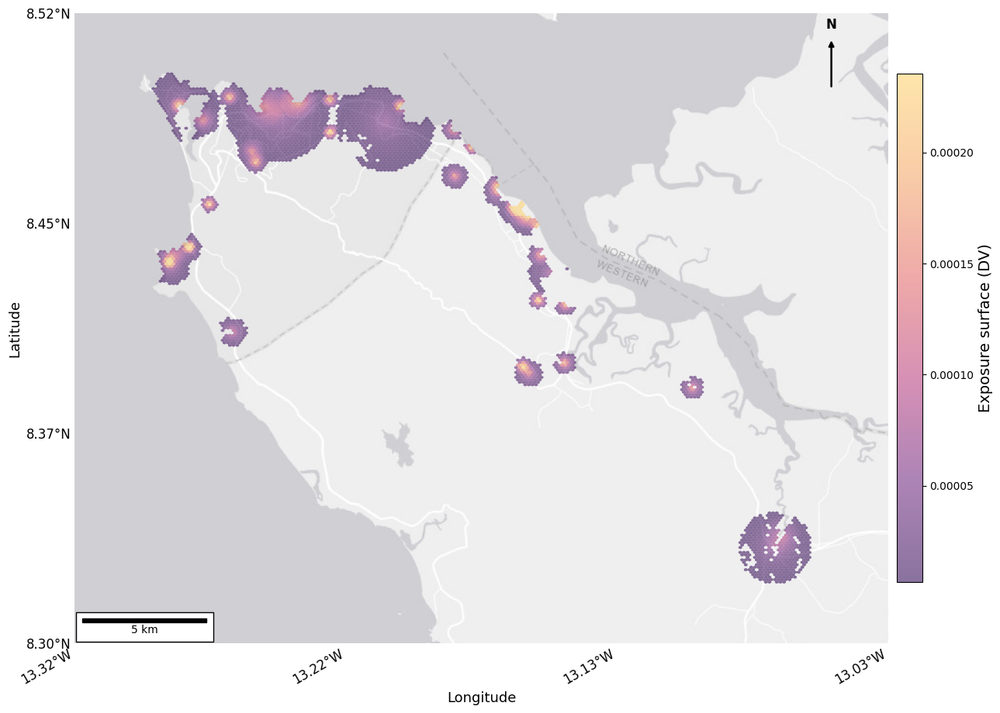

Grid points plotted  : 29,855
99th percentile DV   : 0.000235
Output figure        :
/content/drive/MyDrive/Paper_3/Processing/DV/Revised/Freetown/Freetown_Exposure_Surface_2024_revised.png

Freetown 2016
Source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Freetown/freetown_grid30m_DV_2016_revised.csv
UTM: EPSG:32628


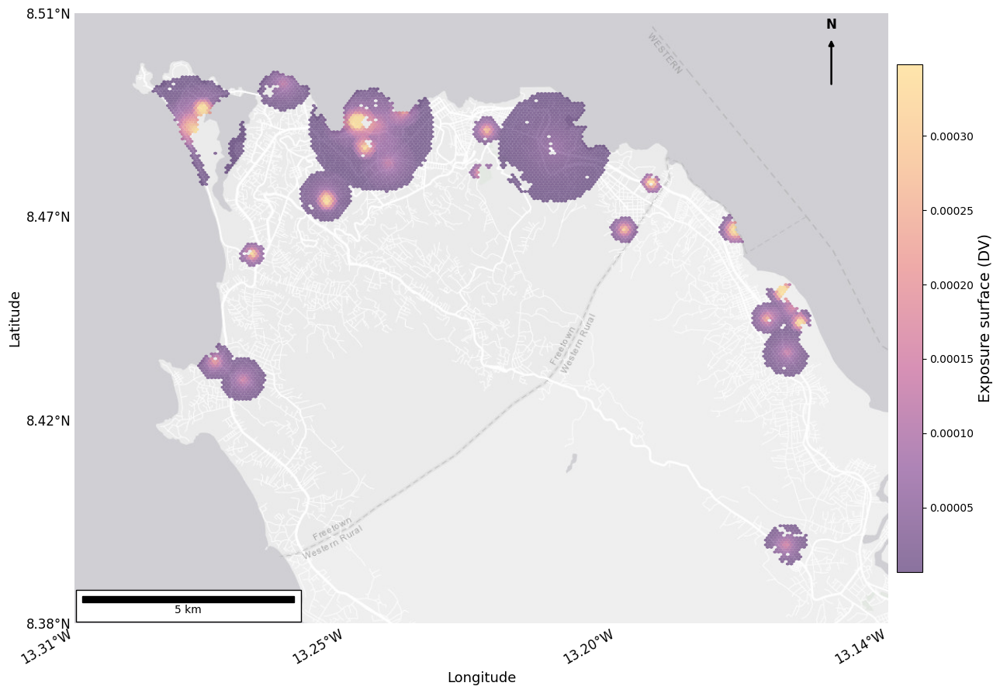

Grid points plotted  : 16,007
99th percentile DV   : 0.000348
Output figure        :
/content/drive/MyDrive/Paper_3/Processing/DV/Revised/Freetown/Freetown_Exposure_Surface_2016_revised.png

BOTH SURFACES COMPLETE
2024: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Freetown/Freetown_Exposure_Surface_2024_revised.png
2016: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Freetown/Freetown_Exposure_Surface_2016_revised.png


In [ ]:
# =============================================================================
# EXPOSURE SURFACE VISUALIZATION (REVISED DV) — BOTH YEARS
# Independent per-year colour scaling (each year clipped at its own q99)
# =============================================================================

import os
import math
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.font_manager as fm
import contextily as ctx
from pyproj import CRS, Transformer
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

warnings.filterwarnings("ignore")

# =============================================================================
# CONFIG
# =============================================================================
CITY = "Freetown"
YEARS = [2024, 2016]

# Per-city extent padding overrides (default 0.12/0.12 if not listed here).
# Dakar: deliberately elongated vertical pad (0.22) for its peninsula geography.
PAD_OVERRIDES = {
    "Dakar": {"padx_factor": 0.12, "pady_factor": 0.22},
}
padx_factor, pady_factor = PAD_OVERRIDES.get(CITY, {"padx_factor": 0.12, "pady_factor": 0.12}).values()

IN_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
OUT_DIR = IN_DIR
os.makedirs(OUT_DIR, exist_ok=True)

FIGSIZE = (13, 13)
DPI = 300

# =============================================================================
# COLOURMAP
# =============================================================================
exposure_cmap = mcolors.LinearSegmentedColormap.from_list(
    "Exposure",
    ["#2b004f", "#6a1f7a", "#b63679", "#e16462", "#f4a261", "#ffd166"],
    N=256
)

# =============================================================================
# CRS HELPERS
# =============================================================================
CRS_WEB = CRS.from_epsg(3857)
CRS_WGS = CRS.from_epsg(4326)

def utm_epsg(lon, lat):
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"

# =============================================================================
# NORTH ARROW
# =============================================================================
def add_north_arrow(ax):
    ax.annotate("", xy=(0.93, 0.96), xytext=(0.93, 0.88), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"))
    ax.text(0.93, 0.97, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=12, fontweight="bold")

# =============================================================================
# SCALE BAR
# =============================================================================
def add_scalebar(ax):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(ax.transData, 5000, "5 km", "lower left", pad=0.6,
                                color="black", frameon=True, size_vertical=150,
                                fontproperties=fontprops)
    ax.add_artist(scalebar)

# =============================================================================
# LAT/LON TICKS
# =============================================================================
def format_lon(x):
    return f"{abs(x):.2f}°{'E' if x >= 0 else 'W'}"

def format_lat(y):
    return f"{abs(y):.2f}°{'N' if y >= 0 else 'S'}"

def add_latlon_ticks(ax):
    transformer = Transformer.from_crs(CRS_WEB, CRS_WGS, always_xy=True)
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    xticks = np.linspace(xmin, xmax, 4)
    yticks = np.linspace(ymin, ymax, 4)
    yc = (ymin + ymax) / 2
    xc = (xmin + xmax) / 2
    lons = [transformer.transform(x, yc)[0] for x in xticks]
    lats = [transformer.transform(xc, y)[1] for y in yticks]
    ax.set_xticks(xticks)
    ax.set_xticklabels([format_lon(i) for i in lons], fontsize=12, rotation=30, ha="right")
    ax.set_yticks(yticks)
    ax.set_yticklabels([format_lat(i) for i in lats], fontsize=12)
    ax.set_xlabel("Longitude", fontsize=13)
    ax.set_ylabel("Latitude", fontsize=13)

# =============================================================================
# PLOT ONE YEAR
# =============================================================================
def plot_year(city, year, in_dir, out_dir, padx_f, pady_f):
    csv = os.path.join(in_dir, f"{city.lower()}_grid30m_DV_{year}_revised.csv")
    out_fig = os.path.join(out_dir, f"{city}_Exposure_Surface_{year}_revised.png")

    print("=" * 70)
    print(f"{city} {year}")
    print("=" * 70)
    print(f"Source: {csv}")

    df = pd.read_csv(csv)
    required = ["longitude", "latitude", "DV_log1p"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")

    epsg = utm_epsg(df.longitude.mean(), df.latitude.mean())
    print("UTM:", epsg)

    gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude),
                            crs="EPSG:4326").to_crs(epsg)
    gdf["DV_raw"] = np.expm1(gdf["DV_log1p"])
    gdf = gdf.to_crs(3857)

    nz = gdf[gdf["DV_raw"] > 0].copy()
    q99 = nz["DV_raw"].quantile(0.99)   # independent per-year scale
    nz["DV_plot"] = nz["DV_raw"].clip(upper=q99)
    if len(nz) > 120000:
        nz = nz.sample(120000, random_state=42)

    xmin, ymin, xmax, ymax = nz.total_bounds
    padx = (xmax - xmin) * padx_f
    pady = (ymax - ymin) * pady_f

    fig, ax = plt.subplots(figsize=FIGSIZE)
    ax.set_xlim(xmin - padx, xmax + padx)
    ax.set_ylim(ymin - pady, ymax + pady)
    ax.set_aspect("equal", adjustable="box")

    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas, attribution=False, zorder=0)

    hb = ax.hexbin(nz.geometry.x.values, nz.geometry.y.values, C=nz["DV_plot"].values,
                    reduce_C_function=np.mean, gridsize=180, mincnt=1, linewidths=0,
                    alpha=0.55, cmap=exposure_cmap, zorder=5)

    cbar = fig.colorbar(hb, ax=ax, fraction=0.03, pad=0.01)
    cbar.set_label("Exposure surface (DV)", fontsize=14)

    add_north_arrow(ax)
    add_scalebar(ax)
    add_latlon_ticks(ax)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="both", length=0)

    plt.tight_layout()
    plt.savefig(out_fig, dpi=DPI, bbox_inches="tight", facecolor="white")
    plt.show()

    print(f"Grid points plotted  : {len(nz):,}")
    print(f"99th percentile DV   : {q99:.6f}")
    print(f"Output figure        :\n{out_fig}\n")

    return out_fig

# =============================================================================
# RUN BOTH YEARS
# =============================================================================
outputs = {}
for year in YEARS:
    outputs[year] = plot_year(CITY, year, IN_DIR, OUT_DIR, padx_factor, pady_factor)

print("=" * 70)
print("BOTH SURFACES COMPLETE")
print("=" * 70)
for year, path in outputs.items():
    print(f"{year}: {path}")

Johannesburg

In [ ]:
# =============================================================================
# REVISED DIFFERENTIAL-SPREAD DV GENERATION (Johannesburg 2024)
# 500m² FLOOR + SIZE-SCALED RADIUS (200m-2km) + STEEPENED DECAY (H_HALF=0.30)
# COMBINED — CONFIG, KMZ LOADING, KD-TREE, DV COMPUTATION & SAVE
# =============================================================================

import os
import zipfile
import tempfile
import warnings
import time
import fiona
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

# --- CONFIGURATION ------------------------------------------------------

CITY = "Johannesburg"
YEAR = 2024

EPSG = 32735   # confirmed
BETA = 0.50    # confirmed

KMZ_FILE  = f"/content/drive/MyDrive/Paper_3/Sites/{YEAR}/{CITY}/{CITY}_{YEAR}.kmz"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"

OUT_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
os.makedirs(OUT_DIR, exist_ok=True)
OUTPUT_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_{YEAR}_revised.csv")

# 2024 reads the original master grid
GRID_CSV = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets/{CITY.lower()}_grid30m_master_merged_withDV.csv"

# --- LOCKED DESIGN PARAMETERS (same for all cities/years) -------------------

MIN_AREA_M2    = 500.0
MIN_RADIUS_M   = 200.0
MAX_RADIUS_M   = 2000.0
CAP_PERCENTILE = 99
H_HALF         = 0.30
TAU            = 1.0

# --- CITY-SPECIFIC AREA CAP (pooled 2016+2024, from site CSVs) --------------

print("=" * 70)
print(f"Computing area cap for {CITY} (pooled 2016+2024)...")
print("=" * 70)

areas_pooled = []
for y in [2016, 2024]:
    sites_csv = pd.read_csv(f"{SITES_DIR}/{y}/{CITY}/{CITY}_{y}_sites.csv")
    sites_csv = sites_csv.dropna(subset=["area"])
    sites_csv = sites_csv[sites_csv["area"] >= MIN_AREA_M2]
    areas_pooled.extend(sites_csv["area"].values)

AREA_CAP_M2 = np.percentile(areas_pooled, CAP_PERCENTILE)
print(f"{CITY}: n={len(areas_pooled):,} qualifying sites (both years), "
      f"p{CAP_PERCENTILE} area cap = {AREA_CAP_M2:,.1f} m² ({AREA_CAP_M2/10000:.2f} ha)")

# --- LOAD & PROJECT KMZ (target year's own site geometries) -----------------

print("\n" + "=" * 70)
print("Loading KMZ...")
print("=" * 70)

tmpdir = tempfile.mkdtemp()
with zipfile.ZipFile(KMZ_FILE, "r") as z:
    z.extractall(tmpdir)

kml_files = [
    os.path.join(root, f)
    for root, _, files in os.walk(tmpdir)
    for f in files if f.lower().endswith(".kml")
]
if not kml_files:
    raise RuntimeError("No KML file found inside KMZ.")

kml_file = kml_files[0]
print(f"KML found: {kml_file}")

fiona.drvsupport.supported_drivers["KML"] = "rw"
sites = gpd.read_file(kml_file, driver="KML").set_geometry("geometry")

if sites.crs is None:
    sites = sites.set_crs(4326)
sites = sites.to_crs(EPSG)
print(f"Loaded {len(sites)} geometries, projected to EPSG:{EPSG}")

# --- EXPLODE, FILTER TO POLYGONS, COMPUTE AREA -------------------------

sites = sites.explode(index_parts=False).reset_index(drop=True)
sites = sites[sites.geometry.type.isin(["Polygon", "MultiPolygon"])].copy()
print(f"Polygon features: {len(sites)}")
if len(sites) == 0:
    raise RuntimeError("No polygons found.")

sites["area_m2"] = sites.geometry.area
sites = sites[np.isfinite(sites["area_m2"]) & (sites["area_m2"] > 0)].copy()
print(f"Valid polygons: {len(sites)}")

# --- 500 m² FLOOR -------------------------------------------------------

n_before_floor = len(sites)
sites = sites[sites["area_m2"] >= MIN_AREA_M2].copy()
print(f"Sites >= {MIN_AREA_M2:.0f} m²: {len(sites)} (dropped {n_before_floor - len(sites)} smaller sites)")
if len(sites) == 0:
    raise RuntimeError(f"No sites >= {MIN_AREA_M2:.0f} m² for {CITY} {YEAR}.")

# --- CENTROIDS -----------------------------------------------------------

sites["centroid"] = sites.geometry.centroid
site_pts = sites.set_geometry("centroid").copy()

site_xy = np.column_stack((site_pts.geometry.x.values, site_pts.geometry.y.values))
areas = site_pts["area_m2"].to_numpy(dtype=float)

# --- SIZE-SCALED RADII (200m-2km, city-specific p99 cap) -------------------

print("\nComputing size-scaled radii...")

capped_area = np.minimum(areas, AREA_CAP_M2)
score = (np.log(capped_area) - np.log(MIN_AREA_M2)) / (np.log(AREA_CAP_M2) - np.log(MIN_AREA_M2))
r_j = MIN_RADIUS_M + (MAX_RADIUS_M - MIN_RADIUS_M) * score

lambda_j = np.log(2.0) / (H_HALF * r_j)
K_j = (lambda_j ** 2) / (2.0 * np.pi)
mass_j = np.power(np.maximum(areas, 1.0), BETA)

# --- KD-TREE ---------------------------------------------------------------

tree = cKDTree(site_xy)
R_QUERY = TAU * np.max(r_j)
print("\nKD Tree constructed.")

# --- LOAD GRID COORDINATES --------------------------------------------------

print("\nLoading grid coordinates...")
print(f"Grid source: {GRID_CSV}")

grid = pd.read_csv(GRID_CSV, usecols=["grid_point", "longitude", "latitude"]).dropna()
print(f"Grid points: {len(grid):,}")

grid_gdf = gpd.GeoDataFrame(
    grid,
    geometry=gpd.points_from_xy(grid.longitude, grid.latitude),
    crs=4326
).to_crs(EPSG)

points_xy = np.column_stack((grid_gdf.geometry.x.values, grid_gdf.geometry.y.values))

# --- SETUP DIAGNOSTICS -------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY (site/grid setup)")
print("=" * 70)
print(f"City / year                : {CITY} {YEAR}")
print(f"EPSG / BETA (per-city)     : {EPSG} / {BETA}")
print(f"Min area / min radius      : {MIN_AREA_M2:.0f} m² / {MIN_RADIUS_M:.0f} m")
print(f"Area cap (p{CAP_PERCENTILE}) / max radius : {AREA_CAP_M2:,.1f} m² / {MAX_RADIUS_M:.0f} m")
print(f"H_HALF / TAU                : {H_HALF} / {TAU}")
print(f"Sites retained (>= floor)   : {len(site_pts):,}")
print(f"Grid points                 : {len(points_xy):,}")
print(f"Mean site area (m²)         : {areas.mean():.2f}")
print(f"Median site area (m²)       : {np.median(areas):.2f}")
print("\nSize-scaled radius summary (m)")
print(pd.Series(r_j).describe())
print(f"\nMaximum search radius: {R_QUERY:.2f} m")

# =============================================================================
# DV COMPUTATION — every 30 m grid point + save
# =============================================================================

print("\n" + "=" * 70)
print("Computing DV at 30 m grid points...")
print("=" * 70)

t0 = time.time()

N = len(points_xy)
DV_pts = np.zeros(N, dtype=np.float64)
overlap_pts = np.zeros(N, dtype=np.int16)

BATCH_SIZE = 5000
print(f"Grid points : {N:,}")
print(f"Batch size  : {BATCH_SIZE:,}")
print(f"Total batches: {int(np.ceil(N / BATCH_SIZE))}")

for start in range(0, N, BATCH_SIZE):
    end = min(start + BATCH_SIZE, N)
    batch_points = points_xy[start:end]

    neighbour_lists = tree.query_ball_point(batch_points, r=R_QUERY)

    for i, neighbours in enumerate(neighbour_lists):
        if len(neighbours) == 0:
            continue

        pt = batch_points[i]
        cand_xy = site_xy[neighbours]

        dx = cand_xy[:, 0] - pt[0]
        dy = cand_xy[:, 1] - pt[1]
        d = np.sqrt(dx * dx + dy * dy)

        r_local = r_j[neighbours]
        keep = d <= (TAU * r_local)
        if not np.any(keep):
            continue

        d = d[keep]
        lam = lambda_j[neighbours][keep]
        K = K_j[neighbours][keep]
        mass = mass_j[neighbours][keep]

        contrib = mass * K * np.exp(-lam * d)
        DV_pts[start + i] = contrib.sum()
        overlap_pts[start + i] = keep.sum()

    processed = end
    pct = processed / N * 100
    elapsed = time.time() - t0
    rate = processed / elapsed
    remaining = (N - processed) / rate if rate > 0 else np.nan
    print(f"{processed:>8,} / {N:,} ({pct:5.1f}%)   Elapsed: {elapsed:6.1f}s   ETA: {remaining:6.1f}s")

print("\nFinished DV computation.")

DV_log = np.log1p(DV_pts)

print(f"Non-zero grid points : {(DV_pts>0).sum():,}")
print(f"Maximum overlap      : {overlap_pts.max()}")
print(f"Maximum DV           : {DV_pts.max():.6f}")
print(f"Mean DV              : {DV_pts.mean():.6f}")
print(f"Median DV            : {np.median(DV_pts):.6f}")

# --- BUILD & SAVE OUTPUT ------------------------------------------------------

print("\n" + "=" * 70)
print("Saving output...")
print("=" * 70)

out_df = pd.DataFrame({
    "grid_point": grid["grid_point"].values,
    "longitude": grid["longitude"].values,
    "latitude": grid["latitude"].values,
    "DV_hex_diffspread": DV_pts,
    "DV_log1p": DV_log,
    "n_sites": overlap_pts
}).sort_values("grid_point").reset_index(drop=True)

os.makedirs(OUT_DIR, exist_ok=True)
out_df.to_csv(OUTPUT_CSV, index=False)

runtime = time.time() - t0
pct_list = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

print("\n" + "=" * 70)
print("OUTPUT SUMMARY")
print("=" * 70)
print(f"Output file:\n{OUTPUT_CSV}\n")
print(f"Rows written                : {len(out_df):,}")
print(f"Non-zero DV                 : {(out_df.DV_hex_diffspread>0).sum():,}")
print(f"Zero DV                     : {(out_df.DV_hex_diffspread==0).sum():,}")
print(f"Maximum contributing sites  : {out_df.n_sites.max()}")
print(f"Mean contributing sites     : {out_df.n_sites[out_df.n_sites>0].mean():.2f}")

print("\nDV summary")
print(out_df["DV_hex_diffspread"].describe(percentiles=pct_list))

print("\nDV_log1p summary")
print(out_df["DV_log1p"].describe(percentiles=pct_list))

print(f"\nProcessing time : {runtime:.1f} seconds")
print("\n✓ Revised DV successfully generated.")
print(f"\nSaved to:\n{OUTPUT_CSV}")

Computing area cap for Johannesburg (pooled 2016+2024)...
Johannesburg: n=692 qualifying sites (both years), p99 area cap = 66,575.5 m² (6.66 ha)

Loading KMZ...
KML found: /tmp/tmplw87z2wv/doc.kml
Loaded 2976 geometries, projected to EPSG:32735
Polygon features: 2976
Valid polygons: 2975
Sites >= 500 m²: 488 (dropped 2487 smaller sites)

Computing size-scaled radii...

KD Tree constructed.

Loading grid coordinates...
Grid source: /content/drive/MyDrive/Results_2/Data_2024/Processed/Johannesburg/Final_datasets/johannesburg_grid30m_master_merged_withDV.csv
Grid points: 41,454

SUMMARY (site/grid setup)
City / year                : Johannesburg 2024
EPSG / BETA (per-city)     : 32735 / 0.5
Min area / min radius      : 500 m² / 200 m
Area cap (p99) / max radius : 66,575.5 m² / 2000 m
H_HALF / TAU                : 0.3 / 1.0
Sites retained (>= floor)   : 488
Grid points                 : 41,454
Mean site area (m²)         : 4329.12
Median site area (m²)       : 850.99

Size-scaled radius s

In [ ]:
# =============================================================================
# REVISED DIFFERENTIAL-SPREAD DV GENERATION (Johannesburg 2016)
# 500m² FLOOR + SIZE-SCALED RADIUS (200m-2km) + STEEPENED DECAY (H_HALF=0.30)
# COMBINED — CONFIG, KMZ LOADING, KD-TREE, DV COMPUTATION & SAVE
# =============================================================================

import os
import zipfile
import tempfile
import warnings
import time
import fiona
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

# --- CONFIGURATION ------------------------------------------------------

CITY = "Johannesburg"
YEAR = 2016

EPSG = 32735   # confirmed, matches Johannesburg 2024
BETA = 0.50    # confirmed, matches Johannesburg 2024

KMZ_FILE  = f"/content/drive/MyDrive/Paper_3/Sites/{YEAR}/{CITY}/{CITY}_{YEAR}.kmz"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"

OUT_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
os.makedirs(OUT_DIR, exist_ok=True)
OUTPUT_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_{YEAR}_revised.csv")

# 2016 reuses 2024's own REVISED output as the grid source (same grid_point set)
GRID_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_2024_revised.csv")
if not os.path.exists(GRID_CSV):
    raise RuntimeError(
        f"2024 revised output not found for {CITY} — run YEAR=2024 first, "
        f"since 2016 reuses its grid for cross-year consistency."
    )

# --- LOCKED DESIGN PARAMETERS (same for all cities/years) -------------------

MIN_AREA_M2    = 500.0
MIN_RADIUS_M   = 200.0
MAX_RADIUS_M   = 2000.0
CAP_PERCENTILE = 99
H_HALF         = 0.30
TAU            = 1.0

# --- CITY-SPECIFIC AREA CAP (pooled 2016+2024, from site CSVs) --------------

print("=" * 70)
print(f"Computing area cap for {CITY} (pooled 2016+2024)...")
print("=" * 70)

areas_pooled = []
for y in [2016, 2024]:
    sites_csv = pd.read_csv(f"{SITES_DIR}/{y}/{CITY}/{CITY}_{y}_sites.csv")
    sites_csv = sites_csv.dropna(subset=["area"])
    sites_csv = sites_csv[sites_csv["area"] >= MIN_AREA_M2]
    areas_pooled.extend(sites_csv["area"].values)

AREA_CAP_M2 = np.percentile(areas_pooled, CAP_PERCENTILE)
print(f"{CITY}: n={len(areas_pooled):,} qualifying sites (both years), "
      f"p{CAP_PERCENTILE} area cap = {AREA_CAP_M2:,.1f} m² ({AREA_CAP_M2/10000:.2f} ha)")

# --- LOAD & PROJECT KMZ (target year's own site geometries) -----------------

print("\n" + "=" * 70)
print("Loading KMZ...")
print("=" * 70)

tmpdir = tempfile.mkdtemp()
with zipfile.ZipFile(KMZ_FILE, "r") as z:
    z.extractall(tmpdir)

kml_files = [
    os.path.join(root, f)
    for root, _, files in os.walk(tmpdir)
    for f in files if f.lower().endswith(".kml")
]
if not kml_files:
    raise RuntimeError("No KML file found inside KMZ.")

kml_file = kml_files[0]
print(f"KML found: {kml_file}")

fiona.drvsupport.supported_drivers["KML"] = "rw"
sites = gpd.read_file(kml_file, driver="KML").set_geometry("geometry")

if sites.crs is None:
    sites = sites.set_crs(4326)
sites = sites.to_crs(EPSG)
print(f"Loaded {len(sites)} geometries, projected to EPSG:{EPSG}")

# --- EXPLODE, FILTER TO POLYGONS, COMPUTE AREA -------------------------

sites = sites.explode(index_parts=False).reset_index(drop=True)
sites = sites[sites.geometry.type.isin(["Polygon", "MultiPolygon"])].copy()
print(f"Polygon features: {len(sites)}")
if len(sites) == 0:
    raise RuntimeError("No polygons found.")

sites["area_m2"] = sites.geometry.area
sites = sites[np.isfinite(sites["area_m2"]) & (sites["area_m2"] > 0)].copy()
print(f"Valid polygons: {len(sites)}")

# --- 500 m² FLOOR -------------------------------------------------------

n_before_floor = len(sites)
sites = sites[sites["area_m2"] >= MIN_AREA_M2].copy()
print(f"Sites >= {MIN_AREA_M2:.0f} m²: {len(sites)} (dropped {n_before_floor - len(sites)} smaller sites)")
if len(sites) == 0:
    raise RuntimeError(f"No sites >= {MIN_AREA_M2:.0f} m² for {CITY} {YEAR}.")

# --- CENTROIDS -----------------------------------------------------------

sites["centroid"] = sites.geometry.centroid
site_pts = sites.set_geometry("centroid").copy()

site_xy = np.column_stack((site_pts.geometry.x.values, site_pts.geometry.y.values))
areas = site_pts["area_m2"].to_numpy(dtype=float)

# --- SIZE-SCALED RADII (200m-2km, city-specific p99 cap) -------------------

print("\nComputing size-scaled radii...")

capped_area = np.minimum(areas, AREA_CAP_M2)
score = (np.log(capped_area) - np.log(MIN_AREA_M2)) / (np.log(AREA_CAP_M2) - np.log(MIN_AREA_M2))
r_j = MIN_RADIUS_M + (MAX_RADIUS_M - MIN_RADIUS_M) * score

lambda_j = np.log(2.0) / (H_HALF * r_j)
K_j = (lambda_j ** 2) / (2.0 * np.pi)
mass_j = np.power(np.maximum(areas, 1.0), BETA)

# --- KD-TREE ---------------------------------------------------------------

tree = cKDTree(site_xy)
R_QUERY = TAU * np.max(r_j)
print("\nKD Tree constructed.")

# --- LOAD GRID COORDINATES --------------------------------------------------

print("\nLoading grid coordinates...")
print(f"Grid source: {GRID_CSV}")

grid = pd.read_csv(GRID_CSV, usecols=["grid_point", "longitude", "latitude"]).dropna()
print(f"Grid points: {len(grid):,}")

grid_gdf = gpd.GeoDataFrame(
    grid,
    geometry=gpd.points_from_xy(grid.longitude, grid.latitude),
    crs=4326
).to_crs(EPSG)

points_xy = np.column_stack((grid_gdf.geometry.x.values, grid_gdf.geometry.y.values))

# --- SETUP DIAGNOSTICS -------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY (site/grid setup)")
print("=" * 70)
print(f"City / year                : {CITY} {YEAR}")
print(f"EPSG / BETA (per-city)     : {EPSG} / {BETA}")
print(f"Min area / min radius      : {MIN_AREA_M2:.0f} m² / {MIN_RADIUS_M:.0f} m")
print(f"Area cap (p{CAP_PERCENTILE}) / max radius : {AREA_CAP_M2:,.1f} m² / {MAX_RADIUS_M:.0f} m")
print(f"H_HALF / TAU                : {H_HALF} / {TAU}")
print(f"Sites retained (>= floor)   : {len(site_pts):,}")
print(f"Grid points                 : {len(points_xy):,}")
print(f"Mean site area (m²)         : {areas.mean():.2f}")
print(f"Median site area (m²)       : {np.median(areas):.2f}")
print("\nSize-scaled radius summary (m)")
print(pd.Series(r_j).describe())
print(f"\nMaximum search radius: {R_QUERY:.2f} m")

# =============================================================================
# DV COMPUTATION — every 30 m grid point + save
# =============================================================================

print("\n" + "=" * 70)
print("Computing DV at 30 m grid points...")
print("=" * 70)

t0 = time.time()

N = len(points_xy)
DV_pts = np.zeros(N, dtype=np.float64)
overlap_pts = np.zeros(N, dtype=np.int16)

BATCH_SIZE = 5000
print(f"Grid points : {N:,}")
print(f"Batch size  : {BATCH_SIZE:,}")
print(f"Total batches: {int(np.ceil(N / BATCH_SIZE))}")

for start in range(0, N, BATCH_SIZE):
    end = min(start + BATCH_SIZE, N)
    batch_points = points_xy[start:end]

    neighbour_lists = tree.query_ball_point(batch_points, r=R_QUERY)

    for i, neighbours in enumerate(neighbour_lists):
        if len(neighbours) == 0:
            continue

        pt = batch_points[i]
        cand_xy = site_xy[neighbours]

        dx = cand_xy[:, 0] - pt[0]
        dy = cand_xy[:, 1] - pt[1]
        d = np.sqrt(dx * dx + dy * dy)

        r_local = r_j[neighbours]
        keep = d <= (TAU * r_local)
        if not np.any(keep):
            continue

        d = d[keep]
        lam = lambda_j[neighbours][keep]
        K = K_j[neighbours][keep]
        mass = mass_j[neighbours][keep]

        contrib = mass * K * np.exp(-lam * d)
        DV_pts[start + i] = contrib.sum()
        overlap_pts[start + i] = keep.sum()

    processed = end
    pct = processed / N * 100
    elapsed = time.time() - t0
    rate = processed / elapsed
    remaining = (N - processed) / rate if rate > 0 else np.nan
    print(f"{processed:>8,} / {N:,} ({pct:5.1f}%)   Elapsed: {elapsed:6.1f}s   ETA: {remaining:6.1f}s")

print("\nFinished DV computation.")

DV_log = np.log1p(DV_pts)

print(f"Non-zero grid points : {(DV_pts>0).sum():,}")
print(f"Maximum overlap      : {overlap_pts.max()}")
print(f"Maximum DV           : {DV_pts.max():.6f}")
print(f"Mean DV              : {DV_pts.mean():.6f}")
print(f"Median DV            : {np.median(DV_pts):.6f}")

# --- BUILD & SAVE OUTPUT ------------------------------------------------------

print("\n" + "=" * 70)
print("Saving output...")
print("=" * 70)

out_df = pd.DataFrame({
    "grid_point": grid["grid_point"].values,
    "longitude": grid["longitude"].values,
    "latitude": grid["latitude"].values,
    "DV_hex_diffspread": DV_pts,
    "DV_log1p": DV_log,
    "n_sites": overlap_pts
}).sort_values("grid_point").reset_index(drop=True)

os.makedirs(OUT_DIR, exist_ok=True)
out_df.to_csv(OUTPUT_CSV, index=False)

runtime = time.time() - t0
pct_list = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

print("\n" + "=" * 70)
print("OUTPUT SUMMARY")
print("=" * 70)
print(f"Output file:\n{OUTPUT_CSV}\n")
print(f"Rows written                : {len(out_df):,}")
print(f"Non-zero DV                 : {(out_df.DV_hex_diffspread>0).sum():,}")
print(f"Zero DV                     : {(out_df.DV_hex_diffspread==0).sum():,}")
print(f"Maximum contributing sites  : {out_df.n_sites.max()}")
print(f"Mean contributing sites     : {out_df.n_sites[out_df.n_sites>0].mean():.2f}")

print("\nDV summary")
print(out_df["DV_hex_diffspread"].describe(percentiles=pct_list))

print("\nDV_log1p summary")
print(out_df["DV_log1p"].describe(percentiles=pct_list))

print(f"\nProcessing time : {runtime:.1f} seconds")
print("\n✓ Revised DV successfully generated.")
print(f"\nSaved to:\n{OUTPUT_CSV}")

Computing area cap for Johannesburg (pooled 2016+2024)...
Johannesburg: n=692 qualifying sites (both years), p99 area cap = 66,575.5 m² (6.66 ha)

Loading KMZ...
KML found: /tmp/tmppcd2950w/doc.kml
Loaded 2007 geometries, projected to EPSG:32735
Polygon features: 2007
Valid polygons: 2007
Sites >= 500 m²: 204 (dropped 1803 smaller sites)

Computing size-scaled radii...

KD Tree constructed.

Loading grid coordinates...
Grid source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Johannesburg/johannesburg_grid30m_DV_2024_revised.csv
Grid points: 41,454

SUMMARY (site/grid setup)
City / year                : Johannesburg 2016
EPSG / BETA (per-city)     : 32735 / 0.5
Min area / min radius      : 500 m² / 200 m
Area cap (p99) / max radius : 66,575.5 m² / 2000 m
H_HALF / TAU                : 0.3 / 1.0
Sites retained (>= floor)   : 204
Grid points                 : 41,454
Mean site area (m²)         : 2508.84
Median site area (m²)       : 787.47

Size-scaled radius summary (m)
count    

Johannesburg 2024
Source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Johannesburg/johannesburg_grid30m_DV_2024_revised.csv
UTM: EPSG:32735


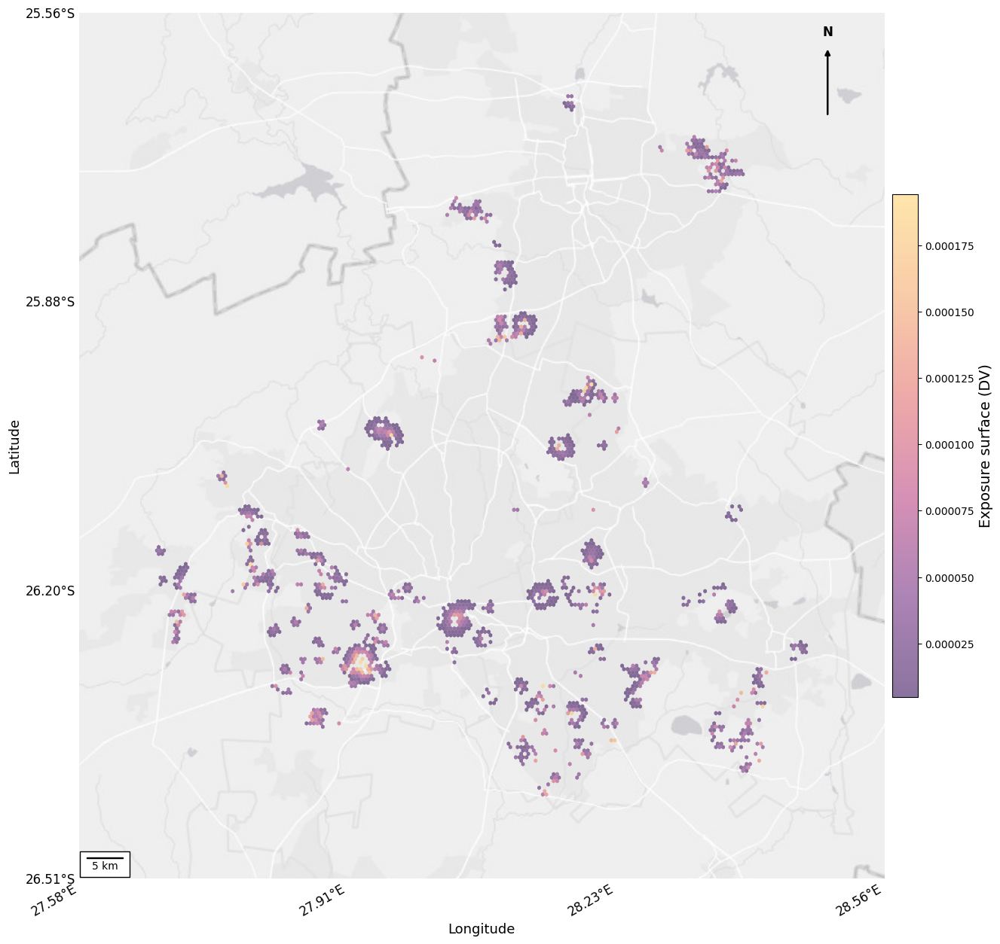

Grid points plotted  : 3,707
99th percentile DV   : 0.000194
Output figure        :
/content/drive/MyDrive/Paper_3/Processing/DV/Revised/Johannesburg/Johannesburg_Exposure_Surface_2024_revised.png

Johannesburg 2016
Source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Johannesburg/johannesburg_grid30m_DV_2016_revised.csv
UTM: EPSG:32735


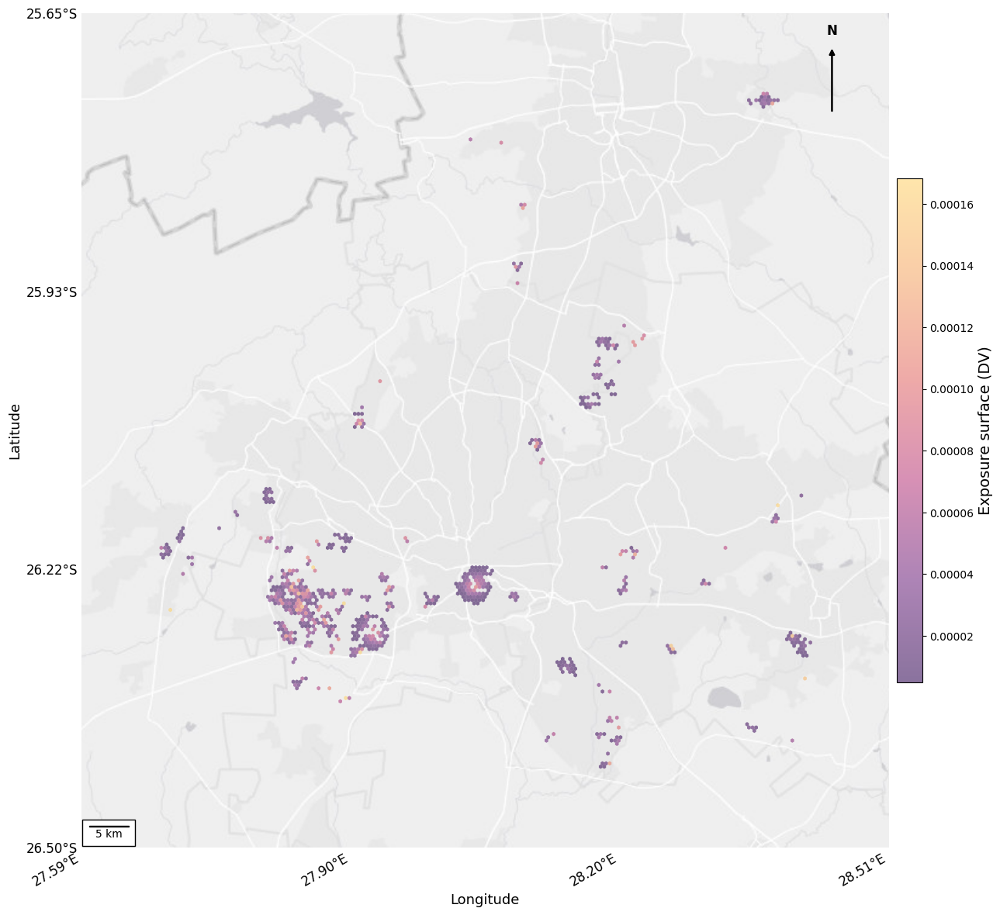

Grid points plotted  : 1,765
99th percentile DV   : 0.000168
Output figure        :
/content/drive/MyDrive/Paper_3/Processing/DV/Revised/Johannesburg/Johannesburg_Exposure_Surface_2016_revised.png

BOTH SURFACES COMPLETE
2024: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Johannesburg/Johannesburg_Exposure_Surface_2024_revised.png
2016: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Johannesburg/Johannesburg_Exposure_Surface_2016_revised.png


In [ ]:
# =============================================================================
# EXPOSURE SURFACE VISUALIZATION (REVISED DV) — BOTH YEARS
# Independent per-year colour scaling (each year clipped at its own q99)
# =============================================================================

import os
import math
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.font_manager as fm
import contextily as ctx
from pyproj import CRS, Transformer
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

warnings.filterwarnings("ignore")

# =============================================================================
# CONFIG
# =============================================================================
CITY = "Johannesburg"
YEARS = [2024, 2016]

# Per-city extent padding overrides (default 0.12/0.12 if not listed here).
# Dakar: deliberately elongated vertical pad (0.22) for its peninsula geography.
PAD_OVERRIDES = {
    "Dakar": {"padx_factor": 0.12, "pady_factor": 0.22},
}
padx_factor, pady_factor = PAD_OVERRIDES.get(CITY, {"padx_factor": 0.12, "pady_factor": 0.12}).values()

IN_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
OUT_DIR = IN_DIR
os.makedirs(OUT_DIR, exist_ok=True)

FIGSIZE = (13, 13)
DPI = 300

# =============================================================================
# COLOURMAP
# =============================================================================
exposure_cmap = mcolors.LinearSegmentedColormap.from_list(
    "Exposure",
    ["#2b004f", "#6a1f7a", "#b63679", "#e16462", "#f4a261", "#ffd166"],
    N=256
)

# =============================================================================
# CRS HELPERS
# =============================================================================
CRS_WEB = CRS.from_epsg(3857)
CRS_WGS = CRS.from_epsg(4326)

def utm_epsg(lon, lat):
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"

# =============================================================================
# NORTH ARROW
# =============================================================================
def add_north_arrow(ax):
    ax.annotate("", xy=(0.93, 0.96), xytext=(0.93, 0.88), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"))
    ax.text(0.93, 0.97, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=12, fontweight="bold")

# =============================================================================
# SCALE BAR
# =============================================================================
def add_scalebar(ax):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(ax.transData, 5000, "5 km", "lower left", pad=0.6,
                                color="black", frameon=True, size_vertical=150,
                                fontproperties=fontprops)
    ax.add_artist(scalebar)

# =============================================================================
# LAT/LON TICKS
# =============================================================================
def format_lon(x):
    return f"{abs(x):.2f}°{'E' if x >= 0 else 'W'}"

def format_lat(y):
    return f"{abs(y):.2f}°{'N' if y >= 0 else 'S'}"

def add_latlon_ticks(ax):
    transformer = Transformer.from_crs(CRS_WEB, CRS_WGS, always_xy=True)
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    xticks = np.linspace(xmin, xmax, 4)
    yticks = np.linspace(ymin, ymax, 4)
    yc = (ymin + ymax) / 2
    xc = (xmin + xmax) / 2
    lons = [transformer.transform(x, yc)[0] for x in xticks]
    lats = [transformer.transform(xc, y)[1] for y in yticks]
    ax.set_xticks(xticks)
    ax.set_xticklabels([format_lon(i) for i in lons], fontsize=12, rotation=30, ha="right")
    ax.set_yticks(yticks)
    ax.set_yticklabels([format_lat(i) for i in lats], fontsize=12)
    ax.set_xlabel("Longitude", fontsize=13)
    ax.set_ylabel("Latitude", fontsize=13)

# =============================================================================
# PLOT ONE YEAR
# =============================================================================
def plot_year(city, year, in_dir, out_dir, padx_f, pady_f):
    csv = os.path.join(in_dir, f"{city.lower()}_grid30m_DV_{year}_revised.csv")
    out_fig = os.path.join(out_dir, f"{city}_Exposure_Surface_{year}_revised.png")

    print("=" * 70)
    print(f"{city} {year}")
    print("=" * 70)
    print(f"Source: {csv}")

    df = pd.read_csv(csv)
    required = ["longitude", "latitude", "DV_log1p"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")

    epsg = utm_epsg(df.longitude.mean(), df.latitude.mean())
    print("UTM:", epsg)

    gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude),
                            crs="EPSG:4326").to_crs(epsg)
    gdf["DV_raw"] = np.expm1(gdf["DV_log1p"])
    gdf = gdf.to_crs(3857)

    nz = gdf[gdf["DV_raw"] > 0].copy()
    q99 = nz["DV_raw"].quantile(0.99)   # independent per-year scale
    nz["DV_plot"] = nz["DV_raw"].clip(upper=q99)
    if len(nz) > 120000:
        nz = nz.sample(120000, random_state=42)

    xmin, ymin, xmax, ymax = nz.total_bounds
    padx = (xmax - xmin) * padx_f
    pady = (ymax - ymin) * pady_f

    fig, ax = plt.subplots(figsize=FIGSIZE)
    ax.set_xlim(xmin - padx, xmax + padx)
    ax.set_ylim(ymin - pady, ymax + pady)
    ax.set_aspect("equal", adjustable="box")

    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas, attribution=False, zorder=0)

    hb = ax.hexbin(nz.geometry.x.values, nz.geometry.y.values, C=nz["DV_plot"].values,
                    reduce_C_function=np.mean, gridsize=180, mincnt=1, linewidths=0,
                    alpha=0.55, cmap=exposure_cmap, zorder=5)

    cbar = fig.colorbar(hb, ax=ax, fraction=0.03, pad=0.01)
    cbar.set_label("Exposure surface (DV)", fontsize=14)

    add_north_arrow(ax)
    add_scalebar(ax)
    add_latlon_ticks(ax)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="both", length=0)

    plt.tight_layout()
    plt.savefig(out_fig, dpi=DPI, bbox_inches="tight", facecolor="white")
    plt.show()

    print(f"Grid points plotted  : {len(nz):,}")
    print(f"99th percentile DV   : {q99:.6f}")
    print(f"Output figure        :\n{out_fig}\n")

    return out_fig

# =============================================================================
# RUN BOTH YEARS
# =============================================================================
outputs = {}
for year in YEARS:
    outputs[year] = plot_year(CITY, year, IN_DIR, OUT_DIR, padx_factor, pady_factor)

print("=" * 70)
print("BOTH SURFACES COMPLETE")
print("=" * 70)
for year, path in outputs.items():
    print(f"{year}: {path}")

Kampala

In [ ]:
# =============================================================================
# REVISED DIFFERENTIAL-SPREAD DV GENERATION (Kampala 2024)
# 500m² FLOOR + SIZE-SCALED RADIUS (200m-2km) + STEEPENED DECAY (H_HALF=0.30)
# COMBINED — CONFIG, KMZ LOADING, KD-TREE, DV COMPUTATION & SAVE
# =============================================================================

import os
import zipfile
import tempfile
import warnings
import time
import fiona
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

# --- CONFIGURATION ------------------------------------------------------

CITY = "Kampala"
YEAR = 2024

EPSG = 32636   # confirmed
BETA = 0.54    # confirmed

KMZ_FILE  = f"/content/drive/MyDrive/Paper_3/Sites/{YEAR}/{CITY}/{CITY}_{YEAR}.kmz"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"

OUT_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
os.makedirs(OUT_DIR, exist_ok=True)
OUTPUT_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_{YEAR}_revised.csv")

# 2024 reads the original master grid
GRID_CSV = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets/{CITY.lower()}_grid30m_master_merged_withDV.csv"

# --- LOCKED DESIGN PARAMETERS (same for all cities/years) -------------------

MIN_AREA_M2    = 500.0
MIN_RADIUS_M   = 200.0
MAX_RADIUS_M   = 2000.0
CAP_PERCENTILE = 99
H_HALF         = 0.30
TAU            = 1.0

# --- CITY-SPECIFIC AREA CAP (pooled 2016+2024, from site CSVs) --------------

print("=" * 70)
print(f"Computing area cap for {CITY} (pooled 2016+2024)...")
print("=" * 70)

areas_pooled = []
for y in [2016, 2024]:
    sites_csv = pd.read_csv(f"{SITES_DIR}/{y}/{CITY}/{CITY}_{y}_sites.csv")
    sites_csv = sites_csv.dropna(subset=["area"])
    sites_csv = sites_csv[sites_csv["area"] >= MIN_AREA_M2]
    areas_pooled.extend(sites_csv["area"].values)

AREA_CAP_M2 = np.percentile(areas_pooled, CAP_PERCENTILE)
print(f"{CITY}: n={len(areas_pooled):,} qualifying sites (both years), "
      f"p{CAP_PERCENTILE} area cap = {AREA_CAP_M2:,.1f} m² ({AREA_CAP_M2/10000:.2f} ha)")

# --- LOAD & PROJECT KMZ (target year's own site geometries) -----------------

print("\n" + "=" * 70)
print("Loading KMZ...")
print("=" * 70)

tmpdir = tempfile.mkdtemp()
with zipfile.ZipFile(KMZ_FILE, "r") as z:
    z.extractall(tmpdir)

kml_files = [
    os.path.join(root, f)
    for root, _, files in os.walk(tmpdir)
    for f in files if f.lower().endswith(".kml")
]
if not kml_files:
    raise RuntimeError("No KML file found inside KMZ.")

kml_file = kml_files[0]
print(f"KML found: {kml_file}")

fiona.drvsupport.supported_drivers["KML"] = "rw"
sites = gpd.read_file(kml_file, driver="KML").set_geometry("geometry")

if sites.crs is None:
    sites = sites.set_crs(4326)
sites = sites.to_crs(EPSG)
print(f"Loaded {len(sites)} geometries, projected to EPSG:{EPSG}")

# --- EXPLODE, FILTER TO POLYGONS, COMPUTE AREA -------------------------

sites = sites.explode(index_parts=False).reset_index(drop=True)
sites = sites[sites.geometry.type.isin(["Polygon", "MultiPolygon"])].copy()
print(f"Polygon features: {len(sites)}")
if len(sites) == 0:
    raise RuntimeError("No polygons found.")

sites["area_m2"] = sites.geometry.area
sites = sites[np.isfinite(sites["area_m2"]) & (sites["area_m2"] > 0)].copy()
print(f"Valid polygons: {len(sites)}")

# --- 500 m² FLOOR -------------------------------------------------------

n_before_floor = len(sites)
sites = sites[sites["area_m2"] >= MIN_AREA_M2].copy()
print(f"Sites >= {MIN_AREA_M2:.0f} m²: {len(sites)} (dropped {n_before_floor - len(sites)} smaller sites)")
if len(sites) == 0:
    raise RuntimeError(f"No sites >= {MIN_AREA_M2:.0f} m² for {CITY} {YEAR}.")

# --- CENTROIDS -----------------------------------------------------------

sites["centroid"] = sites.geometry.centroid
site_pts = sites.set_geometry("centroid").copy()

site_xy = np.column_stack((site_pts.geometry.x.values, site_pts.geometry.y.values))
areas = site_pts["area_m2"].to_numpy(dtype=float)

# --- SIZE-SCALED RADII (200m-2km, city-specific p99 cap) -------------------

print("\nComputing size-scaled radii...")

capped_area = np.minimum(areas, AREA_CAP_M2)
score = (np.log(capped_area) - np.log(MIN_AREA_M2)) / (np.log(AREA_CAP_M2) - np.log(MIN_AREA_M2))
r_j = MIN_RADIUS_M + (MAX_RADIUS_M - MIN_RADIUS_M) * score

lambda_j = np.log(2.0) / (H_HALF * r_j)
K_j = (lambda_j ** 2) / (2.0 * np.pi)
mass_j = np.power(np.maximum(areas, 1.0), BETA)

# --- KD-TREE ---------------------------------------------------------------

tree = cKDTree(site_xy)
R_QUERY = TAU * np.max(r_j)
print("\nKD Tree constructed.")

# --- LOAD GRID COORDINATES --------------------------------------------------

print("\nLoading grid coordinates...")
print(f"Grid source: {GRID_CSV}")

grid = pd.read_csv(GRID_CSV, usecols=["grid_point", "longitude", "latitude"]).dropna()
print(f"Grid points: {len(grid):,}")

grid_gdf = gpd.GeoDataFrame(
    grid,
    geometry=gpd.points_from_xy(grid.longitude, grid.latitude),
    crs=4326
).to_crs(EPSG)

points_xy = np.column_stack((grid_gdf.geometry.x.values, grid_gdf.geometry.y.values))

# --- SETUP DIAGNOSTICS -------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY (site/grid setup)")
print("=" * 70)
print(f"City / year                : {CITY} {YEAR}")
print(f"EPSG / BETA (per-city)     : {EPSG} / {BETA}")
print(f"Min area / min radius      : {MIN_AREA_M2:.0f} m² / {MIN_RADIUS_M:.0f} m")
print(f"Area cap (p{CAP_PERCENTILE}) / max radius : {AREA_CAP_M2:,.1f} m² / {MAX_RADIUS_M:.0f} m")
print(f"H_HALF / TAU                : {H_HALF} / {TAU}")
print(f"Sites retained (>= floor)   : {len(site_pts):,}")
print(f"Grid points                 : {len(points_xy):,}")
print(f"Mean site area (m²)         : {areas.mean():.2f}")
print(f"Median site area (m²)       : {np.median(areas):.2f}")
print("\nSize-scaled radius summary (m)")
print(pd.Series(r_j).describe())
print(f"\nMaximum search radius: {R_QUERY:.2f} m")

# =============================================================================
# DV COMPUTATION — every 30 m grid point + save
# =============================================================================

print("\n" + "=" * 70)
print("Computing DV at 30 m grid points...")
print("=" * 70)

t0 = time.time()

N = len(points_xy)
DV_pts = np.zeros(N, dtype=np.float64)
overlap_pts = np.zeros(N, dtype=np.int16)

BATCH_SIZE = 5000
print(f"Grid points : {N:,}")
print(f"Batch size  : {BATCH_SIZE:,}")
print(f"Total batches: {int(np.ceil(N / BATCH_SIZE))}")

for start in range(0, N, BATCH_SIZE):
    end = min(start + BATCH_SIZE, N)
    batch_points = points_xy[start:end]

    neighbour_lists = tree.query_ball_point(batch_points, r=R_QUERY)

    for i, neighbours in enumerate(neighbour_lists):
        if len(neighbours) == 0:
            continue

        pt = batch_points[i]
        cand_xy = site_xy[neighbours]

        dx = cand_xy[:, 0] - pt[0]
        dy = cand_xy[:, 1] - pt[1]
        d = np.sqrt(dx * dx + dy * dy)

        r_local = r_j[neighbours]
        keep = d <= (TAU * r_local)
        if not np.any(keep):
            continue

        d = d[keep]
        lam = lambda_j[neighbours][keep]
        K = K_j[neighbours][keep]
        mass = mass_j[neighbours][keep]

        contrib = mass * K * np.exp(-lam * d)
        DV_pts[start + i] = contrib.sum()
        overlap_pts[start + i] = keep.sum()

    processed = end
    pct = processed / N * 100
    elapsed = time.time() - t0
    rate = processed / elapsed
    remaining = (N - processed) / rate if rate > 0 else np.nan
    print(f"{processed:>8,} / {N:,} ({pct:5.1f}%)   Elapsed: {elapsed:6.1f}s   ETA: {remaining:6.1f}s")

print("\nFinished DV computation.")

DV_log = np.log1p(DV_pts)

print(f"Non-zero grid points : {(DV_pts>0).sum():,}")
print(f"Maximum overlap      : {overlap_pts.max()}")
print(f"Maximum DV           : {DV_pts.max():.6f}")
print(f"Mean DV              : {DV_pts.mean():.6f}")
print(f"Median DV            : {np.median(DV_pts):.6f}")

# --- BUILD & SAVE OUTPUT ------------------------------------------------------

print("\n" + "=" * 70)
print("Saving output...")
print("=" * 70)

out_df = pd.DataFrame({
    "grid_point": grid["grid_point"].values,
    "longitude": grid["longitude"].values,
    "latitude": grid["latitude"].values,
    "DV_hex_diffspread": DV_pts,
    "DV_log1p": DV_log,
    "n_sites": overlap_pts
}).sort_values("grid_point").reset_index(drop=True)

os.makedirs(OUT_DIR, exist_ok=True)
out_df.to_csv(OUTPUT_CSV, index=False)

runtime = time.time() - t0
pct_list = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

print("\n" + "=" * 70)
print("OUTPUT SUMMARY")
print("=" * 70)
print(f"Output file:\n{OUTPUT_CSV}\n")
print(f"Rows written                : {len(out_df):,}")
print(f"Non-zero DV                 : {(out_df.DV_hex_diffspread>0).sum():,}")
print(f"Zero DV                     : {(out_df.DV_hex_diffspread==0).sum():,}")
print(f"Maximum contributing sites  : {out_df.n_sites.max()}")
print(f"Mean contributing sites     : {out_df.n_sites[out_df.n_sites>0].mean():.2f}")

print("\nDV summary")
print(out_df["DV_hex_diffspread"].describe(percentiles=pct_list))

print("\nDV_log1p summary")
print(out_df["DV_log1p"].describe(percentiles=pct_list))

print(f"\nProcessing time : {runtime:.1f} seconds")
print("\n✓ Revised DV successfully generated.")
print(f"\nSaved to:\n{OUTPUT_CSV}")

Computing area cap for Kampala (pooled 2016+2024)...
Kampala: n=140 qualifying sites (both years), p99 area cap = 54,315.5 m² (5.43 ha)

Loading KMZ...
KML found: /tmp/tmpfxt6mi10/doc.kml
Loaded 992 geometries, projected to EPSG:32636
Polygon features: 992
Valid polygons: 992
Sites >= 500 m²: 94 (dropped 898 smaller sites)

Computing size-scaled radii...

KD Tree constructed.

Loading grid coordinates...
Grid source: /content/drive/MyDrive/Results_2/Data_2024/Processed/Kampala/Final_datasets/kampala_grid30m_master_merged_withDV.csv
Grid points: 375,874

SUMMARY (site/grid setup)
City / year                : Kampala 2024
EPSG / BETA (per-city)     : 32636 / 0.54
Min area / min radius      : 500 m² / 200 m
Area cap (p99) / max radius : 54,315.5 m² / 2000 m
H_HALF / TAU                : 0.3 / 1.0
Sites retained (>= floor)   : 94
Grid points                 : 375,874
Mean site area (m²)         : 2189.44
Median site area (m²)       : 839.87

Size-scaled radius summary (m)
count      94.000

In [ ]:
# =============================================================================
# REVISED DIFFERENTIAL-SPREAD DV GENERATION (Kampala 2016)
# 500m² FLOOR + SIZE-SCALED RADIUS (200m-2km) + STEEPENED DECAY (H_HALF=0.30)
# COMBINED — CONFIG, KMZ LOADING, KD-TREE, DV COMPUTATION & SAVE
# =============================================================================

import os
import zipfile
import tempfile
import warnings
import time
import fiona
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

# --- CONFIGURATION ------------------------------------------------------

CITY = "Kampala"
YEAR = 2016

EPSG = 32636   # confirmed, matches Kampala 2024
BETA = 0.54    # confirmed, matches Kampala 2024

KMZ_FILE  = f"/content/drive/MyDrive/Paper_3/Sites/{YEAR}/{CITY}/{CITY}_{YEAR}.kmz"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"

OUT_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
os.makedirs(OUT_DIR, exist_ok=True)
OUTPUT_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_{YEAR}_revised.csv")

# 2016 reuses 2024's own REVISED output as the grid source (same grid_point set)
GRID_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_2024_revised.csv")
if not os.path.exists(GRID_CSV):
    raise RuntimeError(
        f"2024 revised output not found for {CITY} — run YEAR=2024 first, "
        f"since 2016 reuses its grid for cross-year consistency."
    )

# --- LOCKED DESIGN PARAMETERS (same for all cities/years) -------------------

MIN_AREA_M2    = 500.0
MIN_RADIUS_M   = 200.0
MAX_RADIUS_M   = 2000.0
CAP_PERCENTILE = 99
H_HALF         = 0.30
TAU            = 1.0

# --- CITY-SPECIFIC AREA CAP (pooled 2016+2024, from site CSVs) --------------

print("=" * 70)
print(f"Computing area cap for {CITY} (pooled 2016+2024)...")
print("=" * 70)

areas_pooled = []
for y in [2016, 2024]:
    sites_csv = pd.read_csv(f"{SITES_DIR}/{y}/{CITY}/{CITY}_{y}_sites.csv")
    sites_csv = sites_csv.dropna(subset=["area"])
    sites_csv = sites_csv[sites_csv["area"] >= MIN_AREA_M2]
    areas_pooled.extend(sites_csv["area"].values)

AREA_CAP_M2 = np.percentile(areas_pooled, CAP_PERCENTILE)
print(f"{CITY}: n={len(areas_pooled):,} qualifying sites (both years), "
      f"p{CAP_PERCENTILE} area cap = {AREA_CAP_M2:,.1f} m² ({AREA_CAP_M2/10000:.2f} ha)")

# --- LOAD & PROJECT KMZ (target year's own site geometries) -----------------

print("\n" + "=" * 70)
print("Loading KMZ...")
print("=" * 70)

tmpdir = tempfile.mkdtemp()
with zipfile.ZipFile(KMZ_FILE, "r") as z:
    z.extractall(tmpdir)

kml_files = [
    os.path.join(root, f)
    for root, _, files in os.walk(tmpdir)
    for f in files if f.lower().endswith(".kml")
]
if not kml_files:
    raise RuntimeError("No KML file found inside KMZ.")

kml_file = kml_files[0]
print(f"KML found: {kml_file}")

fiona.drvsupport.supported_drivers["KML"] = "rw"
sites = gpd.read_file(kml_file, driver="KML").set_geometry("geometry")

if sites.crs is None:
    sites = sites.set_crs(4326)
sites = sites.to_crs(EPSG)
print(f"Loaded {len(sites)} geometries, projected to EPSG:{EPSG}")

# --- EXPLODE, FILTER TO POLYGONS, COMPUTE AREA -------------------------

sites = sites.explode(index_parts=False).reset_index(drop=True)
sites = sites[sites.geometry.type.isin(["Polygon", "MultiPolygon"])].copy()
print(f"Polygon features: {len(sites)}")
if len(sites) == 0:
    raise RuntimeError("No polygons found.")

sites["area_m2"] = sites.geometry.area
sites = sites[np.isfinite(sites["area_m2"]) & (sites["area_m2"] > 0)].copy()
print(f"Valid polygons: {len(sites)}")

# --- 500 m² FLOOR -------------------------------------------------------

n_before_floor = len(sites)
sites = sites[sites["area_m2"] >= MIN_AREA_M2].copy()
print(f"Sites >= {MIN_AREA_M2:.0f} m²: {len(sites)} (dropped {n_before_floor - len(sites)} smaller sites)")
if len(sites) == 0:
    raise RuntimeError(f"No sites >= {MIN_AREA_M2:.0f} m² for {CITY} {YEAR}.")

# --- CENTROIDS -----------------------------------------------------------

sites["centroid"] = sites.geometry.centroid
site_pts = sites.set_geometry("centroid").copy()

site_xy = np.column_stack((site_pts.geometry.x.values, site_pts.geometry.y.values))
areas = site_pts["area_m2"].to_numpy(dtype=float)

# --- SIZE-SCALED RADII (200m-2km, city-specific p99 cap) -------------------

print("\nComputing size-scaled radii...")

capped_area = np.minimum(areas, AREA_CAP_M2)
score = (np.log(capped_area) - np.log(MIN_AREA_M2)) / (np.log(AREA_CAP_M2) - np.log(MIN_AREA_M2))
r_j = MIN_RADIUS_M + (MAX_RADIUS_M - MIN_RADIUS_M) * score

lambda_j = np.log(2.0) / (H_HALF * r_j)
K_j = (lambda_j ** 2) / (2.0 * np.pi)
mass_j = np.power(np.maximum(areas, 1.0), BETA)

# --- KD-TREE ---------------------------------------------------------------

tree = cKDTree(site_xy)
R_QUERY = TAU * np.max(r_j)
print("\nKD Tree constructed.")

# --- LOAD GRID COORDINATES --------------------------------------------------

print("\nLoading grid coordinates...")
print(f"Grid source: {GRID_CSV}")

grid = pd.read_csv(GRID_CSV, usecols=["grid_point", "longitude", "latitude"]).dropna()
print(f"Grid points: {len(grid):,}")

grid_gdf = gpd.GeoDataFrame(
    grid,
    geometry=gpd.points_from_xy(grid.longitude, grid.latitude),
    crs=4326
).to_crs(EPSG)

points_xy = np.column_stack((grid_gdf.geometry.x.values, grid_gdf.geometry.y.values))

# --- SETUP DIAGNOSTICS -------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY (site/grid setup)")
print("=" * 70)
print(f"City / year                : {CITY} {YEAR}")
print(f"EPSG / BETA (per-city)     : {EPSG} / {BETA}")
print(f"Min area / min radius      : {MIN_AREA_M2:.0f} m² / {MIN_RADIUS_M:.0f} m")
print(f"Area cap (p{CAP_PERCENTILE}) / max radius : {AREA_CAP_M2:,.1f} m² / {MAX_RADIUS_M:.0f} m")
print(f"H_HALF / TAU                : {H_HALF} / {TAU}")
print(f"Sites retained (>= floor)   : {len(site_pts):,}")
print(f"Grid points                 : {len(points_xy):,}")
print(f"Mean site area (m²)         : {areas.mean():.2f}")
print(f"Median site area (m²)       : {np.median(areas):.2f}")
print("\nSize-scaled radius summary (m)")
print(pd.Series(r_j).describe())
print(f"\nMaximum search radius: {R_QUERY:.2f} m")

# =============================================================================
# DV COMPUTATION — every 30 m grid point + save
# =============================================================================

print("\n" + "=" * 70)
print("Computing DV at 30 m grid points...")
print("=" * 70)

t0 = time.time()

N = len(points_xy)
DV_pts = np.zeros(N, dtype=np.float64)
overlap_pts = np.zeros(N, dtype=np.int16)

BATCH_SIZE = 5000
print(f"Grid points : {N:,}")
print(f"Batch size  : {BATCH_SIZE:,}")
print(f"Total batches: {int(np.ceil(N / BATCH_SIZE))}")

for start in range(0, N, BATCH_SIZE):
    end = min(start + BATCH_SIZE, N)
    batch_points = points_xy[start:end]

    neighbour_lists = tree.query_ball_point(batch_points, r=R_QUERY)

    for i, neighbours in enumerate(neighbour_lists):
        if len(neighbours) == 0:
            continue

        pt = batch_points[i]
        cand_xy = site_xy[neighbours]

        dx = cand_xy[:, 0] - pt[0]
        dy = cand_xy[:, 1] - pt[1]
        d = np.sqrt(dx * dx + dy * dy)

        r_local = r_j[neighbours]
        keep = d <= (TAU * r_local)
        if not np.any(keep):
            continue

        d = d[keep]
        lam = lambda_j[neighbours][keep]
        K = K_j[neighbours][keep]
        mass = mass_j[neighbours][keep]

        contrib = mass * K * np.exp(-lam * d)
        DV_pts[start + i] = contrib.sum()
        overlap_pts[start + i] = keep.sum()

    processed = end
    pct = processed / N * 100
    elapsed = time.time() - t0
    rate = processed / elapsed
    remaining = (N - processed) / rate if rate > 0 else np.nan
    print(f"{processed:>8,} / {N:,} ({pct:5.1f}%)   Elapsed: {elapsed:6.1f}s   ETA: {remaining:6.1f}s")

print("\nFinished DV computation.")

DV_log = np.log1p(DV_pts)

print(f"Non-zero grid points : {(DV_pts>0).sum():,}")
print(f"Maximum overlap      : {overlap_pts.max()}")
print(f"Maximum DV           : {DV_pts.max():.6f}")
print(f"Mean DV              : {DV_pts.mean():.6f}")
print(f"Median DV            : {np.median(DV_pts):.6f}")

# --- BUILD & SAVE OUTPUT ------------------------------------------------------

print("\n" + "=" * 70)
print("Saving output...")
print("=" * 70)

out_df = pd.DataFrame({
    "grid_point": grid["grid_point"].values,
    "longitude": grid["longitude"].values,
    "latitude": grid["latitude"].values,
    "DV_hex_diffspread": DV_pts,
    "DV_log1p": DV_log,
    "n_sites": overlap_pts
}).sort_values("grid_point").reset_index(drop=True)

os.makedirs(OUT_DIR, exist_ok=True)
out_df.to_csv(OUTPUT_CSV, index=False)

runtime = time.time() - t0
pct_list = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

print("\n" + "=" * 70)
print("OUTPUT SUMMARY")
print("=" * 70)
print(f"Output file:\n{OUTPUT_CSV}\n")
print(f"Rows written                : {len(out_df):,}")
print(f"Non-zero DV                 : {(out_df.DV_hex_diffspread>0).sum():,}")
print(f"Zero DV                     : {(out_df.DV_hex_diffspread==0).sum():,}")
print(f"Maximum contributing sites  : {out_df.n_sites.max()}")
print(f"Mean contributing sites     : {out_df.n_sites[out_df.n_sites>0].mean():.2f}")

print("\nDV summary")
print(out_df["DV_hex_diffspread"].describe(percentiles=pct_list))

print("\nDV_log1p summary")
print(out_df["DV_log1p"].describe(percentiles=pct_list))

print(f"\nProcessing time : {runtime:.1f} seconds")
print("\n✓ Revised DV successfully generated.")
print(f"\nSaved to:\n{OUTPUT_CSV}")

Computing area cap for Kampala (pooled 2016+2024)...
Kampala: n=140 qualifying sites (both years), p99 area cap = 54,315.5 m² (5.43 ha)

Loading KMZ...
KML found: /tmp/tmpuve7wesd/doc.kml
Loaded 988 geometries, projected to EPSG:32636
Polygon features: 988
Valid polygons: 988
Sites >= 500 m²: 46 (dropped 942 smaller sites)

Computing size-scaled radii...

KD Tree constructed.

Loading grid coordinates...
Grid source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Kampala/kampala_grid30m_DV_2024_revised.csv
Grid points: 375,874

SUMMARY (site/grid setup)
City / year                : Kampala 2016
EPSG / BETA (per-city)     : 32636 / 0.54
Min area / min radius      : 500 m² / 200 m
Area cap (p99) / max radius : 54,315.5 m² / 2000 m
H_HALF / TAU                : 0.3 / 1.0
Sites retained (>= floor)   : 46
Grid points                 : 375,874
Mean site area (m²)         : 2997.89
Median site area (m²)       : 671.86

Size-scaled radius summary (m)
count      46.000000
mean      464.70

Kampala 2024
Source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Kampala/kampala_grid30m_DV_2024_revised.csv
UTM: EPSG:32636


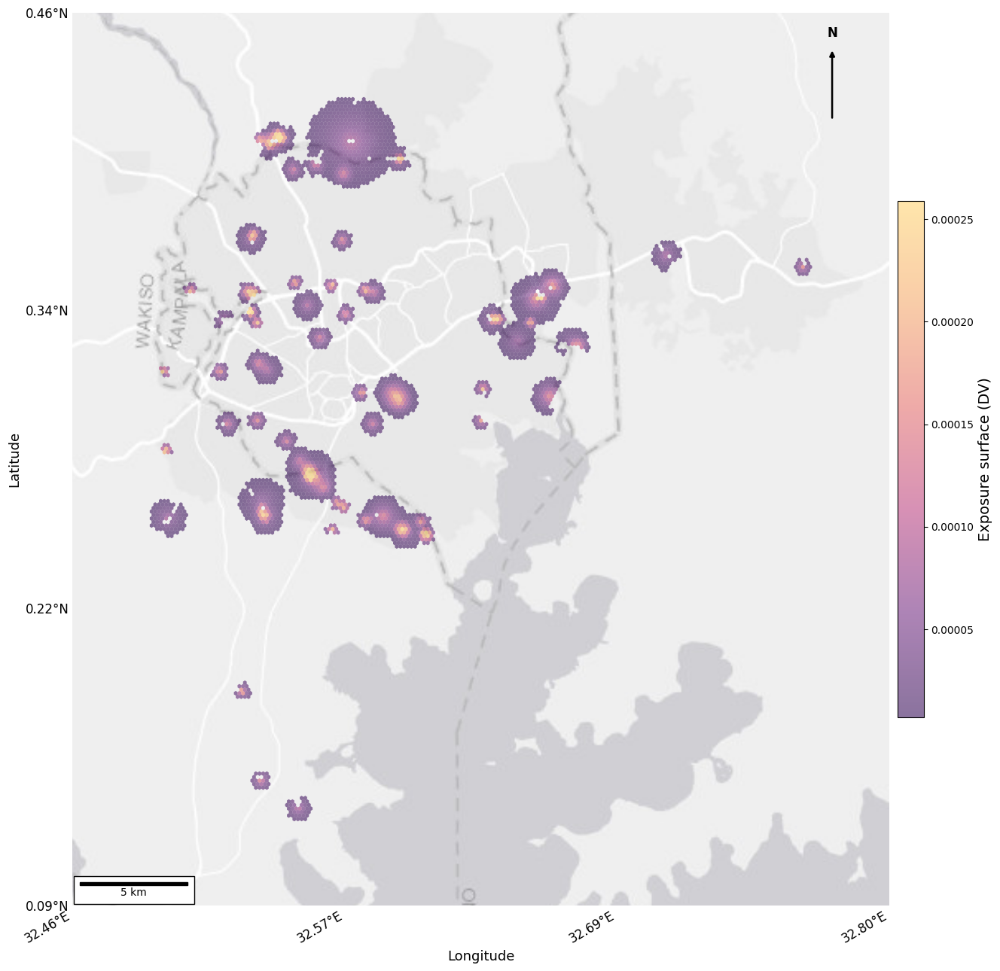

Grid points plotted  : 39,208
99th percentile DV   : 0.000259
Output figure        :
/content/drive/MyDrive/Paper_3/Processing/DV/Revised/Kampala/Kampala_Exposure_Surface_2024_revised.png

Kampala 2016
Source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Kampala/kampala_grid30m_DV_2016_revised.csv
UTM: EPSG:32636


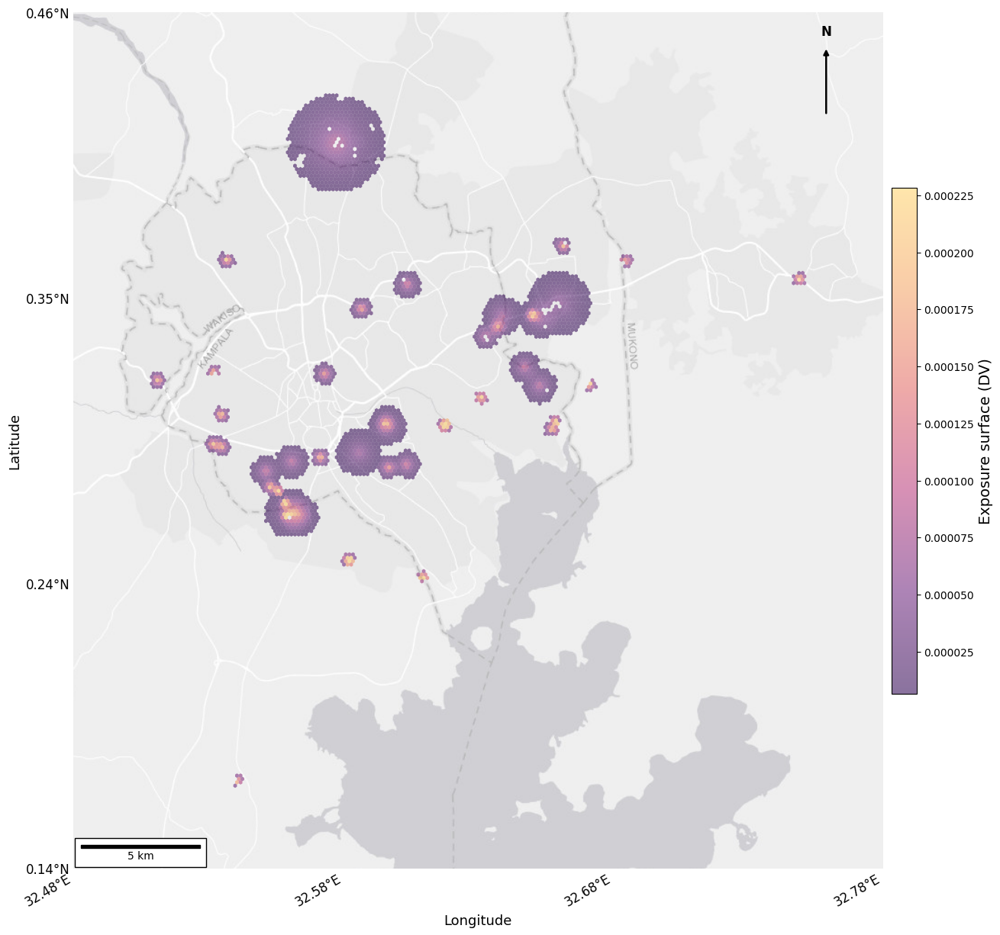

Grid points plotted  : 30,199
99th percentile DV   : 0.000228
Output figure        :
/content/drive/MyDrive/Paper_3/Processing/DV/Revised/Kampala/Kampala_Exposure_Surface_2016_revised.png

BOTH SURFACES COMPLETE
2024: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Kampala/Kampala_Exposure_Surface_2024_revised.png
2016: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Kampala/Kampala_Exposure_Surface_2016_revised.png


In [ ]:
# =============================================================================
# EXPOSURE SURFACE VISUALIZATION (REVISED DV) — BOTH YEARS
# Independent per-year colour scaling (each year clipped at its own q99)
# =============================================================================

import os
import math
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.font_manager as fm
import contextily as ctx
from pyproj import CRS, Transformer
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

warnings.filterwarnings("ignore")

# =============================================================================
# CONFIG
# =============================================================================
CITY = "Kampala"
YEARS = [2024, 2016]

# Per-city extent padding overrides (default 0.12/0.12 if not listed here).
# Dakar: deliberately elongated vertical pad (0.22) for its peninsula geography.
PAD_OVERRIDES = {
    "Dakar": {"padx_factor": 0.12, "pady_factor": 0.22},
}
padx_factor, pady_factor = PAD_OVERRIDES.get(CITY, {"padx_factor": 0.12, "pady_factor": 0.12}).values()

IN_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
OUT_DIR = IN_DIR
os.makedirs(OUT_DIR, exist_ok=True)

FIGSIZE = (13, 13)
DPI = 300

# =============================================================================
# COLOURMAP
# =============================================================================
exposure_cmap = mcolors.LinearSegmentedColormap.from_list(
    "Exposure",
    ["#2b004f", "#6a1f7a", "#b63679", "#e16462", "#f4a261", "#ffd166"],
    N=256
)

# =============================================================================
# CRS HELPERS
# =============================================================================
CRS_WEB = CRS.from_epsg(3857)
CRS_WGS = CRS.from_epsg(4326)

def utm_epsg(lon, lat):
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"

# =============================================================================
# NORTH ARROW
# =============================================================================
def add_north_arrow(ax):
    ax.annotate("", xy=(0.93, 0.96), xytext=(0.93, 0.88), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"))
    ax.text(0.93, 0.97, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=12, fontweight="bold")

# =============================================================================
# SCALE BAR
# =============================================================================
def add_scalebar(ax):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(ax.transData, 5000, "5 km", "lower left", pad=0.6,
                                color="black", frameon=True, size_vertical=150,
                                fontproperties=fontprops)
    ax.add_artist(scalebar)

# =============================================================================
# LAT/LON TICKS
# =============================================================================
def format_lon(x):
    return f"{abs(x):.2f}°{'E' if x >= 0 else 'W'}"

def format_lat(y):
    return f"{abs(y):.2f}°{'N' if y >= 0 else 'S'}"

def add_latlon_ticks(ax):
    transformer = Transformer.from_crs(CRS_WEB, CRS_WGS, always_xy=True)
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    xticks = np.linspace(xmin, xmax, 4)
    yticks = np.linspace(ymin, ymax, 4)
    yc = (ymin + ymax) / 2
    xc = (xmin + xmax) / 2
    lons = [transformer.transform(x, yc)[0] for x in xticks]
    lats = [transformer.transform(xc, y)[1] for y in yticks]
    ax.set_xticks(xticks)
    ax.set_xticklabels([format_lon(i) for i in lons], fontsize=12, rotation=30, ha="right")
    ax.set_yticks(yticks)
    ax.set_yticklabels([format_lat(i) for i in lats], fontsize=12)
    ax.set_xlabel("Longitude", fontsize=13)
    ax.set_ylabel("Latitude", fontsize=13)

# =============================================================================
# PLOT ONE YEAR
# =============================================================================
def plot_year(city, year, in_dir, out_dir, padx_f, pady_f):
    csv = os.path.join(in_dir, f"{city.lower()}_grid30m_DV_{year}_revised.csv")
    out_fig = os.path.join(out_dir, f"{city}_Exposure_Surface_{year}_revised.png")

    print("=" * 70)
    print(f"{city} {year}")
    print("=" * 70)
    print(f"Source: {csv}")

    df = pd.read_csv(csv)
    required = ["longitude", "latitude", "DV_log1p"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")

    epsg = utm_epsg(df.longitude.mean(), df.latitude.mean())
    print("UTM:", epsg)

    gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude),
                            crs="EPSG:4326").to_crs(epsg)
    gdf["DV_raw"] = np.expm1(gdf["DV_log1p"])
    gdf = gdf.to_crs(3857)

    nz = gdf[gdf["DV_raw"] > 0].copy()
    q99 = nz["DV_raw"].quantile(0.99)   # independent per-year scale
    nz["DV_plot"] = nz["DV_raw"].clip(upper=q99)
    if len(nz) > 120000:
        nz = nz.sample(120000, random_state=42)

    xmin, ymin, xmax, ymax = nz.total_bounds
    padx = (xmax - xmin) * padx_f
    pady = (ymax - ymin) * pady_f

    fig, ax = plt.subplots(figsize=FIGSIZE)
    ax.set_xlim(xmin - padx, xmax + padx)
    ax.set_ylim(ymin - pady, ymax + pady)
    ax.set_aspect("equal", adjustable="box")

    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas, attribution=False, zorder=0)

    hb = ax.hexbin(nz.geometry.x.values, nz.geometry.y.values, C=nz["DV_plot"].values,
                    reduce_C_function=np.mean, gridsize=180, mincnt=1, linewidths=0,
                    alpha=0.55, cmap=exposure_cmap, zorder=5)

    cbar = fig.colorbar(hb, ax=ax, fraction=0.03, pad=0.01)
    cbar.set_label("Exposure surface (DV)", fontsize=14)

    add_north_arrow(ax)
    add_scalebar(ax)
    add_latlon_ticks(ax)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="both", length=0)

    plt.tight_layout()
    plt.savefig(out_fig, dpi=DPI, bbox_inches="tight", facecolor="white")
    plt.show()

    print(f"Grid points plotted  : {len(nz):,}")
    print(f"99th percentile DV   : {q99:.6f}")
    print(f"Output figure        :\n{out_fig}\n")

    return out_fig

# =============================================================================
# RUN BOTH YEARS
# =============================================================================
outputs = {}
for year in YEARS:
    outputs[year] = plot_year(CITY, year, IN_DIR, OUT_DIR, padx_factor, pady_factor)

print("=" * 70)
print("BOTH SURFACES COMPLETE")
print("=" * 70)
for year, path in outputs.items():
    print(f"{year}: {path}")

Kinshasa

In [ ]:
# =============================================================================
# REVISED DIFFERENTIAL-SPREAD DV GENERATION (Kinshasa 2024)
# 500m² FLOOR + SIZE-SCALED RADIUS (200m-2km) + STEEPENED DECAY (H_HALF=0.30)
# COMBINED — CONFIG, KMZ LOADING, KD-TREE, DV COMPUTATION & SAVE
# =============================================================================

import os
import zipfile
import tempfile
import warnings
import time
import fiona
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

# --- CONFIGURATION ------------------------------------------------------

CITY = "Kinshasa"
YEAR = 2024

EPSG = 32733   # confirmed
BETA = 0.59    # confirmed

KMZ_FILE  = f"/content/drive/MyDrive/Paper_3/Sites/{YEAR}/{CITY}/{CITY}_{YEAR}.kmz"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"

OUT_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
os.makedirs(OUT_DIR, exist_ok=True)
OUTPUT_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_{YEAR}_revised.csv")

# 2024 reads the original master grid
GRID_CSV = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets/{CITY.lower()}_grid30m_master_merged_withDV.csv"

# --- LOCKED DESIGN PARAMETERS (same for all cities/years) -------------------

MIN_AREA_M2    = 500.0
MIN_RADIUS_M   = 200.0
MAX_RADIUS_M   = 2000.0
CAP_PERCENTILE = 99
H_HALF         = 0.30
TAU            = 1.0

# --- CITY-SPECIFIC AREA CAP (pooled 2016+2024, from site CSVs) --------------

print("=" * 70)
print(f"Computing area cap for {CITY} (pooled 2016+2024)...")
print("=" * 70)

areas_pooled = []
for y in [2016, 2024]:
    sites_csv = pd.read_csv(f"{SITES_DIR}/{y}/{CITY}/{CITY}_{y}_sites.csv")
    sites_csv = sites_csv.dropna(subset=["area"])
    sites_csv = sites_csv[sites_csv["area"] >= MIN_AREA_M2]
    areas_pooled.extend(sites_csv["area"].values)

AREA_CAP_M2 = np.percentile(areas_pooled, CAP_PERCENTILE)
print(f"{CITY}: n={len(areas_pooled):,} qualifying sites (both years), "
      f"p{CAP_PERCENTILE} area cap = {AREA_CAP_M2:,.1f} m² ({AREA_CAP_M2/10000:.2f} ha)")

# --- LOAD & PROJECT KMZ (target year's own site geometries) -----------------

print("\n" + "=" * 70)
print("Loading KMZ...")
print("=" * 70)

tmpdir = tempfile.mkdtemp()
with zipfile.ZipFile(KMZ_FILE, "r") as z:
    z.extractall(tmpdir)

kml_files = [
    os.path.join(root, f)
    for root, _, files in os.walk(tmpdir)
    for f in files if f.lower().endswith(".kml")
]
if not kml_files:
    raise RuntimeError("No KML file found inside KMZ.")

kml_file = kml_files[0]
print(f"KML found: {kml_file}")

fiona.drvsupport.supported_drivers["KML"] = "rw"
sites = gpd.read_file(kml_file, driver="KML").set_geometry("geometry")

if sites.crs is None:
    sites = sites.set_crs(4326)
sites = sites.to_crs(EPSG)
print(f"Loaded {len(sites)} geometries, projected to EPSG:{EPSG}")

# --- EXPLODE, FILTER TO POLYGONS, COMPUTE AREA -------------------------

sites = sites.explode(index_parts=False).reset_index(drop=True)
sites = sites[sites.geometry.type.isin(["Polygon", "MultiPolygon"])].copy()
print(f"Polygon features: {len(sites)}")
if len(sites) == 0:
    raise RuntimeError("No polygons found.")

sites["area_m2"] = sites.geometry.area
sites = sites[np.isfinite(sites["area_m2"]) & (sites["area_m2"] > 0)].copy()
print(f"Valid polygons: {len(sites)}")

# --- 500 m² FLOOR -------------------------------------------------------

n_before_floor = len(sites)
sites = sites[sites["area_m2"] >= MIN_AREA_M2].copy()
print(f"Sites >= {MIN_AREA_M2:.0f} m²: {len(sites)} (dropped {n_before_floor - len(sites)} smaller sites)")
if len(sites) == 0:
    raise RuntimeError(f"No sites >= {MIN_AREA_M2:.0f} m² for {CITY} {YEAR}.")

# --- CENTROIDS -----------------------------------------------------------

sites["centroid"] = sites.geometry.centroid
site_pts = sites.set_geometry("centroid").copy()

site_xy = np.column_stack((site_pts.geometry.x.values, site_pts.geometry.y.values))
areas = site_pts["area_m2"].to_numpy(dtype=float)

# --- SIZE-SCALED RADII (200m-2km, city-specific p99 cap) -------------------

print("\nComputing size-scaled radii...")

capped_area = np.minimum(areas, AREA_CAP_M2)
score = (np.log(capped_area) - np.log(MIN_AREA_M2)) / (np.log(AREA_CAP_M2) - np.log(MIN_AREA_M2))
r_j = MIN_RADIUS_M + (MAX_RADIUS_M - MIN_RADIUS_M) * score

lambda_j = np.log(2.0) / (H_HALF * r_j)
K_j = (lambda_j ** 2) / (2.0 * np.pi)
mass_j = np.power(np.maximum(areas, 1.0), BETA)

# --- KD-TREE ---------------------------------------------------------------

tree = cKDTree(site_xy)
R_QUERY = TAU * np.max(r_j)
print("\nKD Tree constructed.")

# --- LOAD GRID COORDINATES --------------------------------------------------

print("\nLoading grid coordinates...")
print(f"Grid source: {GRID_CSV}")

grid = pd.read_csv(GRID_CSV, usecols=["grid_point", "longitude", "latitude"]).dropna()
print(f"Grid points: {len(grid):,}")

grid_gdf = gpd.GeoDataFrame(
    grid,
    geometry=gpd.points_from_xy(grid.longitude, grid.latitude),
    crs=4326
).to_crs(EPSG)

points_xy = np.column_stack((grid_gdf.geometry.x.values, grid_gdf.geometry.y.values))

# --- SETUP DIAGNOSTICS -------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY (site/grid setup)")
print("=" * 70)
print(f"City / year                : {CITY} {YEAR}")
print(f"EPSG / BETA (per-city)     : {EPSG} / {BETA}")
print(f"Min area / min radius      : {MIN_AREA_M2:.0f} m² / {MIN_RADIUS_M:.0f} m")
print(f"Area cap (p{CAP_PERCENTILE}) / max radius : {AREA_CAP_M2:,.1f} m² / {MAX_RADIUS_M:.0f} m")
print(f"H_HALF / TAU                : {H_HALF} / {TAU}")
print(f"Sites retained (>= floor)   : {len(site_pts):,}")
print(f"Grid points                 : {len(points_xy):,}")
print(f"Mean site area (m²)         : {areas.mean():.2f}")
print(f"Median site area (m²)       : {np.median(areas):.2f}")
print("\nSize-scaled radius summary (m)")
print(pd.Series(r_j).describe())
print(f"\nMaximum search radius: {R_QUERY:.2f} m")

# =============================================================================
# DV COMPUTATION — every 30 m grid point + save
# =============================================================================

print("\n" + "=" * 70)
print("Computing DV at 30 m grid points...")
print("=" * 70)

t0 = time.time()

N = len(points_xy)
DV_pts = np.zeros(N, dtype=np.float64)
overlap_pts = np.zeros(N, dtype=np.int16)

BATCH_SIZE = 5000
print(f"Grid points : {N:,}")
print(f"Batch size  : {BATCH_SIZE:,}")
print(f"Total batches: {int(np.ceil(N / BATCH_SIZE))}")

for start in range(0, N, BATCH_SIZE):
    end = min(start + BATCH_SIZE, N)
    batch_points = points_xy[start:end]

    neighbour_lists = tree.query_ball_point(batch_points, r=R_QUERY)

    for i, neighbours in enumerate(neighbour_lists):
        if len(neighbours) == 0:
            continue

        pt = batch_points[i]
        cand_xy = site_xy[neighbours]

        dx = cand_xy[:, 0] - pt[0]
        dy = cand_xy[:, 1] - pt[1]
        d = np.sqrt(dx * dx + dy * dy)

        r_local = r_j[neighbours]
        keep = d <= (TAU * r_local)
        if not np.any(keep):
            continue

        d = d[keep]
        lam = lambda_j[neighbours][keep]
        K = K_j[neighbours][keep]
        mass = mass_j[neighbours][keep]

        contrib = mass * K * np.exp(-lam * d)
        DV_pts[start + i] = contrib.sum()
        overlap_pts[start + i] = keep.sum()

    processed = end
    pct = processed / N * 100
    elapsed = time.time() - t0
    rate = processed / elapsed
    remaining = (N - processed) / rate if rate > 0 else np.nan
    print(f"{processed:>8,} / {N:,} ({pct:5.1f}%)   Elapsed: {elapsed:6.1f}s   ETA: {remaining:6.1f}s")

print("\nFinished DV computation.")

DV_log = np.log1p(DV_pts)

print(f"Non-zero grid points : {(DV_pts>0).sum():,}")
print(f"Maximum overlap      : {overlap_pts.max()}")
print(f"Maximum DV           : {DV_pts.max():.6f}")
print(f"Mean DV              : {DV_pts.mean():.6f}")
print(f"Median DV            : {np.median(DV_pts):.6f}")

# --- BUILD & SAVE OUTPUT ------------------------------------------------------

print("\n" + "=" * 70)
print("Saving output...")
print("=" * 70)

out_df = pd.DataFrame({
    "grid_point": grid["grid_point"].values,
    "longitude": grid["longitude"].values,
    "latitude": grid["latitude"].values,
    "DV_hex_diffspread": DV_pts,
    "DV_log1p": DV_log,
    "n_sites": overlap_pts
}).sort_values("grid_point").reset_index(drop=True)

os.makedirs(OUT_DIR, exist_ok=True)
out_df.to_csv(OUTPUT_CSV, index=False)

runtime = time.time() - t0
pct_list = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

print("\n" + "=" * 70)
print("OUTPUT SUMMARY")
print("=" * 70)
print(f"Output file:\n{OUTPUT_CSV}\n")
print(f"Rows written                : {len(out_df):,}")
print(f"Non-zero DV                 : {(out_df.DV_hex_diffspread>0).sum():,}")
print(f"Zero DV                     : {(out_df.DV_hex_diffspread==0).sum():,}")
print(f"Maximum contributing sites  : {out_df.n_sites.max()}")
print(f"Mean contributing sites     : {out_df.n_sites[out_df.n_sites>0].mean():.2f}")

print("\nDV summary")
print(out_df["DV_hex_diffspread"].describe(percentiles=pct_list))

print("\nDV_log1p summary")
print(out_df["DV_log1p"].describe(percentiles=pct_list))

print(f"\nProcessing time : {runtime:.1f} seconds")
print("\n✓ Revised DV successfully generated.")
print(f"\nSaved to:\n{OUTPUT_CSV}")

Computing area cap for Kinshasa (pooled 2016+2024)...
Kinshasa: n=164 qualifying sites (both years), p99 area cap = 5,221.3 m² (0.52 ha)

Loading KMZ...
KML found: /tmp/tmpu9vownr9/doc.kml
Loaded 938 geometries, projected to EPSG:32733
Polygon features: 938
Valid polygons: 938
Sites >= 500 m²: 88 (dropped 850 smaller sites)

Computing size-scaled radii...

KD Tree constructed.

Loading grid coordinates...
Grid source: /content/drive/MyDrive/Results_2/Data_2024/Processed/Kinshasa/Final_datasets/kinshasa_grid30m_master_merged_withDV.csv
Grid points: 293,871

SUMMARY (site/grid setup)
City / year                : Kinshasa 2024
EPSG / BETA (per-city)     : 32733 / 0.59
Min area / min radius      : 500 m² / 200 m
Area cap (p99) / max radius : 5,221.3 m² / 2000 m
H_HALF / TAU                : 0.3 / 1.0
Sites retained (>= floor)   : 88
Grid points                 : 293,871
Mean site area (m²)         : 1334.29
Median site area (m²)       : 852.63

Size-scaled radius summary (m)
count      88.

In [ ]:
# =============================================================================
# REVISED DIFFERENTIAL-SPREAD DV GENERATION (Kinshasa 2016)
# 500m² FLOOR + SIZE-SCALED RADIUS (200m-2km) + STEEPENED DECAY (H_HALF=0.30)
# COMBINED — CONFIG, KMZ LOADING, KD-TREE, DV COMPUTATION & SAVE
# =============================================================================

import os
import zipfile
import tempfile
import warnings
import time
import fiona
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

# --- CONFIGURATION ------------------------------------------------------

CITY = "Kinshasa"
YEAR = 2016

EPSG = 32733   # confirmed, matches Kinshasa 2024
BETA = 0.59    # confirmed, matches Kinshasa 2024

KMZ_FILE  = f"/content/drive/MyDrive/Paper_3/Sites/{YEAR}/{CITY}/{CITY}_{YEAR}.kmz"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"

OUT_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
os.makedirs(OUT_DIR, exist_ok=True)
OUTPUT_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_{YEAR}_revised.csv")

# 2016 reuses 2024's own REVISED output as the grid source (same grid_point set)
GRID_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_2024_revised.csv")
if not os.path.exists(GRID_CSV):
    raise RuntimeError(
        f"2024 revised output not found for {CITY} — run YEAR=2024 first, "
        f"since 2016 reuses its grid for cross-year consistency."
    )

# --- LOCKED DESIGN PARAMETERS (same for all cities/years) -------------------

MIN_AREA_M2    = 500.0
MIN_RADIUS_M   = 200.0
MAX_RADIUS_M   = 2000.0
CAP_PERCENTILE = 99
H_HALF         = 0.30
TAU            = 1.0

# --- CITY-SPECIFIC AREA CAP (pooled 2016+2024, from site CSVs) --------------

print("=" * 70)
print(f"Computing area cap for {CITY} (pooled 2016+2024)...")
print("=" * 70)

areas_pooled = []
for y in [2016, 2024]:
    sites_csv = pd.read_csv(f"{SITES_DIR}/{y}/{CITY}/{CITY}_{y}_sites.csv")
    sites_csv = sites_csv.dropna(subset=["area"])
    sites_csv = sites_csv[sites_csv["area"] >= MIN_AREA_M2]
    areas_pooled.extend(sites_csv["area"].values)

AREA_CAP_M2 = np.percentile(areas_pooled, CAP_PERCENTILE)
print(f"{CITY}: n={len(areas_pooled):,} qualifying sites (both years), "
      f"p{CAP_PERCENTILE} area cap = {AREA_CAP_M2:,.1f} m² ({AREA_CAP_M2/10000:.2f} ha)")

# --- LOAD & PROJECT KMZ (target year's own site geometries) -----------------

print("\n" + "=" * 70)
print("Loading KMZ...")
print("=" * 70)

tmpdir = tempfile.mkdtemp()
with zipfile.ZipFile(KMZ_FILE, "r") as z:
    z.extractall(tmpdir)

kml_files = [
    os.path.join(root, f)
    for root, _, files in os.walk(tmpdir)
    for f in files if f.lower().endswith(".kml")
]
if not kml_files:
    raise RuntimeError("No KML file found inside KMZ.")

kml_file = kml_files[0]
print(f"KML found: {kml_file}")

fiona.drvsupport.supported_drivers["KML"] = "rw"
sites = gpd.read_file(kml_file, driver="KML").set_geometry("geometry")

if sites.crs is None:
    sites = sites.set_crs(4326)
sites = sites.to_crs(EPSG)
print(f"Loaded {len(sites)} geometries, projected to EPSG:{EPSG}")

# --- EXPLODE, FILTER TO POLYGONS, COMPUTE AREA -------------------------

sites = sites.explode(index_parts=False).reset_index(drop=True)
sites = sites[sites.geometry.type.isin(["Polygon", "MultiPolygon"])].copy()
print(f"Polygon features: {len(sites)}")
if len(sites) == 0:
    raise RuntimeError("No polygons found.")

sites["area_m2"] = sites.geometry.area
sites = sites[np.isfinite(sites["area_m2"]) & (sites["area_m2"] > 0)].copy()
print(f"Valid polygons: {len(sites)}")

# --- 500 m² FLOOR -------------------------------------------------------

n_before_floor = len(sites)
sites = sites[sites["area_m2"] >= MIN_AREA_M2].copy()
print(f"Sites >= {MIN_AREA_M2:.0f} m²: {len(sites)} (dropped {n_before_floor - len(sites)} smaller sites)")
if len(sites) == 0:
    raise RuntimeError(f"No sites >= {MIN_AREA_M2:.0f} m² for {CITY} {YEAR}.")

# --- CENTROIDS -----------------------------------------------------------

sites["centroid"] = sites.geometry.centroid
site_pts = sites.set_geometry("centroid").copy()

site_xy = np.column_stack((site_pts.geometry.x.values, site_pts.geometry.y.values))
areas = site_pts["area_m2"].to_numpy(dtype=float)

# --- SIZE-SCALED RADII (200m-2km, city-specific p99 cap) -------------------

print("\nComputing size-scaled radii...")

capped_area = np.minimum(areas, AREA_CAP_M2)
score = (np.log(capped_area) - np.log(MIN_AREA_M2)) / (np.log(AREA_CAP_M2) - np.log(MIN_AREA_M2))
r_j = MIN_RADIUS_M + (MAX_RADIUS_M - MIN_RADIUS_M) * score

lambda_j = np.log(2.0) / (H_HALF * r_j)
K_j = (lambda_j ** 2) / (2.0 * np.pi)
mass_j = np.power(np.maximum(areas, 1.0), BETA)

# --- KD-TREE ---------------------------------------------------------------

tree = cKDTree(site_xy)
R_QUERY = TAU * np.max(r_j)
print("\nKD Tree constructed.")

# --- LOAD GRID COORDINATES --------------------------------------------------

print("\nLoading grid coordinates...")
print(f"Grid source: {GRID_CSV}")

grid = pd.read_csv(GRID_CSV, usecols=["grid_point", "longitude", "latitude"]).dropna()
print(f"Grid points: {len(grid):,}")

grid_gdf = gpd.GeoDataFrame(
    grid,
    geometry=gpd.points_from_xy(grid.longitude, grid.latitude),
    crs=4326
).to_crs(EPSG)

points_xy = np.column_stack((grid_gdf.geometry.x.values, grid_gdf.geometry.y.values))

# --- SETUP DIAGNOSTICS -------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY (site/grid setup)")
print("=" * 70)
print(f"City / year                : {CITY} {YEAR}")
print(f"EPSG / BETA (per-city)     : {EPSG} / {BETA}")
print(f"Min area / min radius      : {MIN_AREA_M2:.0f} m² / {MIN_RADIUS_M:.0f} m")
print(f"Area cap (p{CAP_PERCENTILE}) / max radius : {AREA_CAP_M2:,.1f} m² / {MAX_RADIUS_M:.0f} m")
print(f"H_HALF / TAU                : {H_HALF} / {TAU}")
print(f"Sites retained (>= floor)   : {len(site_pts):,}")
print(f"Grid points                 : {len(points_xy):,}")
print(f"Mean site area (m²)         : {areas.mean():.2f}")
print(f"Median site area (m²)       : {np.median(areas):.2f}")
print("\nSize-scaled radius summary (m)")
print(pd.Series(r_j).describe())
print(f"\nMaximum search radius: {R_QUERY:.2f} m")

# =============================================================================
# DV COMPUTATION — every 30 m grid point + save
# =============================================================================

print("\n" + "=" * 70)
print("Computing DV at 30 m grid points...")
print("=" * 70)

t0 = time.time()

N = len(points_xy)
DV_pts = np.zeros(N, dtype=np.float64)
overlap_pts = np.zeros(N, dtype=np.int16)

BATCH_SIZE = 5000
print(f"Grid points : {N:,}")
print(f"Batch size  : {BATCH_SIZE:,}")
print(f"Total batches: {int(np.ceil(N / BATCH_SIZE))}")

for start in range(0, N, BATCH_SIZE):
    end = min(start + BATCH_SIZE, N)
    batch_points = points_xy[start:end]

    neighbour_lists = tree.query_ball_point(batch_points, r=R_QUERY)

    for i, neighbours in enumerate(neighbour_lists):
        if len(neighbours) == 0:
            continue

        pt = batch_points[i]
        cand_xy = site_xy[neighbours]

        dx = cand_xy[:, 0] - pt[0]
        dy = cand_xy[:, 1] - pt[1]
        d = np.sqrt(dx * dx + dy * dy)

        r_local = r_j[neighbours]
        keep = d <= (TAU * r_local)
        if not np.any(keep):
            continue

        d = d[keep]
        lam = lambda_j[neighbours][keep]
        K = K_j[neighbours][keep]
        mass = mass_j[neighbours][keep]

        contrib = mass * K * np.exp(-lam * d)
        DV_pts[start + i] = contrib.sum()
        overlap_pts[start + i] = keep.sum()

    processed = end
    pct = processed / N * 100
    elapsed = time.time() - t0
    rate = processed / elapsed
    remaining = (N - processed) / rate if rate > 0 else np.nan
    print(f"{processed:>8,} / {N:,} ({pct:5.1f}%)   Elapsed: {elapsed:6.1f}s   ETA: {remaining:6.1f}s")

print("\nFinished DV computation.")

DV_log = np.log1p(DV_pts)

print(f"Non-zero grid points : {(DV_pts>0).sum():,}")
print(f"Maximum overlap      : {overlap_pts.max()}")
print(f"Maximum DV           : {DV_pts.max():.6f}")
print(f"Mean DV              : {DV_pts.mean():.6f}")
print(f"Median DV            : {np.median(DV_pts):.6f}")

# --- BUILD & SAVE OUTPUT ------------------------------------------------------

print("\n" + "=" * 70)
print("Saving output...")
print("=" * 70)

out_df = pd.DataFrame({
    "grid_point": grid["grid_point"].values,
    "longitude": grid["longitude"].values,
    "latitude": grid["latitude"].values,
    "DV_hex_diffspread": DV_pts,
    "DV_log1p": DV_log,
    "n_sites": overlap_pts
}).sort_values("grid_point").reset_index(drop=True)

os.makedirs(OUT_DIR, exist_ok=True)
out_df.to_csv(OUTPUT_CSV, index=False)

runtime = time.time() - t0
pct_list = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

print("\n" + "=" * 70)
print("OUTPUT SUMMARY")
print("=" * 70)
print(f"Output file:\n{OUTPUT_CSV}\n")
print(f"Rows written                : {len(out_df):,}")
print(f"Non-zero DV                 : {(out_df.DV_hex_diffspread>0).sum():,}")
print(f"Zero DV                     : {(out_df.DV_hex_diffspread==0).sum():,}")
print(f"Maximum contributing sites  : {out_df.n_sites.max()}")
print(f"Mean contributing sites     : {out_df.n_sites[out_df.n_sites>0].mean():.2f}")

print("\nDV summary")
print(out_df["DV_hex_diffspread"].describe(percentiles=pct_list))

print("\nDV_log1p summary")
print(out_df["DV_log1p"].describe(percentiles=pct_list))

print(f"\nProcessing time : {runtime:.1f} seconds")
print("\n✓ Revised DV successfully generated.")
print(f"\nSaved to:\n{OUTPUT_CSV}")

Computing area cap for Kinshasa (pooled 2016+2024)...
Kinshasa: n=164 qualifying sites (both years), p99 area cap = 5,221.3 m² (0.52 ha)

Loading KMZ...
KML found: /tmp/tmpv5rkht6u/doc.kml
Loaded 767 geometries, projected to EPSG:32733
Polygon features: 767
Valid polygons: 767
Sites >= 500 m²: 76 (dropped 691 smaller sites)

Computing size-scaled radii...

KD Tree constructed.

Loading grid coordinates...
Grid source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Kinshasa/kinshasa_grid30m_DV_2024_revised.csv
Grid points: 293,871

SUMMARY (site/grid setup)
City / year                : Kinshasa 2016
EPSG / BETA (per-city)     : 32733 / 0.59
Min area / min radius      : 500 m² / 200 m
Area cap (p99) / max radius : 5,221.3 m² / 2000 m
H_HALF / TAU                : 0.3 / 1.0
Sites retained (>= floor)   : 76
Grid points                 : 293,871
Mean site area (m²)         : 1017.48
Median site area (m²)       : 787.33

Size-scaled radius summary (m)
count      76.000000
mean      652

Kinshasa 2024
Source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Kinshasa/kinshasa_grid30m_DV_2024_revised.csv
UTM: EPSG:32733


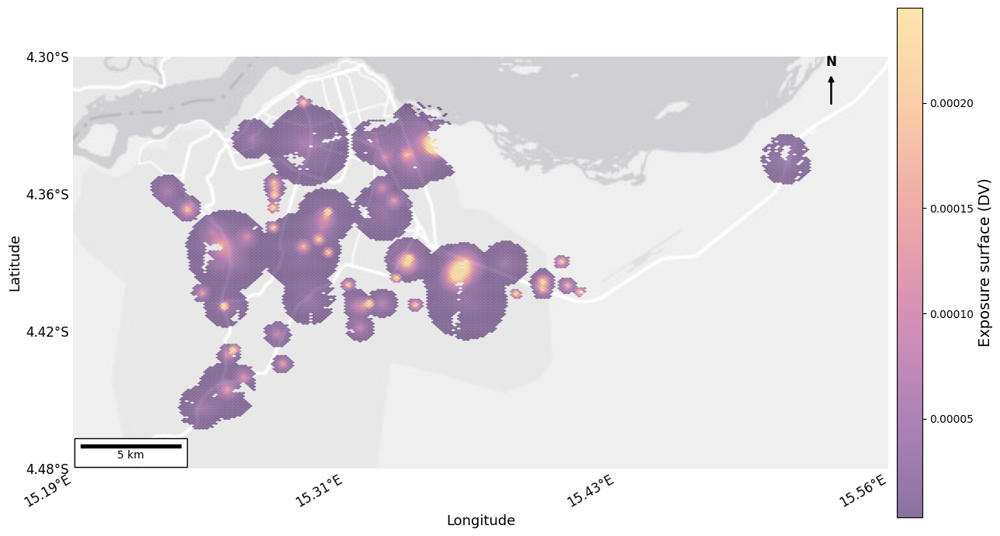

Grid points plotted  : 105,631
99th percentile DV   : 0.000245
Output figure        :
/content/drive/MyDrive/Paper_3/Processing/DV/Revised/Kinshasa/Kinshasa_Exposure_Surface_2024_revised.png

Kinshasa 2016
Source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Kinshasa/kinshasa_grid30m_DV_2016_revised.csv
UTM: EPSG:32733


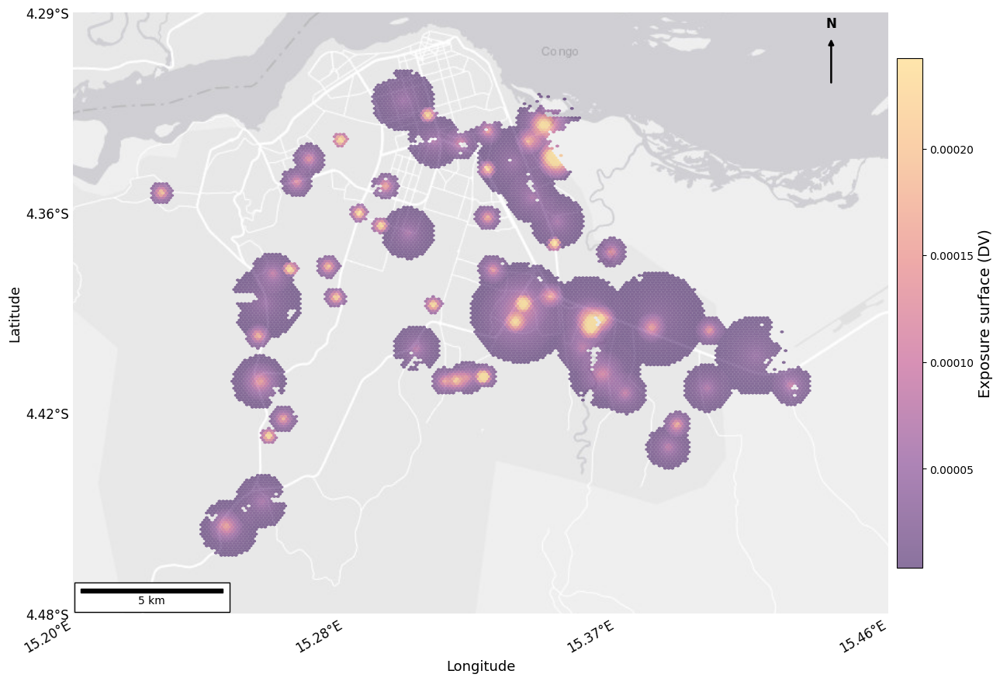

Grid points plotted  : 75,535
99th percentile DV   : 0.000242
Output figure        :
/content/drive/MyDrive/Paper_3/Processing/DV/Revised/Kinshasa/Kinshasa_Exposure_Surface_2016_revised.png

BOTH SURFACES COMPLETE
2024: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Kinshasa/Kinshasa_Exposure_Surface_2024_revised.png
2016: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Kinshasa/Kinshasa_Exposure_Surface_2016_revised.png


In [ ]:
# =============================================================================
# EXPOSURE SURFACE VISUALIZATION (REVISED DV) — BOTH YEARS
# Independent per-year colour scaling (each year clipped at its own q99)
# =============================================================================

import os
import math
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.font_manager as fm
import contextily as ctx
from pyproj import CRS, Transformer
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

warnings.filterwarnings("ignore")

# =============================================================================
# CONFIG
# =============================================================================
CITY = "Kinshasa"
YEARS = [2024, 2016]

# Per-city extent padding overrides (default 0.12/0.12 if not listed here).
# Dakar: deliberately elongated vertical pad (0.22) for its peninsula geography.
PAD_OVERRIDES = {
    "Dakar": {"padx_factor": 0.12, "pady_factor": 0.22},
}
padx_factor, pady_factor = PAD_OVERRIDES.get(CITY, {"padx_factor": 0.12, "pady_factor": 0.12}).values()

IN_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
OUT_DIR = IN_DIR
os.makedirs(OUT_DIR, exist_ok=True)

FIGSIZE = (13, 13)
DPI = 300

# =============================================================================
# COLOURMAP
# =============================================================================
exposure_cmap = mcolors.LinearSegmentedColormap.from_list(
    "Exposure",
    ["#2b004f", "#6a1f7a", "#b63679", "#e16462", "#f4a261", "#ffd166"],
    N=256
)

# =============================================================================
# CRS HELPERS
# =============================================================================
CRS_WEB = CRS.from_epsg(3857)
CRS_WGS = CRS.from_epsg(4326)

def utm_epsg(lon, lat):
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"

# =============================================================================
# NORTH ARROW
# =============================================================================
def add_north_arrow(ax):
    ax.annotate("", xy=(0.93, 0.96), xytext=(0.93, 0.88), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"))
    ax.text(0.93, 0.97, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=12, fontweight="bold")

# =============================================================================
# SCALE BAR
# =============================================================================
def add_scalebar(ax):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(ax.transData, 5000, "5 km", "lower left", pad=0.6,
                                color="black", frameon=True, size_vertical=150,
                                fontproperties=fontprops)
    ax.add_artist(scalebar)

# =============================================================================
# LAT/LON TICKS
# =============================================================================
def format_lon(x):
    return f"{abs(x):.2f}°{'E' if x >= 0 else 'W'}"

def format_lat(y):
    return f"{abs(y):.2f}°{'N' if y >= 0 else 'S'}"

def add_latlon_ticks(ax):
    transformer = Transformer.from_crs(CRS_WEB, CRS_WGS, always_xy=True)
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    xticks = np.linspace(xmin, xmax, 4)
    yticks = np.linspace(ymin, ymax, 4)
    yc = (ymin + ymax) / 2
    xc = (xmin + xmax) / 2
    lons = [transformer.transform(x, yc)[0] for x in xticks]
    lats = [transformer.transform(xc, y)[1] for y in yticks]
    ax.set_xticks(xticks)
    ax.set_xticklabels([format_lon(i) for i in lons], fontsize=12, rotation=30, ha="right")
    ax.set_yticks(yticks)
    ax.set_yticklabels([format_lat(i) for i in lats], fontsize=12)
    ax.set_xlabel("Longitude", fontsize=13)
    ax.set_ylabel("Latitude", fontsize=13)

# =============================================================================
# PLOT ONE YEAR
# =============================================================================
def plot_year(city, year, in_dir, out_dir, padx_f, pady_f):
    csv = os.path.join(in_dir, f"{city.lower()}_grid30m_DV_{year}_revised.csv")
    out_fig = os.path.join(out_dir, f"{city}_Exposure_Surface_{year}_revised.png")

    print("=" * 70)
    print(f"{city} {year}")
    print("=" * 70)
    print(f"Source: {csv}")

    df = pd.read_csv(csv)
    required = ["longitude", "latitude", "DV_log1p"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")

    epsg = utm_epsg(df.longitude.mean(), df.latitude.mean())
    print("UTM:", epsg)

    gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude),
                            crs="EPSG:4326").to_crs(epsg)
    gdf["DV_raw"] = np.expm1(gdf["DV_log1p"])
    gdf = gdf.to_crs(3857)

    nz = gdf[gdf["DV_raw"] > 0].copy()
    q99 = nz["DV_raw"].quantile(0.99)   # independent per-year scale
    nz["DV_plot"] = nz["DV_raw"].clip(upper=q99)
    if len(nz) > 120000:
        nz = nz.sample(120000, random_state=42)

    xmin, ymin, xmax, ymax = nz.total_bounds
    padx = (xmax - xmin) * padx_f
    pady = (ymax - ymin) * pady_f

    fig, ax = plt.subplots(figsize=FIGSIZE)
    ax.set_xlim(xmin - padx, xmax + padx)
    ax.set_ylim(ymin - pady, ymax + pady)
    ax.set_aspect("equal", adjustable="box")

    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas, attribution=False, zorder=0)

    hb = ax.hexbin(nz.geometry.x.values, nz.geometry.y.values, C=nz["DV_plot"].values,
                    reduce_C_function=np.mean, gridsize=180, mincnt=1, linewidths=0,
                    alpha=0.55, cmap=exposure_cmap, zorder=5)

    cbar = fig.colorbar(hb, ax=ax, fraction=0.03, pad=0.01)
    cbar.set_label("Exposure surface (DV)", fontsize=14)

    add_north_arrow(ax)
    add_scalebar(ax)
    add_latlon_ticks(ax)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="both", length=0)

    plt.tight_layout()
    plt.savefig(out_fig, dpi=DPI, bbox_inches="tight", facecolor="white")
    plt.show()

    print(f"Grid points plotted  : {len(nz):,}")
    print(f"99th percentile DV   : {q99:.6f}")
    print(f"Output figure        :\n{out_fig}\n")

    return out_fig

# =============================================================================
# RUN BOTH YEARS
# =============================================================================
outputs = {}
for year in YEARS:
    outputs[year] = plot_year(CITY, year, IN_DIR, OUT_DIR, padx_factor, pady_factor)

print("=" * 70)
print("BOTH SURFACES COMPLETE")
print("=" * 70)
for year, path in outputs.items():
    print(f"{year}: {path}")

Lagos

In [ ]:
# =============================================================================
# REVISED DIFFERENTIAL-SPREAD DV GENERATION (Lagos 2024)
# 500m² FLOOR + SIZE-SCALED RADIUS (200m-2km) + STEEPENED DECAY (H_HALF=0.30)
# COMBINED — CONFIG, KMZ LOADING, KD-TREE, DV COMPUTATION & SAVE
# =============================================================================

import os
import zipfile
import tempfile
import warnings
import time
import fiona
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

# --- CONFIGURATION ------------------------------------------------------

CITY = "Lagos"
YEAR = 2024

EPSG = 32631   # confirmed
BETA = 0.40    # confirmed

KMZ_FILE  = f"/content/drive/MyDrive/Paper_3/Sites/{YEAR}/{CITY}/{CITY}_{YEAR}.kmz"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"

OUT_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
os.makedirs(OUT_DIR, exist_ok=True)
OUTPUT_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_{YEAR}_revised.csv")

# 2024 reads the original master grid
GRID_CSV = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets/{CITY.lower()}_grid30m_master_merged_withDV.csv"

# --- LOCKED DESIGN PARAMETERS (same for all cities/years) -------------------

MIN_AREA_M2    = 500.0
MIN_RADIUS_M   = 200.0
MAX_RADIUS_M   = 2000.0
CAP_PERCENTILE = 99
H_HALF         = 0.30
TAU            = 1.0

# --- CITY-SPECIFIC AREA CAP (pooled 2016+2024, from site CSVs) --------------

print("=" * 70)
print(f"Computing area cap for {CITY} (pooled 2016+2024)...")
print("=" * 70)

areas_pooled = []
for y in [2016, 2024]:
    sites_csv = pd.read_csv(f"{SITES_DIR}/{y}/{CITY}/{CITY}_{y}_sites.csv")
    sites_csv = sites_csv.dropna(subset=["area"])
    sites_csv = sites_csv[sites_csv["area"] >= MIN_AREA_M2]
    areas_pooled.extend(sites_csv["area"].values)

AREA_CAP_M2 = np.percentile(areas_pooled, CAP_PERCENTILE)
print(f"{CITY}: n={len(areas_pooled):,} qualifying sites (both years), "
      f"p{CAP_PERCENTILE} area cap = {AREA_CAP_M2:,.1f} m² ({AREA_CAP_M2/10000:.2f} ha)")

# --- LOAD & PROJECT KMZ (target year's own site geometries) -----------------

print("\n" + "=" * 70)
print("Loading KMZ...")
print("=" * 70)

tmpdir = tempfile.mkdtemp()
with zipfile.ZipFile(KMZ_FILE, "r") as z:
    z.extractall(tmpdir)

kml_files = [
    os.path.join(root, f)
    for root, _, files in os.walk(tmpdir)
    for f in files if f.lower().endswith(".kml")
]
if not kml_files:
    raise RuntimeError("No KML file found inside KMZ.")

kml_file = kml_files[0]
print(f"KML found: {kml_file}")

fiona.drvsupport.supported_drivers["KML"] = "rw"
sites = gpd.read_file(kml_file, driver="KML").set_geometry("geometry")

if sites.crs is None:
    sites = sites.set_crs(4326)
sites = sites.to_crs(EPSG)
print(f"Loaded {len(sites)} geometries, projected to EPSG:{EPSG}")

# --- EXPLODE, FILTER TO POLYGONS, COMPUTE AREA -------------------------

sites = sites.explode(index_parts=False).reset_index(drop=True)
sites = sites[sites.geometry.type.isin(["Polygon", "MultiPolygon"])].copy()
print(f"Polygon features: {len(sites)}")
if len(sites) == 0:
    raise RuntimeError("No polygons found.")

sites["area_m2"] = sites.geometry.area
sites = sites[np.isfinite(sites["area_m2"]) & (sites["area_m2"] > 0)].copy()
print(f"Valid polygons: {len(sites)}")

# --- 500 m² FLOOR -------------------------------------------------------

n_before_floor = len(sites)
sites = sites[sites["area_m2"] >= MIN_AREA_M2].copy()
print(f"Sites >= {MIN_AREA_M2:.0f} m²: {len(sites)} (dropped {n_before_floor - len(sites)} smaller sites)")
if len(sites) == 0:
    raise RuntimeError(f"No sites >= {MIN_AREA_M2:.0f} m² for {CITY} {YEAR}.")

# --- CENTROIDS -----------------------------------------------------------

sites["centroid"] = sites.geometry.centroid
site_pts = sites.set_geometry("centroid").copy()

site_xy = np.column_stack((site_pts.geometry.x.values, site_pts.geometry.y.values))
areas = site_pts["area_m2"].to_numpy(dtype=float)

# --- SIZE-SCALED RADII (200m-2km, city-specific p99 cap) -------------------

print("\nComputing size-scaled radii...")

capped_area = np.minimum(areas, AREA_CAP_M2)
score = (np.log(capped_area) - np.log(MIN_AREA_M2)) / (np.log(AREA_CAP_M2) - np.log(MIN_AREA_M2))
r_j = MIN_RADIUS_M + (MAX_RADIUS_M - MIN_RADIUS_M) * score

lambda_j = np.log(2.0) / (H_HALF * r_j)
K_j = (lambda_j ** 2) / (2.0 * np.pi)
mass_j = np.power(np.maximum(areas, 1.0), BETA)

# --- KD-TREE ---------------------------------------------------------------

tree = cKDTree(site_xy)
R_QUERY = TAU * np.max(r_j)
print("\nKD Tree constructed.")

# --- LOAD GRID COORDINATES --------------------------------------------------

print("\nLoading grid coordinates...")
print(f"Grid source: {GRID_CSV}")

# NOTE: Lagos's master grid CSV uses "grid_point_id" instead of "grid_point"
# (every other city's master grid used "grid_point" directly) — renamed here
# so the rest of the pipeline stays consistent.
grid = pd.read_csv(GRID_CSV, usecols=["grid_point_id", "longitude", "latitude"]).dropna()
grid = grid.rename(columns={"grid_point_id": "grid_point"})
print(f"Grid points: {len(grid):,}")

grid_gdf = gpd.GeoDataFrame(
    grid,
    geometry=gpd.points_from_xy(grid.longitude, grid.latitude),
    crs=4326
).to_crs(EPSG)

points_xy = np.column_stack((grid_gdf.geometry.x.values, grid_gdf.geometry.y.values))

# --- SETUP DIAGNOSTICS -------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY (site/grid setup)")
print("=" * 70)
print(f"City / year                : {CITY} {YEAR}")
print(f"EPSG / BETA (per-city)     : {EPSG} / {BETA}")
print(f"Min area / min radius      : {MIN_AREA_M2:.0f} m² / {MIN_RADIUS_M:.0f} m")
print(f"Area cap (p{CAP_PERCENTILE}) / max radius : {AREA_CAP_M2:,.1f} m² / {MAX_RADIUS_M:.0f} m")
print(f"H_HALF / TAU                : {H_HALF} / {TAU}")
print(f"Sites retained (>= floor)   : {len(site_pts):,}")
print(f"Grid points                 : {len(points_xy):,}")
print(f"Mean site area (m²)         : {areas.mean():.2f}")
print(f"Median site area (m²)       : {np.median(areas):.2f}")
print("\nSize-scaled radius summary (m)")
print(pd.Series(r_j).describe())
print(f"\nMaximum search radius: {R_QUERY:.2f} m")

# =============================================================================
# DV COMPUTATION — every 30 m grid point + save
# =============================================================================

print("\n" + "=" * 70)
print("Computing DV at 30 m grid points...")
print("=" * 70)

t0 = time.time()

N = len(points_xy)
DV_pts = np.zeros(N, dtype=np.float64)
overlap_pts = np.zeros(N, dtype=np.int16)

BATCH_SIZE = 5000
print(f"Grid points : {N:,}")
print(f"Batch size  : {BATCH_SIZE:,}")
print(f"Total batches: {int(np.ceil(N / BATCH_SIZE))}")

for start in range(0, N, BATCH_SIZE):
    end = min(start + BATCH_SIZE, N)
    batch_points = points_xy[start:end]

    neighbour_lists = tree.query_ball_point(batch_points, r=R_QUERY)

    for i, neighbours in enumerate(neighbour_lists):
        if len(neighbours) == 0:
            continue

        pt = batch_points[i]
        cand_xy = site_xy[neighbours]

        dx = cand_xy[:, 0] - pt[0]
        dy = cand_xy[:, 1] - pt[1]
        d = np.sqrt(dx * dx + dy * dy)

        r_local = r_j[neighbours]
        keep = d <= (TAU * r_local)
        if not np.any(keep):
            continue

        d = d[keep]
        lam = lambda_j[neighbours][keep]
        K = K_j[neighbours][keep]
        mass = mass_j[neighbours][keep]

        contrib = mass * K * np.exp(-lam * d)
        DV_pts[start + i] = contrib.sum()
        overlap_pts[start + i] = keep.sum()

    processed = end
    pct = processed / N * 100
    elapsed = time.time() - t0
    rate = processed / elapsed
    remaining = (N - processed) / rate if rate > 0 else np.nan
    print(f"{processed:>8,} / {N:,} ({pct:5.1f}%)   Elapsed: {elapsed:6.1f}s   ETA: {remaining:6.1f}s")

print("\nFinished DV computation.")

DV_log = np.log1p(DV_pts)

print(f"Non-zero grid points : {(DV_pts>0).sum():,}")
print(f"Maximum overlap      : {overlap_pts.max()}")
print(f"Maximum DV           : {DV_pts.max():.6f}")
print(f"Mean DV              : {DV_pts.mean():.6f}")
print(f"Median DV            : {np.median(DV_pts):.6f}")

# --- BUILD & SAVE OUTPUT ------------------------------------------------------

print("\n" + "=" * 70)
print("Saving output...")
print("=" * 70)

out_df = pd.DataFrame({
    "grid_point": grid["grid_point"].values,
    "longitude": grid["longitude"].values,
    "latitude": grid["latitude"].values,
    "DV_hex_diffspread": DV_pts,
    "DV_log1p": DV_log,
    "n_sites": overlap_pts
}).sort_values("grid_point").reset_index(drop=True)

os.makedirs(OUT_DIR, exist_ok=True)
out_df.to_csv(OUTPUT_CSV, index=False)

runtime = time.time() - t0
pct_list = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

print("\n" + "=" * 70)
print("OUTPUT SUMMARY")
print("=" * 70)
print(f"Output file:\n{OUTPUT_CSV}\n")
print(f"Rows written                : {len(out_df):,}")
print(f"Non-zero DV                 : {(out_df.DV_hex_diffspread>0).sum():,}")
print(f"Zero DV                     : {(out_df.DV_hex_diffspread==0).sum():,}")
print(f"Maximum contributing sites  : {out_df.n_sites.max()}")
print(f"Mean contributing sites     : {out_df.n_sites[out_df.n_sites>0].mean():.2f}")

print("\nDV summary")
print(out_df["DV_hex_diffspread"].describe(percentiles=pct_list))

print("\nDV_log1p summary")
print(out_df["DV_log1p"].describe(percentiles=pct_list))

print(f"\nProcessing time : {runtime:.1f} seconds")
print("\n✓ Revised DV successfully generated.")
print(f"\nSaved to:\n{OUTPUT_CSV}")

Computing area cap for Lagos (pooled 2016+2024)...
Lagos: n=800 qualifying sites (both years), p99 area cap = 29,579.4 m² (2.96 ha)

Loading KMZ...
KML found: /tmp/tmp6bcutick/doc.kml
Loaded 1241 geometries, projected to EPSG:32631
Polygon features: 1241
Valid polygons: 1241
Sites >= 500 m²: 472 (dropped 769 smaller sites)

Computing size-scaled radii...

KD Tree constructed.

Loading grid coordinates...
Grid source: /content/drive/MyDrive/Results_2/Data_2024/Processed/Lagos/Final_datasets/lagos_grid30m_master_merged_withDV.csv
Grid points: 1,243,725

SUMMARY (site/grid setup)
City / year                : Lagos 2024
EPSG / BETA (per-city)     : 32631 / 0.4
Min area / min radius      : 500 m² / 200 m
Area cap (p99) / max radius : 29,579.4 m² / 2000 m
H_HALF / TAU                : 0.3 / 1.0
Sites retained (>= floor)   : 472
Grid points                 : 1,243,725
Mean site area (m²)         : 4208.84
Median site area (m²)       : 1283.98

Size-scaled radius summary (m)
count     472.0000

In [ ]:
# =============================================================================
# REVISED DIFFERENTIAL-SPREAD DV GENERATION (Lagos 2016)
# 500m² FLOOR + SIZE-SCALED RADIUS (200m-2km) + STEEPENED DECAY (H_HALF=0.30)
# COMBINED — CONFIG, KMZ LOADING, KD-TREE, DV COMPUTATION & SAVE
# =============================================================================

import os
import zipfile
import tempfile
import warnings
import time
import fiona
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

# --- CONFIGURATION ------------------------------------------------------

CITY = "Lagos"
YEAR = 2016

EPSG = 32631   # confirmed, matches Lagos 2024
BETA = 0.40    # confirmed, matches Lagos 2024

KMZ_FILE  = f"/content/drive/MyDrive/Paper_3/Sites/{YEAR}/{CITY}/{CITY}_{YEAR}.kmz"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"

OUT_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
os.makedirs(OUT_DIR, exist_ok=True)
OUTPUT_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_{YEAR}_revised.csv")

# 2016 reuses 2024's own REVISED output as the grid source (same grid_point set).
# Lagos's 2024 revised output already has the normalized "grid_point" column
# (renamed from the master grid's "grid_point_id" during 2024's own run),
# so no rename is needed here.
GRID_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_2024_revised.csv")
if not os.path.exists(GRID_CSV):
    raise RuntimeError(
        f"2024 revised output not found for {CITY} — run YEAR=2024 first, "
        f"since 2016 reuses its grid for cross-year consistency."
    )

# --- LOCKED DESIGN PARAMETERS (same for all cities/years) -------------------

MIN_AREA_M2    = 500.0
MIN_RADIUS_M   = 200.0
MAX_RADIUS_M   = 2000.0
CAP_PERCENTILE = 99
H_HALF         = 0.30
TAU            = 1.0

# --- CITY-SPECIFIC AREA CAP (pooled 2016+2024, from site CSVs) --------------

print("=" * 70)
print(f"Computing area cap for {CITY} (pooled 2016+2024)...")
print("=" * 70)

areas_pooled = []
for y in [2016, 2024]:
    sites_csv = pd.read_csv(f"{SITES_DIR}/{y}/{CITY}/{CITY}_{y}_sites.csv")
    sites_csv = sites_csv.dropna(subset=["area"])
    sites_csv = sites_csv[sites_csv["area"] >= MIN_AREA_M2]
    areas_pooled.extend(sites_csv["area"].values)

AREA_CAP_M2 = np.percentile(areas_pooled, CAP_PERCENTILE)
print(f"{CITY}: n={len(areas_pooled):,} qualifying sites (both years), "
      f"p{CAP_PERCENTILE} area cap = {AREA_CAP_M2:,.1f} m² ({AREA_CAP_M2/10000:.2f} ha)")

# --- LOAD & PROJECT KMZ (target year's own site geometries) -----------------

print("\n" + "=" * 70)
print("Loading KMZ...")
print("=" * 70)

tmpdir = tempfile.mkdtemp()
with zipfile.ZipFile(KMZ_FILE, "r") as z:
    z.extractall(tmpdir)

kml_files = [
    os.path.join(root, f)
    for root, _, files in os.walk(tmpdir)
    for f in files if f.lower().endswith(".kml")
]
if not kml_files:
    raise RuntimeError("No KML file found inside KMZ.")

kml_file = kml_files[0]
print(f"KML found: {kml_file}")

fiona.drvsupport.supported_drivers["KML"] = "rw"
sites = gpd.read_file(kml_file, driver="KML").set_geometry("geometry")

if sites.crs is None:
    sites = sites.set_crs(4326)
sites = sites.to_crs(EPSG)
print(f"Loaded {len(sites)} geometries, projected to EPSG:{EPSG}")

# --- EXPLODE, FILTER TO POLYGONS, COMPUTE AREA -------------------------

sites = sites.explode(index_parts=False).reset_index(drop=True)
sites = sites[sites.geometry.type.isin(["Polygon", "MultiPolygon"])].copy()
print(f"Polygon features: {len(sites)}")
if len(sites) == 0:
    raise RuntimeError("No polygons found.")

sites["area_m2"] = sites.geometry.area
sites = sites[np.isfinite(sites["area_m2"]) & (sites["area_m2"] > 0)].copy()
print(f"Valid polygons: {len(sites)}")

# --- 500 m² FLOOR -------------------------------------------------------

n_before_floor = len(sites)
sites = sites[sites["area_m2"] >= MIN_AREA_M2].copy()
print(f"Sites >= {MIN_AREA_M2:.0f} m²: {len(sites)} (dropped {n_before_floor - len(sites)} smaller sites)")
if len(sites) == 0:
    raise RuntimeError(f"No sites >= {MIN_AREA_M2:.0f} m² for {CITY} {YEAR}.")

# --- CENTROIDS -----------------------------------------------------------

sites["centroid"] = sites.geometry.centroid
site_pts = sites.set_geometry("centroid").copy()

site_xy = np.column_stack((site_pts.geometry.x.values, site_pts.geometry.y.values))
areas = site_pts["area_m2"].to_numpy(dtype=float)

# --- SIZE-SCALED RADII (200m-2km, city-specific p99 cap) -------------------

print("\nComputing size-scaled radii...")

capped_area = np.minimum(areas, AREA_CAP_M2)
score = (np.log(capped_area) - np.log(MIN_AREA_M2)) / (np.log(AREA_CAP_M2) - np.log(MIN_AREA_M2))
r_j = MIN_RADIUS_M + (MAX_RADIUS_M - MIN_RADIUS_M) * score

lambda_j = np.log(2.0) / (H_HALF * r_j)
K_j = (lambda_j ** 2) / (2.0 * np.pi)
mass_j = np.power(np.maximum(areas, 1.0), BETA)

# --- KD-TREE ---------------------------------------------------------------

tree = cKDTree(site_xy)
R_QUERY = TAU * np.max(r_j)
print("\nKD Tree constructed.")

# --- LOAD GRID COORDINATES --------------------------------------------------

print("\nLoading grid coordinates...")
print(f"Grid source: {GRID_CSV}")

grid = pd.read_csv(GRID_CSV, usecols=["grid_point", "longitude", "latitude"]).dropna()
print(f"Grid points: {len(grid):,}")

grid_gdf = gpd.GeoDataFrame(
    grid,
    geometry=gpd.points_from_xy(grid.longitude, grid.latitude),
    crs=4326
).to_crs(EPSG)

points_xy = np.column_stack((grid_gdf.geometry.x.values, grid_gdf.geometry.y.values))

# --- SETUP DIAGNOSTICS -------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY (site/grid setup)")
print("=" * 70)
print(f"City / year                : {CITY} {YEAR}")
print(f"EPSG / BETA (per-city)     : {EPSG} / {BETA}")
print(f"Min area / min radius      : {MIN_AREA_M2:.0f} m² / {MIN_RADIUS_M:.0f} m")
print(f"Area cap (p{CAP_PERCENTILE}) / max radius : {AREA_CAP_M2:,.1f} m² / {MAX_RADIUS_M:.0f} m")
print(f"H_HALF / TAU                : {H_HALF} / {TAU}")
print(f"Sites retained (>= floor)   : {len(site_pts):,}")
print(f"Grid points                 : {len(points_xy):,}")
print(f"Mean site area (m²)         : {areas.mean():.2f}")
print(f"Median site area (m²)       : {np.median(areas):.2f}")
print("\nSize-scaled radius summary (m)")
print(pd.Series(r_j).describe())
print(f"\nMaximum search radius: {R_QUERY:.2f} m")

# =============================================================================
# DV COMPUTATION — every 30 m grid point + save
# =============================================================================

print("\n" + "=" * 70)
print("Computing DV at 30 m grid points...")
print("=" * 70)

t0 = time.time()

N = len(points_xy)
DV_pts = np.zeros(N, dtype=np.float64)
overlap_pts = np.zeros(N, dtype=np.int16)

BATCH_SIZE = 5000
print(f"Grid points : {N:,}")
print(f"Batch size  : {BATCH_SIZE:,}")
print(f"Total batches: {int(np.ceil(N / BATCH_SIZE))}")

for start in range(0, N, BATCH_SIZE):
    end = min(start + BATCH_SIZE, N)
    batch_points = points_xy[start:end]

    neighbour_lists = tree.query_ball_point(batch_points, r=R_QUERY)

    for i, neighbours in enumerate(neighbour_lists):
        if len(neighbours) == 0:
            continue

        pt = batch_points[i]
        cand_xy = site_xy[neighbours]

        dx = cand_xy[:, 0] - pt[0]
        dy = cand_xy[:, 1] - pt[1]
        d = np.sqrt(dx * dx + dy * dy)

        r_local = r_j[neighbours]
        keep = d <= (TAU * r_local)
        if not np.any(keep):
            continue

        d = d[keep]
        lam = lambda_j[neighbours][keep]
        K = K_j[neighbours][keep]
        mass = mass_j[neighbours][keep]

        contrib = mass * K * np.exp(-lam * d)
        DV_pts[start + i] = contrib.sum()
        overlap_pts[start + i] = keep.sum()

    processed = end
    pct = processed / N * 100
    elapsed = time.time() - t0
    rate = processed / elapsed
    remaining = (N - processed) / rate if rate > 0 else np.nan
    print(f"{processed:>8,} / {N:,} ({pct:5.1f}%)   Elapsed: {elapsed:6.1f}s   ETA: {remaining:6.1f}s")

print("\nFinished DV computation.")

DV_log = np.log1p(DV_pts)

print(f"Non-zero grid points : {(DV_pts>0).sum():,}")
print(f"Maximum overlap      : {overlap_pts.max()}")
print(f"Maximum DV           : {DV_pts.max():.6f}")
print(f"Mean DV              : {DV_pts.mean():.6f}")
print(f"Median DV            : {np.median(DV_pts):.6f}")

# --- BUILD & SAVE OUTPUT ------------------------------------------------------

print("\n" + "=" * 70)
print("Saving output...")
print("=" * 70)

out_df = pd.DataFrame({
    "grid_point": grid["grid_point"].values,
    "longitude": grid["longitude"].values,
    "latitude": grid["latitude"].values,
    "DV_hex_diffspread": DV_pts,
    "DV_log1p": DV_log,
    "n_sites": overlap_pts
}).sort_values("grid_point").reset_index(drop=True)

os.makedirs(OUT_DIR, exist_ok=True)
out_df.to_csv(OUTPUT_CSV, index=False)

runtime = time.time() - t0
pct_list = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

print("\n" + "=" * 70)
print("OUTPUT SUMMARY")
print("=" * 70)
print(f"Output file:\n{OUTPUT_CSV}\n")
print(f"Rows written                : {len(out_df):,}")
print(f"Non-zero DV                 : {(out_df.DV_hex_diffspread>0).sum():,}")
print(f"Zero DV                     : {(out_df.DV_hex_diffspread==0).sum():,}")
print(f"Maximum contributing sites  : {out_df.n_sites.max()}")
print(f"Mean contributing sites     : {out_df.n_sites[out_df.n_sites>0].mean():.2f}")

print("\nDV summary")
print(out_df["DV_hex_diffspread"].describe(percentiles=pct_list))

print("\nDV_log1p summary")
print(out_df["DV_log1p"].describe(percentiles=pct_list))

print(f"\nProcessing time : {runtime:.1f} seconds")
print("\n✓ Revised DV successfully generated.")
print(f"\nSaved to:\n{OUTPUT_CSV}")

Computing area cap for Lagos (pooled 2016+2024)...
Lagos: n=800 qualifying sites (both years), p99 area cap = 29,579.4 m² (2.96 ha)

Loading KMZ...
KML found: /tmp/tmpsxpfm62x/doc.kml
Loaded 1505 geometries, projected to EPSG:32631
Polygon features: 1505
Valid polygons: 1505
Sites >= 500 m²: 328 (dropped 1177 smaller sites)

Computing size-scaled radii...

KD Tree constructed.

Loading grid coordinates...
Grid source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Lagos/lagos_grid30m_DV_2024_revised.csv
Grid points: 1,243,725

SUMMARY (site/grid setup)
City / year                : Lagos 2016
EPSG / BETA (per-city)     : 32631 / 0.4
Min area / min radius      : 500 m² / 200 m
Area cap (p99) / max radius : 29,579.4 m² / 2000 m
H_HALF / TAU                : 0.3 / 1.0
Sites retained (>= floor)   : 328
Grid points                 : 1,243,725
Mean site area (m²)         : 2933.96
Median site area (m²)       : 1054.70

Size-scaled radius summary (m)
count     328.000000
mean      636.30

Lagos 2024
Source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Lagos/lagos_grid30m_DV_2024_revised.csv
UTM: EPSG:32631


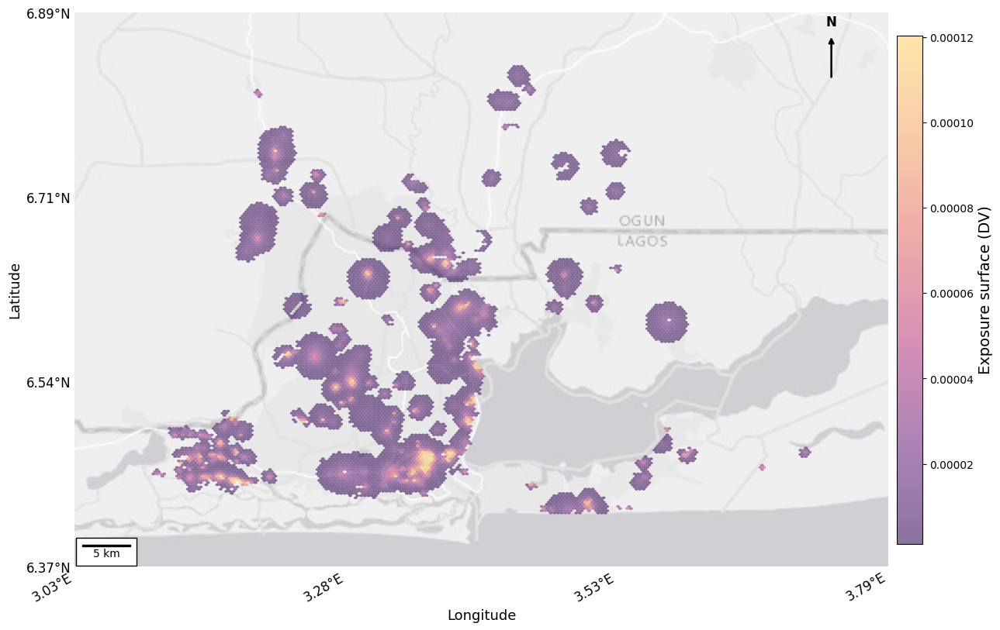

Grid points plotted  : 120,000
99th percentile DV   : 0.000120
Output figure        :
/content/drive/MyDrive/Paper_3/Processing/DV/Revised/Lagos/Lagos_Exposure_Surface_2024_revised.png

Lagos 2016
Source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Lagos/lagos_grid30m_DV_2016_revised.csv
UTM: EPSG:32631


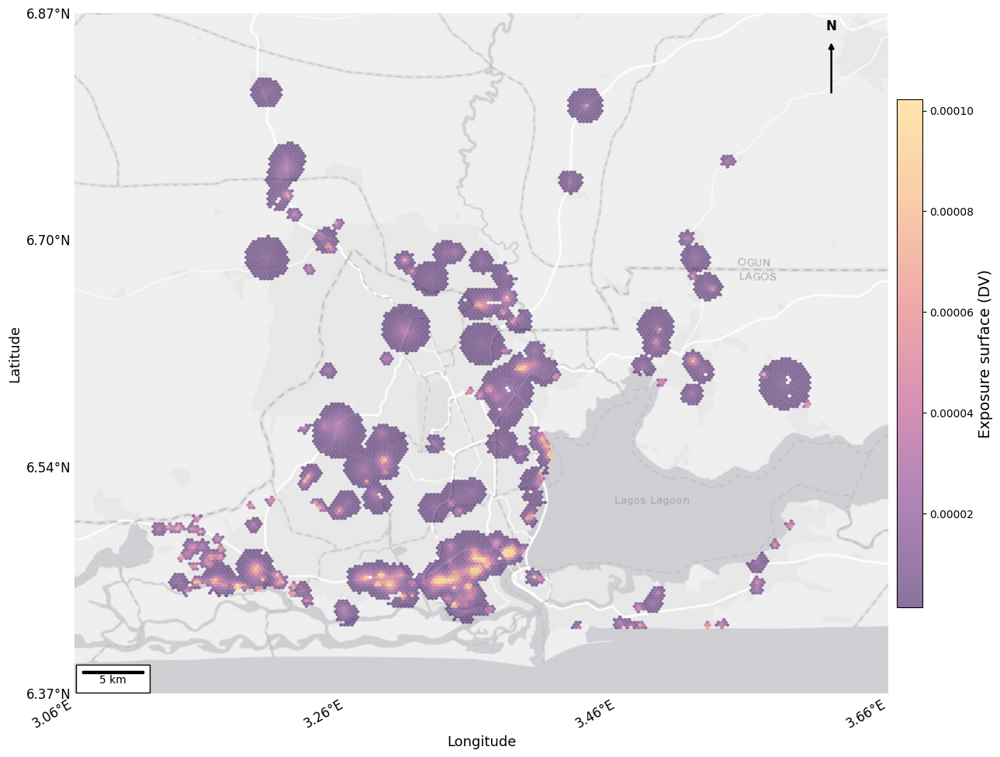

Grid points plotted  : 120,000
99th percentile DV   : 0.000102
Output figure        :
/content/drive/MyDrive/Paper_3/Processing/DV/Revised/Lagos/Lagos_Exposure_Surface_2016_revised.png

BOTH SURFACES COMPLETE
2024: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Lagos/Lagos_Exposure_Surface_2024_revised.png
2016: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Lagos/Lagos_Exposure_Surface_2016_revised.png


In [ ]:
# =============================================================================
# EXPOSURE SURFACE VISUALIZATION (REVISED DV) — BOTH YEARS
# Independent per-year colour scaling (each year clipped at its own q99)
# =============================================================================

import os
import math
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.font_manager as fm
import contextily as ctx
from pyproj import CRS, Transformer
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

warnings.filterwarnings("ignore")

# =============================================================================
# CONFIG
# =============================================================================
CITY = "Lagos"
YEARS = [2024, 2016]

# Per-city extent padding overrides (default 0.12/0.12 if not listed here).
# Dakar: deliberately elongated vertical pad (0.22) for its peninsula geography.
PAD_OVERRIDES = {
    "Dakar": {"padx_factor": 0.12, "pady_factor": 0.22},
}
padx_factor, pady_factor = PAD_OVERRIDES.get(CITY, {"padx_factor": 0.12, "pady_factor": 0.12}).values()

IN_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
OUT_DIR = IN_DIR
os.makedirs(OUT_DIR, exist_ok=True)

FIGSIZE = (13, 13)
DPI = 300

# =============================================================================
# COLOURMAP
# =============================================================================
exposure_cmap = mcolors.LinearSegmentedColormap.from_list(
    "Exposure",
    ["#2b004f", "#6a1f7a", "#b63679", "#e16462", "#f4a261", "#ffd166"],
    N=256
)

# =============================================================================
# CRS HELPERS
# =============================================================================
CRS_WEB = CRS.from_epsg(3857)
CRS_WGS = CRS.from_epsg(4326)

def utm_epsg(lon, lat):
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"

# =============================================================================
# NORTH ARROW
# =============================================================================
def add_north_arrow(ax):
    ax.annotate("", xy=(0.93, 0.96), xytext=(0.93, 0.88), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"))
    ax.text(0.93, 0.97, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=12, fontweight="bold")

# =============================================================================
# SCALE BAR
# =============================================================================
def add_scalebar(ax):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(ax.transData, 5000, "5 km", "lower left", pad=0.6,
                                color="black", frameon=True, size_vertical=150,
                                fontproperties=fontprops)
    ax.add_artist(scalebar)

# =============================================================================
# LAT/LON TICKS
# =============================================================================
def format_lon(x):
    return f"{abs(x):.2f}°{'E' if x >= 0 else 'W'}"

def format_lat(y):
    return f"{abs(y):.2f}°{'N' if y >= 0 else 'S'}"

def add_latlon_ticks(ax):
    transformer = Transformer.from_crs(CRS_WEB, CRS_WGS, always_xy=True)
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    xticks = np.linspace(xmin, xmax, 4)
    yticks = np.linspace(ymin, ymax, 4)
    yc = (ymin + ymax) / 2
    xc = (xmin + xmax) / 2
    lons = [transformer.transform(x, yc)[0] for x in xticks]
    lats = [transformer.transform(xc, y)[1] for y in yticks]
    ax.set_xticks(xticks)
    ax.set_xticklabels([format_lon(i) for i in lons], fontsize=12, rotation=30, ha="right")
    ax.set_yticks(yticks)
    ax.set_yticklabels([format_lat(i) for i in lats], fontsize=12)
    ax.set_xlabel("Longitude", fontsize=13)
    ax.set_ylabel("Latitude", fontsize=13)

# =============================================================================
# PLOT ONE YEAR
# =============================================================================
def plot_year(city, year, in_dir, out_dir, padx_f, pady_f):
    csv = os.path.join(in_dir, f"{city.lower()}_grid30m_DV_{year}_revised.csv")
    out_fig = os.path.join(out_dir, f"{city}_Exposure_Surface_{year}_revised.png")

    print("=" * 70)
    print(f"{city} {year}")
    print("=" * 70)
    print(f"Source: {csv}")

    df = pd.read_csv(csv)
    required = ["longitude", "latitude", "DV_log1p"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")

    epsg = utm_epsg(df.longitude.mean(), df.latitude.mean())
    print("UTM:", epsg)

    gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude),
                            crs="EPSG:4326").to_crs(epsg)
    gdf["DV_raw"] = np.expm1(gdf["DV_log1p"])
    gdf = gdf.to_crs(3857)

    nz = gdf[gdf["DV_raw"] > 0].copy()
    q99 = nz["DV_raw"].quantile(0.99)   # independent per-year scale
    nz["DV_plot"] = nz["DV_raw"].clip(upper=q99)
    if len(nz) > 120000:
        nz = nz.sample(120000, random_state=42)

    xmin, ymin, xmax, ymax = nz.total_bounds
    padx = (xmax - xmin) * padx_f
    pady = (ymax - ymin) * pady_f

    fig, ax = plt.subplots(figsize=FIGSIZE)
    ax.set_xlim(xmin - padx, xmax + padx)
    ax.set_ylim(ymin - pady, ymax + pady)
    ax.set_aspect("equal", adjustable="box")

    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas, attribution=False, zorder=0)

    hb = ax.hexbin(nz.geometry.x.values, nz.geometry.y.values, C=nz["DV_plot"].values,
                    reduce_C_function=np.mean, gridsize=180, mincnt=1, linewidths=0,
                    alpha=0.55, cmap=exposure_cmap, zorder=5)

    cbar = fig.colorbar(hb, ax=ax, fraction=0.03, pad=0.01)
    cbar.set_label("Exposure surface (DV)", fontsize=14)

    add_north_arrow(ax)
    add_scalebar(ax)
    add_latlon_ticks(ax)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="both", length=0)

    plt.tight_layout()
    plt.savefig(out_fig, dpi=DPI, bbox_inches="tight", facecolor="white")
    plt.show()

    print(f"Grid points plotted  : {len(nz):,}")
    print(f"99th percentile DV   : {q99:.6f}")
    print(f"Output figure        :\n{out_fig}\n")

    return out_fig

# =============================================================================
# RUN BOTH YEARS
# =============================================================================
outputs = {}
for year in YEARS:
    outputs[year] = plot_year(CITY, year, IN_DIR, OUT_DIR, padx_factor, pady_factor)

print("=" * 70)
print("BOTH SURFACES COMPLETE")
print("=" * 70)
for year, path in outputs.items():
    print(f"{year}: {path}")

Maputo

In [ ]:
# =============================================================================
# REVISED DIFFERENTIAL-SPREAD DV GENERATION (Maputo 2024)
# 500m² FLOOR + SIZE-SCALED RADIUS (200m-2km) + STEEPENED DECAY (H_HALF=0.30)
# COMBINED — CONFIG, KMZ LOADING, KD-TREE, DV COMPUTATION & SAVE
# =============================================================================

import os
import zipfile
import tempfile
import warnings
import time
import fiona
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

# --- CONFIGURATION ------------------------------------------------------

CITY = "Maputo"
YEAR = 2024

EPSG = 32736   # confirmed
BETA = 0.53    # confirmed

KMZ_FILE  = f"/content/drive/MyDrive/Paper_3/Sites/{YEAR}/{CITY}/{CITY}_{YEAR}.kmz"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"

OUT_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
os.makedirs(OUT_DIR, exist_ok=True)
OUTPUT_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_{YEAR}_revised.csv")

# 2024 reads the original master grid
GRID_CSV = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets/{CITY.lower()}_grid30m_master_merged_withDV.csv"

# --- LOCKED DESIGN PARAMETERS (same for all cities/years) -------------------

MIN_AREA_M2    = 500.0
MIN_RADIUS_M   = 200.0
MAX_RADIUS_M   = 2000.0
CAP_PERCENTILE = 99
H_HALF         = 0.30
TAU            = 1.0

# --- CITY-SPECIFIC AREA CAP (pooled 2016+2024, from site CSVs) --------------

print("=" * 70)
print(f"Computing area cap for {CITY} (pooled 2016+2024)...")
print("=" * 70)

areas_pooled = []
for y in [2016, 2024]:
    sites_csv = pd.read_csv(f"{SITES_DIR}/{y}/{CITY}/{CITY}_{y}_sites.csv")
    sites_csv = sites_csv.dropna(subset=["area"])
    sites_csv = sites_csv[sites_csv["area"] >= MIN_AREA_M2]
    areas_pooled.extend(sites_csv["area"].values)

AREA_CAP_M2 = np.percentile(areas_pooled, CAP_PERCENTILE)
print(f"{CITY}: n={len(areas_pooled):,} qualifying sites (both years), "
      f"p{CAP_PERCENTILE} area cap = {AREA_CAP_M2:,.1f} m² ({AREA_CAP_M2/10000:.2f} ha)")

# --- LOAD & PROJECT KMZ (target year's own site geometries) -----------------

print("\n" + "=" * 70)
print("Loading KMZ...")
print("=" * 70)

tmpdir = tempfile.mkdtemp()
with zipfile.ZipFile(KMZ_FILE, "r") as z:
    z.extractall(tmpdir)

kml_files = [
    os.path.join(root, f)
    for root, _, files in os.walk(tmpdir)
    for f in files if f.lower().endswith(".kml")
]
if not kml_files:
    raise RuntimeError("No KML file found inside KMZ.")

kml_file = kml_files[0]
print(f"KML found: {kml_file}")

fiona.drvsupport.supported_drivers["KML"] = "rw"
sites = gpd.read_file(kml_file, driver="KML").set_geometry("geometry")

if sites.crs is None:
    sites = sites.set_crs(4326)
sites = sites.to_crs(EPSG)
print(f"Loaded {len(sites)} geometries, projected to EPSG:{EPSG}")

# --- EXPLODE, FILTER TO POLYGONS, COMPUTE AREA -------------------------

sites = sites.explode(index_parts=False).reset_index(drop=True)
sites = sites[sites.geometry.type.isin(["Polygon", "MultiPolygon"])].copy()
print(f"Polygon features: {len(sites)}")
if len(sites) == 0:
    raise RuntimeError("No polygons found.")

sites["area_m2"] = sites.geometry.area
sites = sites[np.isfinite(sites["area_m2"]) & (sites["area_m2"] > 0)].copy()
print(f"Valid polygons: {len(sites)}")

# --- 500 m² FLOOR -------------------------------------------------------

n_before_floor = len(sites)
sites = sites[sites["area_m2"] >= MIN_AREA_M2].copy()
print(f"Sites >= {MIN_AREA_M2:.0f} m²: {len(sites)} (dropped {n_before_floor - len(sites)} smaller sites)")
if len(sites) == 0:
    raise RuntimeError(f"No sites >= {MIN_AREA_M2:.0f} m² for {CITY} {YEAR}.")

# --- CENTROIDS -----------------------------------------------------------

sites["centroid"] = sites.geometry.centroid
site_pts = sites.set_geometry("centroid").copy()

site_xy = np.column_stack((site_pts.geometry.x.values, site_pts.geometry.y.values))
areas = site_pts["area_m2"].to_numpy(dtype=float)

# --- SIZE-SCALED RADII (200m-2km, city-specific p99 cap) -------------------

print("\nComputing size-scaled radii...")

capped_area = np.minimum(areas, AREA_CAP_M2)
score = (np.log(capped_area) - np.log(MIN_AREA_M2)) / (np.log(AREA_CAP_M2) - np.log(MIN_AREA_M2))
r_j = MIN_RADIUS_M + (MAX_RADIUS_M - MIN_RADIUS_M) * score

lambda_j = np.log(2.0) / (H_HALF * r_j)
K_j = (lambda_j ** 2) / (2.0 * np.pi)
mass_j = np.power(np.maximum(areas, 1.0), BETA)

# --- KD-TREE ---------------------------------------------------------------

tree = cKDTree(site_xy)
R_QUERY = TAU * np.max(r_j)
print("\nKD Tree constructed.")

# --- LOAD GRID COORDINATES --------------------------------------------------

print("\nLoading grid coordinates...")
print(f"Grid source: {GRID_CSV}")

grid = pd.read_csv(GRID_CSV, usecols=["grid_point", "longitude", "latitude"]).dropna()
print(f"Grid points: {len(grid):,}")

grid_gdf = gpd.GeoDataFrame(
    grid,
    geometry=gpd.points_from_xy(grid.longitude, grid.latitude),
    crs=4326
).to_crs(EPSG)

points_xy = np.column_stack((grid_gdf.geometry.x.values, grid_gdf.geometry.y.values))

# --- SETUP DIAGNOSTICS -------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY (site/grid setup)")
print("=" * 70)
print(f"City / year                : {CITY} {YEAR}")
print(f"EPSG / BETA (per-city)     : {EPSG} / {BETA}")
print(f"Min area / min radius      : {MIN_AREA_M2:.0f} m² / {MIN_RADIUS_M:.0f} m")
print(f"Area cap (p{CAP_PERCENTILE}) / max radius : {AREA_CAP_M2:,.1f} m² / {MAX_RADIUS_M:.0f} m")
print(f"H_HALF / TAU                : {H_HALF} / {TAU}")
print(f"Sites retained (>= floor)   : {len(site_pts):,}")
print(f"Grid points                 : {len(points_xy):,}")
print(f"Mean site area (m²)         : {areas.mean():.2f}")
print(f"Median site area (m²)       : {np.median(areas):.2f}")
print("\nSize-scaled radius summary (m)")
print(pd.Series(r_j).describe())
print(f"\nMaximum search radius: {R_QUERY:.2f} m")

# =============================================================================
# DV COMPUTATION — every 30 m grid point + save
# =============================================================================

print("\n" + "=" * 70)
print("Computing DV at 30 m grid points...")
print("=" * 70)

t0 = time.time()

N = len(points_xy)
DV_pts = np.zeros(N, dtype=np.float64)
overlap_pts = np.zeros(N, dtype=np.int16)

BATCH_SIZE = 5000
print(f"Grid points : {N:,}")
print(f"Batch size  : {BATCH_SIZE:,}")
print(f"Total batches: {int(np.ceil(N / BATCH_SIZE))}")

for start in range(0, N, BATCH_SIZE):
    end = min(start + BATCH_SIZE, N)
    batch_points = points_xy[start:end]

    neighbour_lists = tree.query_ball_point(batch_points, r=R_QUERY)

    for i, neighbours in enumerate(neighbour_lists):
        if len(neighbours) == 0:
            continue

        pt = batch_points[i]
        cand_xy = site_xy[neighbours]

        dx = cand_xy[:, 0] - pt[0]
        dy = cand_xy[:, 1] - pt[1]
        d = np.sqrt(dx * dx + dy * dy)

        r_local = r_j[neighbours]
        keep = d <= (TAU * r_local)
        if not np.any(keep):
            continue

        d = d[keep]
        lam = lambda_j[neighbours][keep]
        K = K_j[neighbours][keep]
        mass = mass_j[neighbours][keep]

        contrib = mass * K * np.exp(-lam * d)
        DV_pts[start + i] = contrib.sum()
        overlap_pts[start + i] = keep.sum()

    processed = end
    pct = processed / N * 100
    elapsed = time.time() - t0
    rate = processed / elapsed
    remaining = (N - processed) / rate if rate > 0 else np.nan
    print(f"{processed:>8,} / {N:,} ({pct:5.1f}%)   Elapsed: {elapsed:6.1f}s   ETA: {remaining:6.1f}s")

print("\nFinished DV computation.")

DV_log = np.log1p(DV_pts)

print(f"Non-zero grid points : {(DV_pts>0).sum():,}")
print(f"Maximum overlap      : {overlap_pts.max()}")
print(f"Maximum DV           : {DV_pts.max():.6f}")
print(f"Mean DV              : {DV_pts.mean():.6f}")
print(f"Median DV            : {np.median(DV_pts):.6f}")

# --- BUILD & SAVE OUTPUT ------------------------------------------------------

print("\n" + "=" * 70)
print("Saving output...")
print("=" * 70)

out_df = pd.DataFrame({
    "grid_point": grid["grid_point"].values,
    "longitude": grid["longitude"].values,
    "latitude": grid["latitude"].values,
    "DV_hex_diffspread": DV_pts,
    "DV_log1p": DV_log,
    "n_sites": overlap_pts
}).sort_values("grid_point").reset_index(drop=True)

os.makedirs(OUT_DIR, exist_ok=True)
out_df.to_csv(OUTPUT_CSV, index=False)

runtime = time.time() - t0
pct_list = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

print("\n" + "=" * 70)
print("OUTPUT SUMMARY")
print("=" * 70)
print(f"Output file:\n{OUTPUT_CSV}\n")
print(f"Rows written                : {len(out_df):,}")
print(f"Non-zero DV                 : {(out_df.DV_hex_diffspread>0).sum():,}")
print(f"Zero DV                     : {(out_df.DV_hex_diffspread==0).sum():,}")
print(f"Maximum contributing sites  : {out_df.n_sites.max()}")
print(f"Mean contributing sites     : {out_df.n_sites[out_df.n_sites>0].mean():.2f}")

print("\nDV summary")
print(out_df["DV_hex_diffspread"].describe(percentiles=pct_list))

print("\nDV_log1p summary")
print(out_df["DV_log1p"].describe(percentiles=pct_list))

print(f"\nProcessing time : {runtime:.1f} seconds")
print("\n✓ Revised DV successfully generated.")
print(f"\nSaved to:\n{OUTPUT_CSV}")

Computing area cap for Maputo (pooled 2016+2024)...
Maputo: n=85 qualifying sites (both years), p99 area cap = 172,163.5 m² (17.22 ha)

Loading KMZ...
KML found: /tmp/tmp02ps03pa/doc.kml
Loaded 314 geometries, projected to EPSG:32736
Polygon features: 314
Valid polygons: 314
Sites >= 500 m²: 45 (dropped 269 smaller sites)

Computing size-scaled radii...

KD Tree constructed.

Loading grid coordinates...
Grid source: /content/drive/MyDrive/Results_2/Data_2024/Processed/Maputo/Final_datasets/maputo_grid30m_master_merged_withDV.csv
Grid points: 319,048

SUMMARY (site/grid setup)
City / year                : Maputo 2024
EPSG / BETA (per-city)     : 32736 / 0.53
Min area / min radius      : 500 m² / 200 m
Area cap (p99) / max radius : 172,163.5 m² / 2000 m
H_HALF / TAU                : 0.3 / 1.0
Sites retained (>= floor)   : 45
Grid points                 : 319,048
Mean site area (m²)         : 7566.93
Median site area (m²)       : 1003.99

Size-scaled radius summary (m)
count      45.00000

In [ ]:
# =============================================================================
# REVISED DIFFERENTIAL-SPREAD DV GENERATION (Maputo 2016)
# 500m² FLOOR + SIZE-SCALED RADIUS (200m-2km) + STEEPENED DECAY (H_HALF=0.30)
# COMBINED — CONFIG, KMZ LOADING, KD-TREE, DV COMPUTATION & SAVE
# =============================================================================

import os
import zipfile
import tempfile
import warnings
import time
import fiona
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

# --- CONFIGURATION ------------------------------------------------------

CITY = "Maputo"
YEAR = 2016

EPSG = 32736   # confirmed, matches Maputo 2024
BETA = 0.53    # confirmed, matches Maputo 2024

KMZ_FILE  = f"/content/drive/MyDrive/Paper_3/Sites/{YEAR}/{CITY}/{CITY}_{YEAR}.kmz"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"

OUT_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
os.makedirs(OUT_DIR, exist_ok=True)
OUTPUT_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_{YEAR}_revised.csv")

# 2016 reuses 2024's own REVISED output as the grid source (same grid_point set)
GRID_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_2024_revised.csv")
if not os.path.exists(GRID_CSV):
    raise RuntimeError(
        f"2024 revised output not found for {CITY} — run YEAR=2024 first, "
        f"since 2016 reuses its grid for cross-year consistency."
    )

# --- LOCKED DESIGN PARAMETERS (same for all cities/years) -------------------

MIN_AREA_M2    = 500.0
MIN_RADIUS_M   = 200.0
MAX_RADIUS_M   = 2000.0
CAP_PERCENTILE = 99
H_HALF         = 0.30
TAU            = 1.0

# --- CITY-SPECIFIC AREA CAP (pooled 2016+2024, from site CSVs) --------------

print("=" * 70)
print(f"Computing area cap for {CITY} (pooled 2016+2024)...")
print("=" * 70)

areas_pooled = []
for y in [2016, 2024]:
    sites_csv = pd.read_csv(f"{SITES_DIR}/{y}/{CITY}/{CITY}_{y}_sites.csv")
    sites_csv = sites_csv.dropna(subset=["area"])
    sites_csv = sites_csv[sites_csv["area"] >= MIN_AREA_M2]
    areas_pooled.extend(sites_csv["area"].values)

AREA_CAP_M2 = np.percentile(areas_pooled, CAP_PERCENTILE)
print(f"{CITY}: n={len(areas_pooled):,} qualifying sites (both years), "
      f"p{CAP_PERCENTILE} area cap = {AREA_CAP_M2:,.1f} m² ({AREA_CAP_M2/10000:.2f} ha)")

# --- LOAD & PROJECT KMZ (target year's own site geometries) -----------------

print("\n" + "=" * 70)
print("Loading KMZ...")
print("=" * 70)

tmpdir = tempfile.mkdtemp()
with zipfile.ZipFile(KMZ_FILE, "r") as z:
    z.extractall(tmpdir)

kml_files = [
    os.path.join(root, f)
    for root, _, files in os.walk(tmpdir)
    for f in files if f.lower().endswith(".kml")
]
if not kml_files:
    raise RuntimeError("No KML file found inside KMZ.")

kml_file = kml_files[0]
print(f"KML found: {kml_file}")

fiona.drvsupport.supported_drivers["KML"] = "rw"
sites = gpd.read_file(kml_file, driver="KML").set_geometry("geometry")

if sites.crs is None:
    sites = sites.set_crs(4326)
sites = sites.to_crs(EPSG)
print(f"Loaded {len(sites)} geometries, projected to EPSG:{EPSG}")

# --- EXPLODE, FILTER TO POLYGONS, COMPUTE AREA -------------------------

sites = sites.explode(index_parts=False).reset_index(drop=True)
sites = sites[sites.geometry.type.isin(["Polygon", "MultiPolygon"])].copy()
print(f"Polygon features: {len(sites)}")
if len(sites) == 0:
    raise RuntimeError("No polygons found.")

sites["area_m2"] = sites.geometry.area
sites = sites[np.isfinite(sites["area_m2"]) & (sites["area_m2"] > 0)].copy()
print(f"Valid polygons: {len(sites)}")

# --- 500 m² FLOOR -------------------------------------------------------

n_before_floor = len(sites)
sites = sites[sites["area_m2"] >= MIN_AREA_M2].copy()
print(f"Sites >= {MIN_AREA_M2:.0f} m²: {len(sites)} (dropped {n_before_floor - len(sites)} smaller sites)")
if len(sites) == 0:
    raise RuntimeError(f"No sites >= {MIN_AREA_M2:.0f} m² for {CITY} {YEAR}.")

# --- CENTROIDS -----------------------------------------------------------

sites["centroid"] = sites.geometry.centroid
site_pts = sites.set_geometry("centroid").copy()

site_xy = np.column_stack((site_pts.geometry.x.values, site_pts.geometry.y.values))
areas = site_pts["area_m2"].to_numpy(dtype=float)

# --- SIZE-SCALED RADII (200m-2km, city-specific p99 cap) -------------------

print("\nComputing size-scaled radii...")

capped_area = np.minimum(areas, AREA_CAP_M2)
score = (np.log(capped_area) - np.log(MIN_AREA_M2)) / (np.log(AREA_CAP_M2) - np.log(MIN_AREA_M2))
r_j = MIN_RADIUS_M + (MAX_RADIUS_M - MIN_RADIUS_M) * score

lambda_j = np.log(2.0) / (H_HALF * r_j)
K_j = (lambda_j ** 2) / (2.0 * np.pi)
mass_j = np.power(np.maximum(areas, 1.0), BETA)

# --- KD-TREE ---------------------------------------------------------------

tree = cKDTree(site_xy)
R_QUERY = TAU * np.max(r_j)
print("\nKD Tree constructed.")

# --- LOAD GRID COORDINATES --------------------------------------------------

print("\nLoading grid coordinates...")
print(f"Grid source: {GRID_CSV}")

grid = pd.read_csv(GRID_CSV, usecols=["grid_point", "longitude", "latitude"]).dropna()
print(f"Grid points: {len(grid):,}")

grid_gdf = gpd.GeoDataFrame(
    grid,
    geometry=gpd.points_from_xy(grid.longitude, grid.latitude),
    crs=4326
).to_crs(EPSG)

points_xy = np.column_stack((grid_gdf.geometry.x.values, grid_gdf.geometry.y.values))

# --- SETUP DIAGNOSTICS -------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY (site/grid setup)")
print("=" * 70)
print(f"City / year                : {CITY} {YEAR}")
print(f"EPSG / BETA (per-city)     : {EPSG} / {BETA}")
print(f"Min area / min radius      : {MIN_AREA_M2:.0f} m² / {MIN_RADIUS_M:.0f} m")
print(f"Area cap (p{CAP_PERCENTILE}) / max radius : {AREA_CAP_M2:,.1f} m² / {MAX_RADIUS_M:.0f} m")
print(f"H_HALF / TAU                : {H_HALF} / {TAU}")
print(f"Sites retained (>= floor)   : {len(site_pts):,}")
print(f"Grid points                 : {len(points_xy):,}")
print(f"Mean site area (m²)         : {areas.mean():.2f}")
print(f"Median site area (m²)       : {np.median(areas):.2f}")
print("\nSize-scaled radius summary (m)")
print(pd.Series(r_j).describe())
print(f"\nMaximum search radius: {R_QUERY:.2f} m")

# =============================================================================
# DV COMPUTATION — every 30 m grid point + save
# =============================================================================

print("\n" + "=" * 70)
print("Computing DV at 30 m grid points...")
print("=" * 70)

t0 = time.time()

N = len(points_xy)
DV_pts = np.zeros(N, dtype=np.float64)
overlap_pts = np.zeros(N, dtype=np.int16)

BATCH_SIZE = 5000
print(f"Grid points : {N:,}")
print(f"Batch size  : {BATCH_SIZE:,}")
print(f"Total batches: {int(np.ceil(N / BATCH_SIZE))}")

for start in range(0, N, BATCH_SIZE):
    end = min(start + BATCH_SIZE, N)
    batch_points = points_xy[start:end]

    neighbour_lists = tree.query_ball_point(batch_points, r=R_QUERY)

    for i, neighbours in enumerate(neighbour_lists):
        if len(neighbours) == 0:
            continue

        pt = batch_points[i]
        cand_xy = site_xy[neighbours]

        dx = cand_xy[:, 0] - pt[0]
        dy = cand_xy[:, 1] - pt[1]
        d = np.sqrt(dx * dx + dy * dy)

        r_local = r_j[neighbours]
        keep = d <= (TAU * r_local)
        if not np.any(keep):
            continue

        d = d[keep]
        lam = lambda_j[neighbours][keep]
        K = K_j[neighbours][keep]
        mass = mass_j[neighbours][keep]

        contrib = mass * K * np.exp(-lam * d)
        DV_pts[start + i] = contrib.sum()
        overlap_pts[start + i] = keep.sum()

    processed = end
    pct = processed / N * 100
    elapsed = time.time() - t0
    rate = processed / elapsed
    remaining = (N - processed) / rate if rate > 0 else np.nan
    print(f"{processed:>8,} / {N:,} ({pct:5.1f}%)   Elapsed: {elapsed:6.1f}s   ETA: {remaining:6.1f}s")

print("\nFinished DV computation.")

DV_log = np.log1p(DV_pts)

print(f"Non-zero grid points : {(DV_pts>0).sum():,}")
print(f"Maximum overlap      : {overlap_pts.max()}")
print(f"Maximum DV           : {DV_pts.max():.6f}")
print(f"Mean DV              : {DV_pts.mean():.6f}")
print(f"Median DV            : {np.median(DV_pts):.6f}")

# --- BUILD & SAVE OUTPUT ------------------------------------------------------

print("\n" + "=" * 70)
print("Saving output...")
print("=" * 70)

out_df = pd.DataFrame({
    "grid_point": grid["grid_point"].values,
    "longitude": grid["longitude"].values,
    "latitude": grid["latitude"].values,
    "DV_hex_diffspread": DV_pts,
    "DV_log1p": DV_log,
    "n_sites": overlap_pts
}).sort_values("grid_point").reset_index(drop=True)

os.makedirs(OUT_DIR, exist_ok=True)
out_df.to_csv(OUTPUT_CSV, index=False)

runtime = time.time() - t0
pct_list = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

print("\n" + "=" * 70)
print("OUTPUT SUMMARY")
print("=" * 70)
print(f"Output file:\n{OUTPUT_CSV}\n")
print(f"Rows written                : {len(out_df):,}")
print(f"Non-zero DV                 : {(out_df.DV_hex_diffspread>0).sum():,}")
print(f"Zero DV                     : {(out_df.DV_hex_diffspread==0).sum():,}")
print(f"Maximum contributing sites  : {out_df.n_sites.max()}")
print(f"Mean contributing sites     : {out_df.n_sites[out_df.n_sites>0].mean():.2f}")

print("\nDV summary")
print(out_df["DV_hex_diffspread"].describe(percentiles=pct_list))

print("\nDV_log1p summary")
print(out_df["DV_log1p"].describe(percentiles=pct_list))

print(f"\nProcessing time : {runtime:.1f} seconds")
print("\n✓ Revised DV successfully generated.")
print(f"\nSaved to:\n{OUTPUT_CSV}")

Computing area cap for Maputo (pooled 2016+2024)...
Maputo: n=85 qualifying sites (both years), p99 area cap = 172,163.5 m² (17.22 ha)

Loading KMZ...
KML found: /tmp/tmph014v802/doc.kml
Loaded 354 geometries, projected to EPSG:32736
Polygon features: 354
Valid polygons: 354
Sites >= 500 m²: 40 (dropped 314 smaller sites)

Computing size-scaled radii...

KD Tree constructed.

Loading grid coordinates...
Grid source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Maputo/maputo_grid30m_DV_2024_revised.csv
Grid points: 319,048

SUMMARY (site/grid setup)
City / year                : Maputo 2016
EPSG / BETA (per-city)     : 32736 / 0.53
Min area / min radius      : 500 m² / 200 m
Area cap (p99) / max radius : 172,163.5 m² / 2000 m
H_HALF / TAU                : 0.3 / 1.0
Sites retained (>= floor)   : 40
Grid points                 : 319,048
Mean site area (m²)         : 5723.35
Median site area (m²)       : 664.91

Size-scaled radius summary (m)
count      40.000000
mean      424.45864

Maputo 2024
Source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Maputo/maputo_grid30m_DV_2024_revised.csv
UTM: EPSG:32736


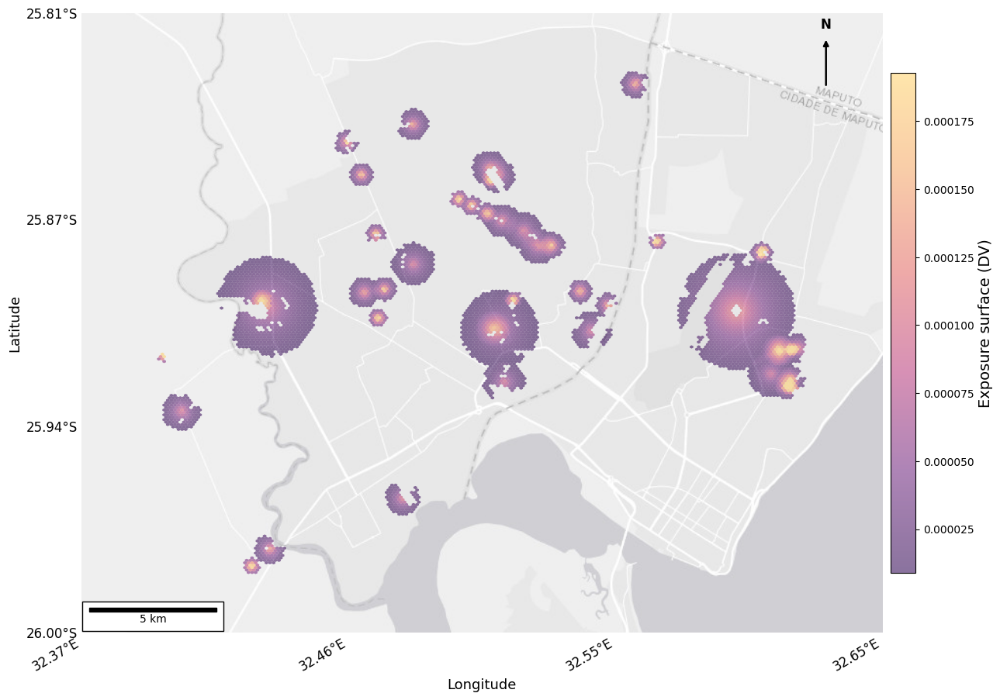

Grid points plotted  : 40,003
99th percentile DV   : 0.000193
Output figure        :
/content/drive/MyDrive/Paper_3/Processing/DV/Revised/Maputo/Maputo_Exposure_Surface_2024_revised.png

Maputo 2016
Source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Maputo/maputo_grid30m_DV_2016_revised.csv
UTM: EPSG:32736


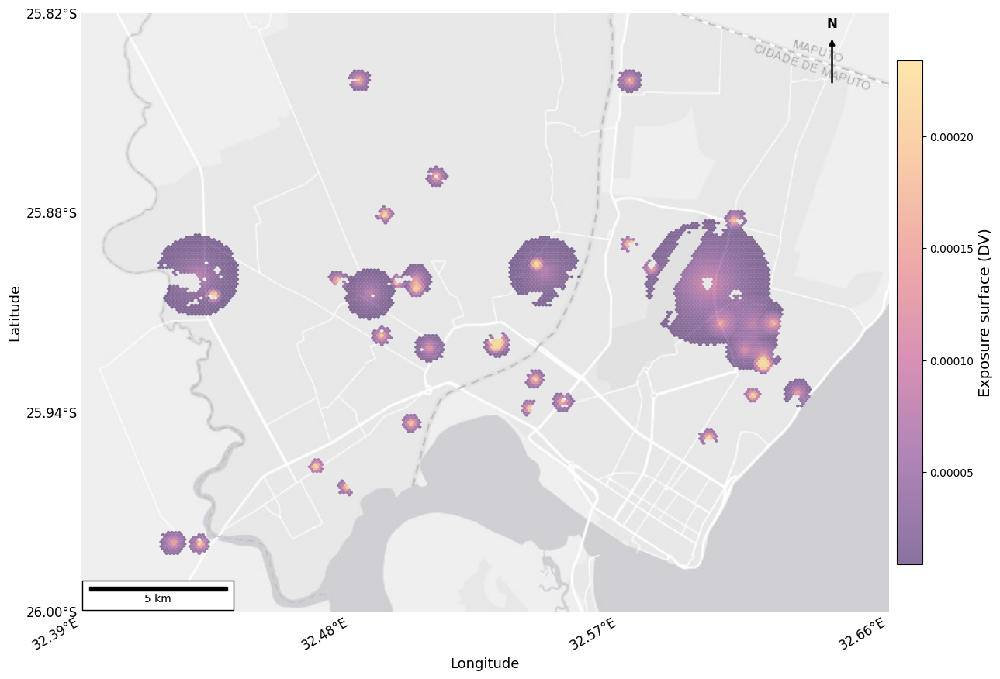

Grid points plotted  : 27,583
99th percentile DV   : 0.000234
Output figure        :
/content/drive/MyDrive/Paper_3/Processing/DV/Revised/Maputo/Maputo_Exposure_Surface_2016_revised.png

BOTH SURFACES COMPLETE
2024: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Maputo/Maputo_Exposure_Surface_2024_revised.png
2016: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Maputo/Maputo_Exposure_Surface_2016_revised.png


In [ ]:
# =============================================================================
# EXPOSURE SURFACE VISUALIZATION (REVISED DV) — BOTH YEARS
# Independent per-year colour scaling (each year clipped at its own q99)
# =============================================================================

import os
import math
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.font_manager as fm
import contextily as ctx
from pyproj import CRS, Transformer
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

warnings.filterwarnings("ignore")

# =============================================================================
# CONFIG
# =============================================================================
CITY = "Maputo"
YEARS = [2024, 2016]

# Per-city extent padding overrides (default 0.12/0.12 if not listed here).
# Dakar: deliberately elongated vertical pad (0.22) for its peninsula geography.
PAD_OVERRIDES = {
    "Dakar": {"padx_factor": 0.12, "pady_factor": 0.22},
}
padx_factor, pady_factor = PAD_OVERRIDES.get(CITY, {"padx_factor": 0.12, "pady_factor": 0.12}).values()

IN_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
OUT_DIR = IN_DIR
os.makedirs(OUT_DIR, exist_ok=True)

FIGSIZE = (13, 13)
DPI = 300

# =============================================================================
# COLOURMAP
# =============================================================================
exposure_cmap = mcolors.LinearSegmentedColormap.from_list(
    "Exposure",
    ["#2b004f", "#6a1f7a", "#b63679", "#e16462", "#f4a261", "#ffd166"],
    N=256
)

# =============================================================================
# CRS HELPERS
# =============================================================================
CRS_WEB = CRS.from_epsg(3857)
CRS_WGS = CRS.from_epsg(4326)

def utm_epsg(lon, lat):
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"

# =============================================================================
# NORTH ARROW
# =============================================================================
def add_north_arrow(ax):
    ax.annotate("", xy=(0.93, 0.96), xytext=(0.93, 0.88), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"))
    ax.text(0.93, 0.97, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=12, fontweight="bold")

# =============================================================================
# SCALE BAR
# =============================================================================
def add_scalebar(ax):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(ax.transData, 5000, "5 km", "lower left", pad=0.6,
                                color="black", frameon=True, size_vertical=150,
                                fontproperties=fontprops)
    ax.add_artist(scalebar)

# =============================================================================
# LAT/LON TICKS
# =============================================================================
def format_lon(x):
    return f"{abs(x):.2f}°{'E' if x >= 0 else 'W'}"

def format_lat(y):
    return f"{abs(y):.2f}°{'N' if y >= 0 else 'S'}"

def add_latlon_ticks(ax):
    transformer = Transformer.from_crs(CRS_WEB, CRS_WGS, always_xy=True)
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    xticks = np.linspace(xmin, xmax, 4)
    yticks = np.linspace(ymin, ymax, 4)
    yc = (ymin + ymax) / 2
    xc = (xmin + xmax) / 2
    lons = [transformer.transform(x, yc)[0] for x in xticks]
    lats = [transformer.transform(xc, y)[1] for y in yticks]
    ax.set_xticks(xticks)
    ax.set_xticklabels([format_lon(i) for i in lons], fontsize=12, rotation=30, ha="right")
    ax.set_yticks(yticks)
    ax.set_yticklabels([format_lat(i) for i in lats], fontsize=12)
    ax.set_xlabel("Longitude", fontsize=13)
    ax.set_ylabel("Latitude", fontsize=13)

# =============================================================================
# PLOT ONE YEAR
# =============================================================================
def plot_year(city, year, in_dir, out_dir, padx_f, pady_f):
    csv = os.path.join(in_dir, f"{city.lower()}_grid30m_DV_{year}_revised.csv")
    out_fig = os.path.join(out_dir, f"{city}_Exposure_Surface_{year}_revised.png")

    print("=" * 70)
    print(f"{city} {year}")
    print("=" * 70)
    print(f"Source: {csv}")

    df = pd.read_csv(csv)
    required = ["longitude", "latitude", "DV_log1p"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")

    epsg = utm_epsg(df.longitude.mean(), df.latitude.mean())
    print("UTM:", epsg)

    gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude),
                            crs="EPSG:4326").to_crs(epsg)
    gdf["DV_raw"] = np.expm1(gdf["DV_log1p"])
    gdf = gdf.to_crs(3857)

    nz = gdf[gdf["DV_raw"] > 0].copy()
    q99 = nz["DV_raw"].quantile(0.99)   # independent per-year scale
    nz["DV_plot"] = nz["DV_raw"].clip(upper=q99)
    if len(nz) > 120000:
        nz = nz.sample(120000, random_state=42)

    xmin, ymin, xmax, ymax = nz.total_bounds
    padx = (xmax - xmin) * padx_f
    pady = (ymax - ymin) * pady_f

    fig, ax = plt.subplots(figsize=FIGSIZE)
    ax.set_xlim(xmin - padx, xmax + padx)
    ax.set_ylim(ymin - pady, ymax + pady)
    ax.set_aspect("equal", adjustable="box")

    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas, attribution=False, zorder=0)

    hb = ax.hexbin(nz.geometry.x.values, nz.geometry.y.values, C=nz["DV_plot"].values,
                    reduce_C_function=np.mean, gridsize=180, mincnt=1, linewidths=0,
                    alpha=0.55, cmap=exposure_cmap, zorder=5)

    cbar = fig.colorbar(hb, ax=ax, fraction=0.03, pad=0.01)
    cbar.set_label("Exposure surface (DV)", fontsize=14)

    add_north_arrow(ax)
    add_scalebar(ax)
    add_latlon_ticks(ax)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="both", length=0)

    plt.tight_layout()
    plt.savefig(out_fig, dpi=DPI, bbox_inches="tight", facecolor="white")
    plt.show()

    print(f"Grid points plotted  : {len(nz):,}")
    print(f"99th percentile DV   : {q99:.6f}")
    print(f"Output figure        :\n{out_fig}\n")

    return out_fig

# =============================================================================
# RUN BOTH YEARS
# =============================================================================
outputs = {}
for year in YEARS:
    outputs[year] = plot_year(CITY, year, IN_DIR, OUT_DIR, padx_factor, pady_factor)

print("=" * 70)
print("BOTH SURFACES COMPLETE")
print("=" * 70)
for year, path in outputs.items():
    print(f"{year}: {path}")

Nairobi

In [ ]:
# =============================================================================
# REVISED DIFFERENTIAL-SPREAD DV GENERATION (Nairobi 2024)
# 500m² FLOOR + SIZE-SCALED RADIUS (200m-2km) + STEEPENED DECAY (H_HALF=0.30)
# COMBINED — CONFIG, KMZ LOADING, KD-TREE, DV COMPUTATION & SAVE
# =============================================================================

import os
import zipfile
import tempfile
import warnings
import time
import fiona
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

# --- CONFIGURATION ------------------------------------------------------

CITY = "Nairobi"
YEAR = 2024

EPSG = 32737   # confirmed
BETA = 0.42    # confirmed

KMZ_FILE  = f"/content/drive/MyDrive/Paper_3/Sites/{YEAR}/{CITY}/{CITY}_{YEAR}.kmz"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"

OUT_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
os.makedirs(OUT_DIR, exist_ok=True)
OUTPUT_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_{YEAR}_revised.csv")

# 2024 reads the original master grid
GRID_CSV = f"/content/drive/MyDrive/Results_2/Data_2024/Processed/{CITY}/Final_datasets/{CITY.lower()}_grid30m_master_merged_withDV.csv"

# --- LOCKED DESIGN PARAMETERS (same for all cities/years) -------------------

MIN_AREA_M2    = 500.0
MIN_RADIUS_M   = 200.0
MAX_RADIUS_M   = 2000.0
CAP_PERCENTILE = 99
H_HALF         = 0.30
TAU            = 1.0

# --- CITY-SPECIFIC AREA CAP (pooled 2016+2024, from site CSVs) --------------

print("=" * 70)
print(f"Computing area cap for {CITY} (pooled 2016+2024)...")
print("=" * 70)

areas_pooled = []
for y in [2016, 2024]:
    sites_csv = pd.read_csv(f"{SITES_DIR}/{y}/{CITY}/{CITY}_{y}_sites.csv")
    sites_csv = sites_csv.dropna(subset=["area"])
    sites_csv = sites_csv[sites_csv["area"] >= MIN_AREA_M2]
    areas_pooled.extend(sites_csv["area"].values)

AREA_CAP_M2 = np.percentile(areas_pooled, CAP_PERCENTILE)
print(f"{CITY}: n={len(areas_pooled):,} qualifying sites (both years), "
      f"p{CAP_PERCENTILE} area cap = {AREA_CAP_M2:,.1f} m² ({AREA_CAP_M2/10000:.2f} ha)")

# --- LOAD & PROJECT KMZ (target year's own site geometries) -----------------

print("\n" + "=" * 70)
print("Loading KMZ...")
print("=" * 70)

tmpdir = tempfile.mkdtemp()
with zipfile.ZipFile(KMZ_FILE, "r") as z:
    z.extractall(tmpdir)

kml_files = [
    os.path.join(root, f)
    for root, _, files in os.walk(tmpdir)
    for f in files if f.lower().endswith(".kml")
]
if not kml_files:
    raise RuntimeError("No KML file found inside KMZ.")

kml_file = kml_files[0]
print(f"KML found: {kml_file}")

fiona.drvsupport.supported_drivers["KML"] = "rw"
sites = gpd.read_file(kml_file, driver="KML").set_geometry("geometry")

if sites.crs is None:
    sites = sites.set_crs(4326)
sites = sites.to_crs(EPSG)
print(f"Loaded {len(sites)} geometries, projected to EPSG:{EPSG}")

# --- EXPLODE, FILTER TO POLYGONS, COMPUTE AREA -------------------------

sites = sites.explode(index_parts=False).reset_index(drop=True)
sites = sites[sites.geometry.type.isin(["Polygon", "MultiPolygon"])].copy()
print(f"Polygon features: {len(sites)}")
if len(sites) == 0:
    raise RuntimeError("No polygons found.")

sites["area_m2"] = sites.geometry.area
sites = sites[np.isfinite(sites["area_m2"]) & (sites["area_m2"] > 0)].copy()
print(f"Valid polygons: {len(sites)}")

# --- 500 m² FLOOR -------------------------------------------------------

n_before_floor = len(sites)
sites = sites[sites["area_m2"] >= MIN_AREA_M2].copy()
print(f"Sites >= {MIN_AREA_M2:.0f} m²: {len(sites)} (dropped {n_before_floor - len(sites)} smaller sites)")
if len(sites) == 0:
    raise RuntimeError(f"No sites >= {MIN_AREA_M2:.0f} m² for {CITY} {YEAR}.")

# --- CENTROIDS -----------------------------------------------------------

sites["centroid"] = sites.geometry.centroid
site_pts = sites.set_geometry("centroid").copy()

site_xy = np.column_stack((site_pts.geometry.x.values, site_pts.geometry.y.values))
areas = site_pts["area_m2"].to_numpy(dtype=float)

# --- SIZE-SCALED RADII (200m-2km, city-specific p99 cap) -------------------

print("\nComputing size-scaled radii...")

capped_area = np.minimum(areas, AREA_CAP_M2)
score = (np.log(capped_area) - np.log(MIN_AREA_M2)) / (np.log(AREA_CAP_M2) - np.log(MIN_AREA_M2))
r_j = MIN_RADIUS_M + (MAX_RADIUS_M - MIN_RADIUS_M) * score

lambda_j = np.log(2.0) / (H_HALF * r_j)
K_j = (lambda_j ** 2) / (2.0 * np.pi)
mass_j = np.power(np.maximum(areas, 1.0), BETA)

# --- KD-TREE ---------------------------------------------------------------

tree = cKDTree(site_xy)
R_QUERY = TAU * np.max(r_j)
print("\nKD Tree constructed.")

# --- LOAD GRID COORDINATES --------------------------------------------------

print("\nLoading grid coordinates...")
print(f"Grid source: {GRID_CSV}")

grid = pd.read_csv(GRID_CSV, usecols=["grid_point", "longitude", "latitude"]).dropna()
print(f"Grid points: {len(grid):,}")

grid_gdf = gpd.GeoDataFrame(
    grid,
    geometry=gpd.points_from_xy(grid.longitude, grid.latitude),
    crs=4326
).to_crs(EPSG)

points_xy = np.column_stack((grid_gdf.geometry.x.values, grid_gdf.geometry.y.values))

# --- SETUP DIAGNOSTICS -------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY (site/grid setup)")
print("=" * 70)
print(f"City / year                : {CITY} {YEAR}")
print(f"EPSG / BETA (per-city)     : {EPSG} / {BETA}")
print(f"Min area / min radius      : {MIN_AREA_M2:.0f} m² / {MIN_RADIUS_M:.0f} m")
print(f"Area cap (p{CAP_PERCENTILE}) / max radius : {AREA_CAP_M2:,.1f} m² / {MAX_RADIUS_M:.0f} m")
print(f"H_HALF / TAU                : {H_HALF} / {TAU}")
print(f"Sites retained (>= floor)   : {len(site_pts):,}")
print(f"Grid points                 : {len(points_xy):,}")
print(f"Mean site area (m²)         : {areas.mean():.2f}")
print(f"Median site area (m²)       : {np.median(areas):.2f}")
print("\nSize-scaled radius summary (m)")
print(pd.Series(r_j).describe())
print(f"\nMaximum search radius: {R_QUERY:.2f} m")

# =============================================================================
# DV COMPUTATION — every 30 m grid point + save
# =============================================================================

print("\n" + "=" * 70)
print("Computing DV at 30 m grid points...")
print("=" * 70)

t0 = time.time()

N = len(points_xy)
DV_pts = np.zeros(N, dtype=np.float64)
overlap_pts = np.zeros(N, dtype=np.int16)

BATCH_SIZE = 5000
print(f"Grid points : {N:,}")
print(f"Batch size  : {BATCH_SIZE:,}")
print(f"Total batches: {int(np.ceil(N / BATCH_SIZE))}")

for start in range(0, N, BATCH_SIZE):
    end = min(start + BATCH_SIZE, N)
    batch_points = points_xy[start:end]

    neighbour_lists = tree.query_ball_point(batch_points, r=R_QUERY)

    for i, neighbours in enumerate(neighbour_lists):
        if len(neighbours) == 0:
            continue

        pt = batch_points[i]
        cand_xy = site_xy[neighbours]

        dx = cand_xy[:, 0] - pt[0]
        dy = cand_xy[:, 1] - pt[1]
        d = np.sqrt(dx * dx + dy * dy)

        r_local = r_j[neighbours]
        keep = d <= (TAU * r_local)
        if not np.any(keep):
            continue

        d = d[keep]
        lam = lambda_j[neighbours][keep]
        K = K_j[neighbours][keep]
        mass = mass_j[neighbours][keep]

        contrib = mass * K * np.exp(-lam * d)
        DV_pts[start + i] = contrib.sum()
        overlap_pts[start + i] = keep.sum()

    processed = end
    pct = processed / N * 100
    elapsed = time.time() - t0
    rate = processed / elapsed
    remaining = (N - processed) / rate if rate > 0 else np.nan
    print(f"{processed:>8,} / {N:,} ({pct:5.1f}%)   Elapsed: {elapsed:6.1f}s   ETA: {remaining:6.1f}s")

print("\nFinished DV computation.")

DV_log = np.log1p(DV_pts)

print(f"Non-zero grid points : {(DV_pts>0).sum():,}")
print(f"Maximum overlap      : {overlap_pts.max()}")
print(f"Maximum DV           : {DV_pts.max():.6f}")
print(f"Mean DV              : {DV_pts.mean():.6f}")
print(f"Median DV            : {np.median(DV_pts):.6f}")

# --- BUILD & SAVE OUTPUT ------------------------------------------------------

print("\n" + "=" * 70)
print("Saving output...")
print("=" * 70)

out_df = pd.DataFrame({
    "grid_point": grid["grid_point"].values,
    "longitude": grid["longitude"].values,
    "latitude": grid["latitude"].values,
    "DV_hex_diffspread": DV_pts,
    "DV_log1p": DV_log,
    "n_sites": overlap_pts
}).sort_values("grid_point").reset_index(drop=True)

os.makedirs(OUT_DIR, exist_ok=True)
out_df.to_csv(OUTPUT_CSV, index=False)

runtime = time.time() - t0
pct_list = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

print("\n" + "=" * 70)
print("OUTPUT SUMMARY")
print("=" * 70)
print(f"Output file:\n{OUTPUT_CSV}\n")
print(f"Rows written                : {len(out_df):,}")
print(f"Non-zero DV                 : {(out_df.DV_hex_diffspread>0).sum():,}")
print(f"Zero DV                     : {(out_df.DV_hex_diffspread==0).sum():,}")
print(f"Maximum contributing sites  : {out_df.n_sites.max()}")
print(f"Mean contributing sites     : {out_df.n_sites[out_df.n_sites>0].mean():.2f}")

print("\nDV summary")
print(out_df["DV_hex_diffspread"].describe(percentiles=pct_list))

print("\nDV_log1p summary")
print(out_df["DV_log1p"].describe(percentiles=pct_list))

print(f"\nProcessing time : {runtime:.1f} seconds")
print("\n✓ Revised DV successfully generated.")
print(f"\nSaved to:\n{OUTPUT_CSV}")

Computing area cap for Nairobi (pooled 2016+2024)...
Nairobi: n=134 qualifying sites (both years), p99 area cap = 178,318.1 m² (17.83 ha)

Loading KMZ...
KML found: /tmp/tmp0o9wuep8/doc.kml
Loaded 689 geometries, projected to EPSG:32737
Polygon features: 689
Valid polygons: 689
Sites >= 500 m²: 72 (dropped 617 smaller sites)

Computing size-scaled radii...

KD Tree constructed.

Loading grid coordinates...
Grid source: /content/drive/MyDrive/Results_2/Data_2024/Processed/Nairobi/Final_datasets/nairobi_grid30m_master_merged_withDV.csv
Grid points: 196,145

SUMMARY (site/grid setup)
City / year                : Nairobi 2024
EPSG / BETA (per-city)     : 32737 / 0.42
Min area / min radius      : 500 m² / 200 m
Area cap (p99) / max radius : 178,318.1 m² / 2000 m
H_HALF / TAU                : 0.3 / 1.0
Sites retained (>= floor)   : 72
Grid points                 : 196,145
Mean site area (m²)         : 6882.73
Median site area (m²)       : 1123.04

Size-scaled radius summary (m)
count      72

In [ ]:
# =============================================================================
# REVISED DIFFERENTIAL-SPREAD DV GENERATION (Nairobi 2016)
# 500m² FLOOR + SIZE-SCALED RADIUS (200m-2km) + STEEPENED DECAY (H_HALF=0.30)
# COMBINED — CONFIG, KMZ LOADING, KD-TREE, DV COMPUTATION & SAVE
# =============================================================================

import os
import zipfile
import tempfile
import warnings
import time
import fiona
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

# --- CONFIGURATION ------------------------------------------------------

CITY = "Nairobi"
YEAR = 2016

EPSG = 32737   # confirmed, matches Nairobi 2024
BETA = 0.42    # confirmed, matches Nairobi 2024

KMZ_FILE  = f"/content/drive/MyDrive/Paper_3/Sites/{YEAR}/{CITY}/{CITY}_{YEAR}.kmz"
SITES_DIR = "/content/drive/MyDrive/Paper_3/Sites"

OUT_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
os.makedirs(OUT_DIR, exist_ok=True)
OUTPUT_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_{YEAR}_revised.csv")

# 2016 reuses 2024's own REVISED output as the grid source (same grid_point set)
GRID_CSV = os.path.join(OUT_DIR, f"{CITY.lower()}_grid30m_DV_2024_revised.csv")
if not os.path.exists(GRID_CSV):
    raise RuntimeError(
        f"2024 revised output not found for {CITY} — run YEAR=2024 first, "
        f"since 2016 reuses its grid for cross-year consistency."
    )

# --- LOCKED DESIGN PARAMETERS (same for all cities/years) -------------------

MIN_AREA_M2    = 500.0
MIN_RADIUS_M   = 200.0
MAX_RADIUS_M   = 2000.0
CAP_PERCENTILE = 99
H_HALF         = 0.30
TAU            = 1.0

# --- CITY-SPECIFIC AREA CAP (pooled 2016+2024, from site CSVs) --------------

print("=" * 70)
print(f"Computing area cap for {CITY} (pooled 2016+2024)...")
print("=" * 70)

areas_pooled = []
for y in [2016, 2024]:
    sites_csv = pd.read_csv(f"{SITES_DIR}/{y}/{CITY}/{CITY}_{y}_sites.csv")
    sites_csv = sites_csv.dropna(subset=["area"])
    sites_csv = sites_csv[sites_csv["area"] >= MIN_AREA_M2]
    areas_pooled.extend(sites_csv["area"].values)

AREA_CAP_M2 = np.percentile(areas_pooled, CAP_PERCENTILE)
print(f"{CITY}: n={len(areas_pooled):,} qualifying sites (both years), "
      f"p{CAP_PERCENTILE} area cap = {AREA_CAP_M2:,.1f} m² ({AREA_CAP_M2/10000:.2f} ha)")

# --- LOAD & PROJECT KMZ (target year's own site geometries) -----------------

print("\n" + "=" * 70)
print("Loading KMZ...")
print("=" * 70)

tmpdir = tempfile.mkdtemp()
with zipfile.ZipFile(KMZ_FILE, "r") as z:
    z.extractall(tmpdir)

kml_files = [
    os.path.join(root, f)
    for root, _, files in os.walk(tmpdir)
    for f in files if f.lower().endswith(".kml")
]
if not kml_files:
    raise RuntimeError("No KML file found inside KMZ.")

kml_file = kml_files[0]
print(f"KML found: {kml_file}")

fiona.drvsupport.supported_drivers["KML"] = "rw"
sites = gpd.read_file(kml_file, driver="KML").set_geometry("geometry")

if sites.crs is None:
    sites = sites.set_crs(4326)
sites = sites.to_crs(EPSG)
print(f"Loaded {len(sites)} geometries, projected to EPSG:{EPSG}")

# --- EXPLODE, FILTER TO POLYGONS, COMPUTE AREA -------------------------

sites = sites.explode(index_parts=False).reset_index(drop=True)
sites = sites[sites.geometry.type.isin(["Polygon", "MultiPolygon"])].copy()
print(f"Polygon features: {len(sites)}")
if len(sites) == 0:
    raise RuntimeError("No polygons found.")

sites["area_m2"] = sites.geometry.area
sites = sites[np.isfinite(sites["area_m2"]) & (sites["area_m2"] > 0)].copy()
print(f"Valid polygons: {len(sites)}")

# --- 500 m² FLOOR -------------------------------------------------------

n_before_floor = len(sites)
sites = sites[sites["area_m2"] >= MIN_AREA_M2].copy()
print(f"Sites >= {MIN_AREA_M2:.0f} m²: {len(sites)} (dropped {n_before_floor - len(sites)} smaller sites)")
if len(sites) == 0:
    raise RuntimeError(f"No sites >= {MIN_AREA_M2:.0f} m² for {CITY} {YEAR}.")

# --- CENTROIDS -----------------------------------------------------------

sites["centroid"] = sites.geometry.centroid
site_pts = sites.set_geometry("centroid").copy()

site_xy = np.column_stack((site_pts.geometry.x.values, site_pts.geometry.y.values))
areas = site_pts["area_m2"].to_numpy(dtype=float)

# --- SIZE-SCALED RADII (200m-2km, city-specific p99 cap) -------------------

print("\nComputing size-scaled radii...")

capped_area = np.minimum(areas, AREA_CAP_M2)
score = (np.log(capped_area) - np.log(MIN_AREA_M2)) / (np.log(AREA_CAP_M2) - np.log(MIN_AREA_M2))
r_j = MIN_RADIUS_M + (MAX_RADIUS_M - MIN_RADIUS_M) * score

lambda_j = np.log(2.0) / (H_HALF * r_j)
K_j = (lambda_j ** 2) / (2.0 * np.pi)
mass_j = np.power(np.maximum(areas, 1.0), BETA)

# --- KD-TREE ---------------------------------------------------------------

tree = cKDTree(site_xy)
R_QUERY = TAU * np.max(r_j)
print("\nKD Tree constructed.")

# --- LOAD GRID COORDINATES --------------------------------------------------

print("\nLoading grid coordinates...")
print(f"Grid source: {GRID_CSV}")

grid = pd.read_csv(GRID_CSV, usecols=["grid_point", "longitude", "latitude"]).dropna()
print(f"Grid points: {len(grid):,}")

grid_gdf = gpd.GeoDataFrame(
    grid,
    geometry=gpd.points_from_xy(grid.longitude, grid.latitude),
    crs=4326
).to_crs(EPSG)

points_xy = np.column_stack((grid_gdf.geometry.x.values, grid_gdf.geometry.y.values))

# --- SETUP DIAGNOSTICS -------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY (site/grid setup)")
print("=" * 70)
print(f"City / year                : {CITY} {YEAR}")
print(f"EPSG / BETA (per-city)     : {EPSG} / {BETA}")
print(f"Min area / min radius      : {MIN_AREA_M2:.0f} m² / {MIN_RADIUS_M:.0f} m")
print(f"Area cap (p{CAP_PERCENTILE}) / max radius : {AREA_CAP_M2:,.1f} m² / {MAX_RADIUS_M:.0f} m")
print(f"H_HALF / TAU                : {H_HALF} / {TAU}")
print(f"Sites retained (>= floor)   : {len(site_pts):,}")
print(f"Grid points                 : {len(points_xy):,}")
print(f"Mean site area (m²)         : {areas.mean():.2f}")
print(f"Median site area (m²)       : {np.median(areas):.2f}")
print("\nSize-scaled radius summary (m)")
print(pd.Series(r_j).describe())
print(f"\nMaximum search radius: {R_QUERY:.2f} m")

# =============================================================================
# DV COMPUTATION — every 30 m grid point + save
# =============================================================================

print("\n" + "=" * 70)
print("Computing DV at 30 m grid points...")
print("=" * 70)

t0 = time.time()

N = len(points_xy)
DV_pts = np.zeros(N, dtype=np.float64)
overlap_pts = np.zeros(N, dtype=np.int16)

BATCH_SIZE = 5000
print(f"Grid points : {N:,}")
print(f"Batch size  : {BATCH_SIZE:,}")
print(f"Total batches: {int(np.ceil(N / BATCH_SIZE))}")

for start in range(0, N, BATCH_SIZE):
    end = min(start + BATCH_SIZE, N)
    batch_points = points_xy[start:end]

    neighbour_lists = tree.query_ball_point(batch_points, r=R_QUERY)

    for i, neighbours in enumerate(neighbour_lists):
        if len(neighbours) == 0:
            continue

        pt = batch_points[i]
        cand_xy = site_xy[neighbours]

        dx = cand_xy[:, 0] - pt[0]
        dy = cand_xy[:, 1] - pt[1]
        d = np.sqrt(dx * dx + dy * dy)

        r_local = r_j[neighbours]
        keep = d <= (TAU * r_local)
        if not np.any(keep):
            continue

        d = d[keep]
        lam = lambda_j[neighbours][keep]
        K = K_j[neighbours][keep]
        mass = mass_j[neighbours][keep]

        contrib = mass * K * np.exp(-lam * d)
        DV_pts[start + i] = contrib.sum()
        overlap_pts[start + i] = keep.sum()

    processed = end
    pct = processed / N * 100
    elapsed = time.time() - t0
    rate = processed / elapsed
    remaining = (N - processed) / rate if rate > 0 else np.nan
    print(f"{processed:>8,} / {N:,} ({pct:5.1f}%)   Elapsed: {elapsed:6.1f}s   ETA: {remaining:6.1f}s")

print("\nFinished DV computation.")

DV_log = np.log1p(DV_pts)

print(f"Non-zero grid points : {(DV_pts>0).sum():,}")
print(f"Maximum overlap      : {overlap_pts.max()}")
print(f"Maximum DV           : {DV_pts.max():.6f}")
print(f"Mean DV              : {DV_pts.mean():.6f}")
print(f"Median DV            : {np.median(DV_pts):.6f}")

# --- BUILD & SAVE OUTPUT ------------------------------------------------------

print("\n" + "=" * 70)
print("Saving output...")
print("=" * 70)

out_df = pd.DataFrame({
    "grid_point": grid["grid_point"].values,
    "longitude": grid["longitude"].values,
    "latitude": grid["latitude"].values,
    "DV_hex_diffspread": DV_pts,
    "DV_log1p": DV_log,
    "n_sites": overlap_pts
}).sort_values("grid_point").reset_index(drop=True)

os.makedirs(OUT_DIR, exist_ok=True)
out_df.to_csv(OUTPUT_CSV, index=False)

runtime = time.time() - t0
pct_list = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

print("\n" + "=" * 70)
print("OUTPUT SUMMARY")
print("=" * 70)
print(f"Output file:\n{OUTPUT_CSV}\n")
print(f"Rows written                : {len(out_df):,}")
print(f"Non-zero DV                 : {(out_df.DV_hex_diffspread>0).sum():,}")
print(f"Zero DV                     : {(out_df.DV_hex_diffspread==0).sum():,}")
print(f"Maximum contributing sites  : {out_df.n_sites.max()}")
print(f"Mean contributing sites     : {out_df.n_sites[out_df.n_sites>0].mean():.2f}")

print("\nDV summary")
print(out_df["DV_hex_diffspread"].describe(percentiles=pct_list))

print("\nDV_log1p summary")
print(out_df["DV_log1p"].describe(percentiles=pct_list))

print(f"\nProcessing time : {runtime:.1f} seconds")
print("\n✓ Revised DV successfully generated.")
print(f"\nSaved to:\n{OUTPUT_CSV}")

Computing area cap for Nairobi (pooled 2016+2024)...
Nairobi: n=134 qualifying sites (both years), p99 area cap = 178,318.1 m² (17.83 ha)

Loading KMZ...
KML found: /tmp/tmpra6yf8cj/doc.kml
Loaded 778 geometries, projected to EPSG:32737
Polygon features: 778
Valid polygons: 778
Sites >= 500 m²: 62 (dropped 716 smaller sites)

Computing size-scaled radii...

KD Tree constructed.

Loading grid coordinates...
Grid source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Nairobi/nairobi_grid30m_DV_2024_revised.csv
Grid points: 196,145

SUMMARY (site/grid setup)
City / year                : Nairobi 2016
EPSG / BETA (per-city)     : 32737 / 0.42
Min area / min radius      : 500 m² / 200 m
Area cap (p99) / max radius : 178,318.1 m² / 2000 m
H_HALF / TAU                : 0.3 / 1.0
Sites retained (>= floor)   : 62
Grid points                 : 196,145
Mean site area (m²)         : 5893.48
Median site area (m²)       : 1157.52

Size-scaled radius summary (m)
count      62.000000
mean      52

Nairobi 2024
Source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Nairobi/nairobi_grid30m_DV_2024_revised.csv
UTM: EPSG:32737


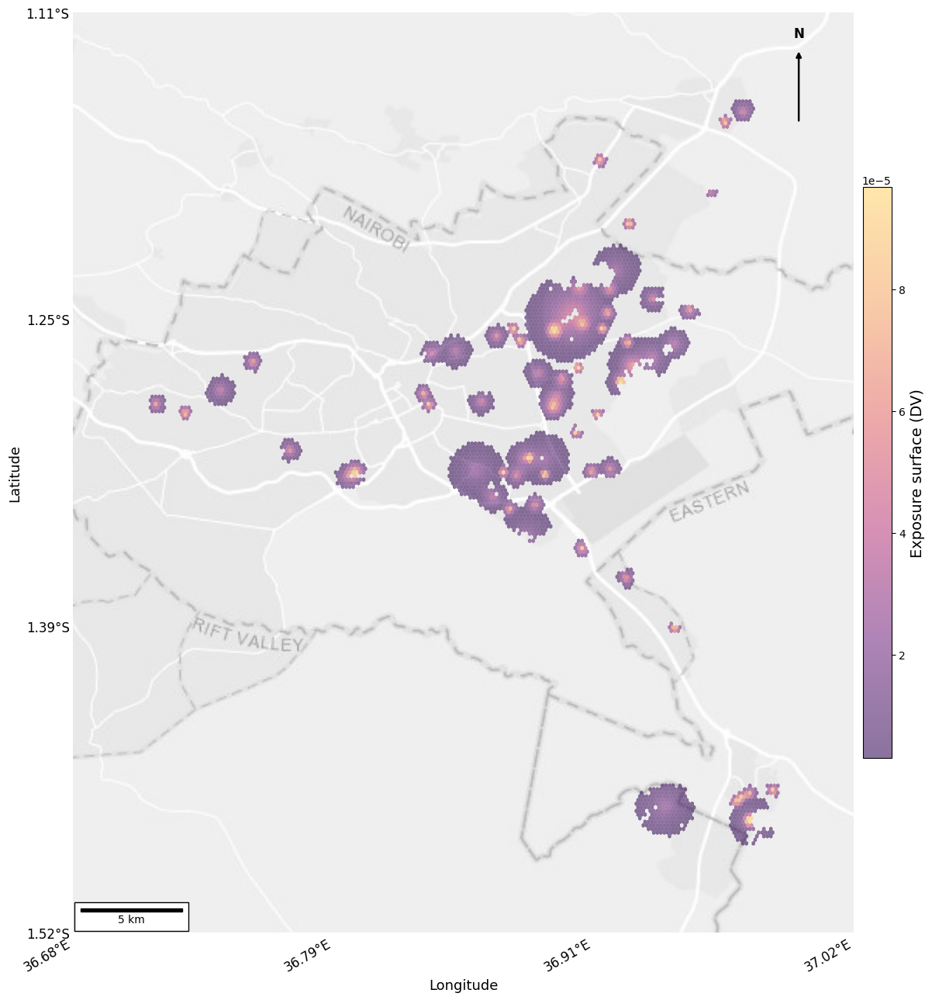

Grid points plotted  : 33,948
99th percentile DV   : 0.000097
Output figure        :
/content/drive/MyDrive/Paper_3/Processing/DV/Revised/Nairobi/Nairobi_Exposure_Surface_2024_revised.png

Nairobi 2016
Source: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Nairobi/nairobi_grid30m_DV_2016_revised.csv
UTM: EPSG:32737


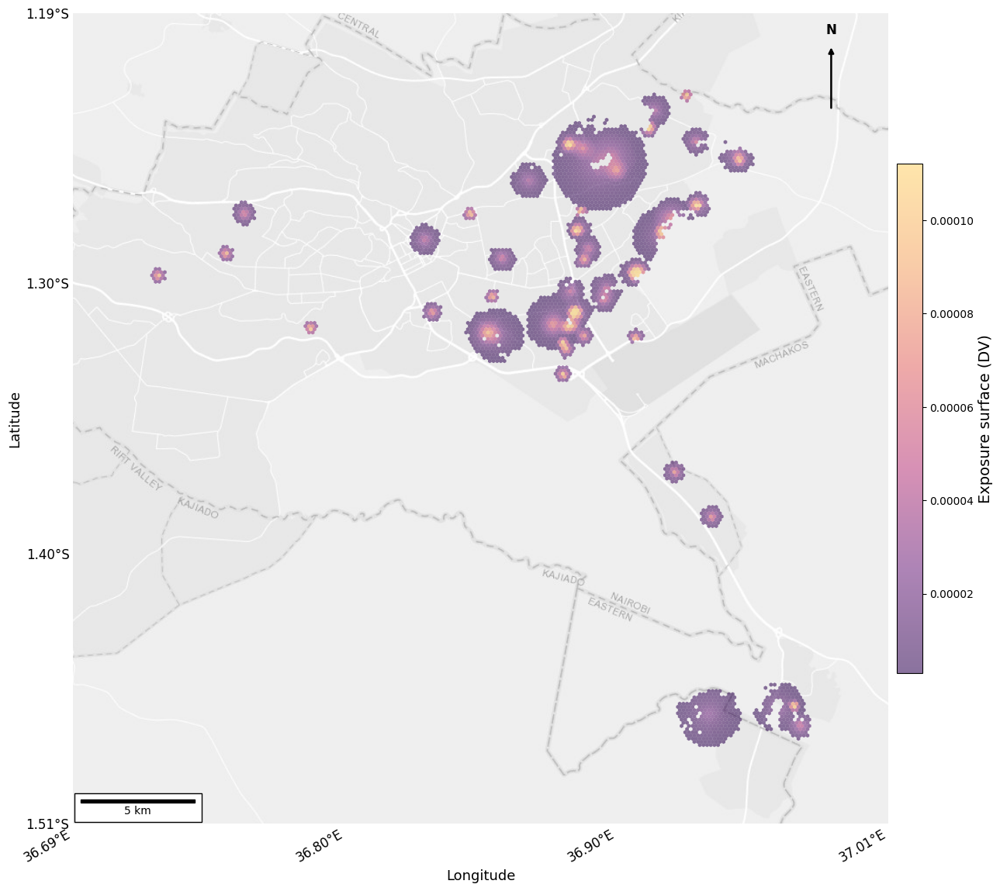

Grid points plotted  : 25,286
99th percentile DV   : 0.000112
Output figure        :
/content/drive/MyDrive/Paper_3/Processing/DV/Revised/Nairobi/Nairobi_Exposure_Surface_2016_revised.png

BOTH SURFACES COMPLETE
2024: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Nairobi/Nairobi_Exposure_Surface_2024_revised.png
2016: /content/drive/MyDrive/Paper_3/Processing/DV/Revised/Nairobi/Nairobi_Exposure_Surface_2016_revised.png


In [ ]:
# =============================================================================
# EXPOSURE SURFACE VISUALIZATION (REVISED DV) — BOTH YEARS
# Independent per-year colour scaling (each year clipped at its own q99)
# =============================================================================

import os
import math
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.font_manager as fm
import contextily as ctx
from pyproj import CRS, Transformer
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar

warnings.filterwarnings("ignore")

# =============================================================================
# CONFIG
# =============================================================================
CITY = "Nairobi"
YEARS = [2024, 2016]

# Per-city extent padding overrides (default 0.12/0.12 if not listed here).
# Dakar: deliberately elongated vertical pad (0.22) for its peninsula geography.
PAD_OVERRIDES = {
    "Dakar": {"padx_factor": 0.12, "pady_factor": 0.22},
}
padx_factor, pady_factor = PAD_OVERRIDES.get(CITY, {"padx_factor": 0.12, "pady_factor": 0.12}).values()

IN_DIR = f"/content/drive/MyDrive/Paper_3/Processing/DV/Revised/{CITY}"
OUT_DIR = IN_DIR
os.makedirs(OUT_DIR, exist_ok=True)

FIGSIZE = (13, 13)
DPI = 300

# =============================================================================
# COLOURMAP
# =============================================================================
exposure_cmap = mcolors.LinearSegmentedColormap.from_list(
    "Exposure",
    ["#2b004f", "#6a1f7a", "#b63679", "#e16462", "#f4a261", "#ffd166"],
    N=256
)

# =============================================================================
# CRS HELPERS
# =============================================================================
CRS_WEB = CRS.from_epsg(3857)
CRS_WGS = CRS.from_epsg(4326)

def utm_epsg(lon, lat):
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"

# =============================================================================
# NORTH ARROW
# =============================================================================
def add_north_arrow(ax):
    ax.annotate("", xy=(0.93, 0.96), xytext=(0.93, 0.88), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", lw=1.8, color="black"))
    ax.text(0.93, 0.97, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=12, fontweight="bold")

# =============================================================================
# SCALE BAR
# =============================================================================
def add_scalebar(ax):
    fontprops = fm.FontProperties(size=10)
    scalebar = AnchoredSizeBar(ax.transData, 5000, "5 km", "lower left", pad=0.6,
                                color="black", frameon=True, size_vertical=150,
                                fontproperties=fontprops)
    ax.add_artist(scalebar)

# =============================================================================
# LAT/LON TICKS
# =============================================================================
def format_lon(x):
    return f"{abs(x):.2f}°{'E' if x >= 0 else 'W'}"

def format_lat(y):
    return f"{abs(y):.2f}°{'N' if y >= 0 else 'S'}"

def add_latlon_ticks(ax):
    transformer = Transformer.from_crs(CRS_WEB, CRS_WGS, always_xy=True)
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    xticks = np.linspace(xmin, xmax, 4)
    yticks = np.linspace(ymin, ymax, 4)
    yc = (ymin + ymax) / 2
    xc = (xmin + xmax) / 2
    lons = [transformer.transform(x, yc)[0] for x in xticks]
    lats = [transformer.transform(xc, y)[1] for y in yticks]
    ax.set_xticks(xticks)
    ax.set_xticklabels([format_lon(i) for i in lons], fontsize=12, rotation=30, ha="right")
    ax.set_yticks(yticks)
    ax.set_yticklabels([format_lat(i) for i in lats], fontsize=12)
    ax.set_xlabel("Longitude", fontsize=13)
    ax.set_ylabel("Latitude", fontsize=13)

# =============================================================================
# PLOT ONE YEAR
# =============================================================================
def plot_year(city, year, in_dir, out_dir, padx_f, pady_f):
    csv = os.path.join(in_dir, f"{city.lower()}_grid30m_DV_{year}_revised.csv")
    out_fig = os.path.join(out_dir, f"{city}_Exposure_Surface_{year}_revised.png")

    print("=" * 70)
    print(f"{city} {year}")
    print("=" * 70)
    print(f"Source: {csv}")

    df = pd.read_csv(csv)
    required = ["longitude", "latitude", "DV_log1p"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")

    epsg = utm_epsg(df.longitude.mean(), df.latitude.mean())
    print("UTM:", epsg)

    gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude),
                            crs="EPSG:4326").to_crs(epsg)
    gdf["DV_raw"] = np.expm1(gdf["DV_log1p"])
    gdf = gdf.to_crs(3857)

    nz = gdf[gdf["DV_raw"] > 0].copy()
    q99 = nz["DV_raw"].quantile(0.99)   # independent per-year scale
    nz["DV_plot"] = nz["DV_raw"].clip(upper=q99)
    if len(nz) > 120000:
        nz = nz.sample(120000, random_state=42)

    xmin, ymin, xmax, ymax = nz.total_bounds
    padx = (xmax - xmin) * padx_f
    pady = (ymax - ymin) * pady_f

    fig, ax = plt.subplots(figsize=FIGSIZE)
    ax.set_xlim(xmin - padx, xmax + padx)
    ax.set_ylim(ymin - pady, ymax + pady)
    ax.set_aspect("equal", adjustable="box")

    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas, attribution=False, zorder=0)

    hb = ax.hexbin(nz.geometry.x.values, nz.geometry.y.values, C=nz["DV_plot"].values,
                    reduce_C_function=np.mean, gridsize=180, mincnt=1, linewidths=0,
                    alpha=0.55, cmap=exposure_cmap, zorder=5)

    cbar = fig.colorbar(hb, ax=ax, fraction=0.03, pad=0.01)
    cbar.set_label("Exposure surface (DV)", fontsize=14)

    add_north_arrow(ax)
    add_scalebar(ax)
    add_latlon_ticks(ax)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", which="both", length=0)

    plt.tight_layout()
    plt.savefig(out_fig, dpi=DPI, bbox_inches="tight", facecolor="white")
    plt.show()

    print(f"Grid points plotted  : {len(nz):,}")
    print(f"99th percentile DV   : {q99:.6f}")
    print(f"Output figure        :\n{out_fig}\n")

    return out_fig

# =============================================================================
# RUN BOTH YEARS
# =============================================================================
outputs = {}
for year in YEARS:
    outputs[year] = plot_year(CITY, year, IN_DIR, OUT_DIR, padx_factor, pady_factor)

print("=" * 70)
print("BOTH SURFACES COMPLETE")
print("=" * 70)
for year, path in outputs.items():
    print(f"{year}: {path}")